# 운영 패턴 · 시술 수익 · 인터뷰 검증

헤어살롱 본점 · 분석 기간 **2025-01-01 ~ 2026-08-23**
원천은 `data/processed/*.parquet` — 원본 엑셀은 다시 파싱하지 않는다.

---

## 01번 노트북에서 그대로 가져온 규칙

1. **시간대·요일은 `use_dt`(이용일시) 기준.** `done_dt`(이용완료일시)는 정산 배치 시각이라 금지.
   예외는 ⑤-3 한 곳뿐이고, 거기서는 "정산 시각"이라는 사실 자체를 검증하는 것이 목적이다.
2. **`reservations` 와 `hands_all` 을 concat 하지 않는다.**
3. **고객 식별은 `cust_key`**, **금액은 `paid`**.
4. **시술 분류는 `menu_category.csv` 단일 기준**, 대표시술 우선순위도 01번과 동일:
   `탈색 > 펌 > 염색 > 컷 > 클리닉 > 스타일링 > 기타 > 확인필요` (`비시술` 제외).
5. 헬퍼(`rep_cat`, `lead_bin`, `slot`, `DUR_H` …)는 01번 로직을 **글자 그대로 복사**했다.
   §0-5에 **01번 대조 게이트**를 두어, 값이 하나라도 어긋나면 노트북이 그 자리에서 멈춘다.

---

## 이 노트북에서 새로 내린 정의

| 항목 | 정의 | 비고 |
|---|---|---|
| **취소 후 재방문** | **단방향** — 취소 예약의 `use_dt` **이후** 45일 이내의 완료 방문 | ⚠️ 01번의 ±45일을 수정. 아래 ①-1 참조 |
| 진짜 손실 | 45일 내 재방문 없음 **그리고** 취소 시점이 방문 6시간 미만 전 | 자리를 메울 수 없었고 고객도 안 돌아온 건 |
| 요일 정규화 | 요일별 합계 ÷ **그 요일의 영업일 수**(완료 건이 1건 이상 있는 날) | 달력 기준 요일 수도 병기 |
| 시간대 유형 | 포화 / 저효율 / 공백(구조적·수요) | ③에서 판정 규칙 명시 |
| 방학 | 여름 6/20~8/31, 겨울 12/20~2/28 | ⑤-5. 대학 학사일정 통상 범위 |
| 무비자 기간 | 2025-09 ~ 2026-06 | ⑤-4, ⑤-7 그래프에 음영 표시 |
| 사장님 기준 소요시간 | 뿌리탈색 계열 4.5h / 그 외 탈색 8h / 펌 2.5h / 염색 70분 / 컷 40분 | ⑤-2 민감도. 01번 가정은 탈색 일괄 3.5h |

---

## 읽을 때 주의

* **표본 30건 미만인 행에는 `⚠소표본` 표시**를 붙였다. 과대해석하지 말 것.
* 이 노트북의 문장은 전부 **상관**이다. "A 때문에 B"가 아니라 "A와 B가 같이 움직인다"로 적었다.
  원장님께 그대로 옮길 수 있는 표현을 쓴 것이다.
* 숫자는 반올림해서 보기 좋게 만들지 않았다. 나온 그대로다.

In [1]:
# ── 0-1. 환경 설정 (01번과 동일) ──────────────────────────────────────────────
import sys, os, re, platform, warnings, subprocess, itertools
from pathlib import Path

import pandas as pd, numpy as np
import matplotlib, matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns
from IPython import get_ipython
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 80)
pd.set_option("display.max_rows", 250)

## 0-2. 한글 폰트

폰트를 먼저 잡지 않으면 **이후 모든 그래프의 한글이 네모(tofu)로 깨진다.**
OS를 감지해 설치된 한글 폰트를 찾고, 없으면 나눔고딕 설치를 시도한 뒤 폰트 캐시를 새로 만든다.

In [2]:
# ── 0-2. 한글 폰트 (01번과 동일) ──────────────────────────────────────────────
CANDIDATES = {
    "Windows": ["Malgun Gothic", "NanumGothic", "NanumBarunGothic", "Noto Sans KR", "Gulim", "Batang"],
    "Darwin":  ["AppleGothic", "Apple SD Gothic Neo", "NanumGothic", "Noto Sans KR"],
    "Linux":   ["NanumGothic", "NanumBarunGothic", "Noto Sans CJK KR", "Noto Sans KR", "UnDotum"],
}

def _installed():
    return {f.name for f in fm.fontManager.ttflist}

def _rebuild_font_cache():
    try:
        fm._load_fontmanager(try_read_cache=False)      # mpl >= 3.5
        return True
    except Exception:
        pass
    try:
        fm._rebuild()
        return True
    except Exception:
        return False

def _try_install_nanum():
    try:
        if platform.system() == "Linux":
            subprocess.run(["apt-get", "install", "-y", "fonts-nanum"], check=False,
                           stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL, timeout=300)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "koreanize-matplotlib"],
                       check=False, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL, timeout=300)
        import koreanize_matplotlib  # noqa: F401
    except Exception as e:
        print("  나눔고딕 자동 설치 실패:", type(e).__name__, e)
    _rebuild_font_cache()

_avail = _installed()
_want  = CANDIDATES.get(platform.system(), CANDIDATES["Linux"])
KFONT  = next((f for f in _want if f in _avail), None)
if KFONT is None:
    print("설치된 한글 폰트를 찾지 못했다 → 나눔고딕 설치 시도")
    _try_install_nanum()
    _avail = _installed()
    KFONT  = next((f for f in _want if f in _avail), None)
if KFONT is None:
    raise RuntimeError("한글 폰트를 확보하지 못했다. Linux: apt-get install -y fonts-nanum / 기타: pip install koreanize-matplotlib")

sns.set_theme(style="whitegrid", font=KFONT, rc={"axes.unicode_minus": False})
# seaborn 이 rcParams 를 통째로 덮어쓰므로 폰트 설정은 반드시 그 뒤에 다시 적용한다
plt.rcParams["font.family"]        = KFONT
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"]         = 110
plt.rcParams["savefig.bbox"]       = "tight"
plt.rcParams["axes.grid"]          = True
plt.rcParams["grid.alpha"]         = 0.3

In [3]:
# ── 0-3. 표 정렬 교정 (01번과 동일) ───────────────────────────────────────────
# pandas 기본 HTML 표는 헤더에만 text-align:right 를 넣고 데이터 셀은 왼쪽에 둔다.
# 한글 컬럼명이 길면 값이 한 칸 밀려 보인다. 인라인 style 로 컬럼 단위 정렬을 맞춘다.
_PAD = "padding:3px 10px; white-space:nowrap;"

def _numlike(col):
    if pd.api.types.is_numeric_dtype(col):
        return True
    v = col.dropna().astype(str)
    if len(v) == 0:
        return False
    return bool(v.str.fullmatch(r"[\d,.\-+%]+").mean() > 0.7)

def _aligned_html(obj):
    df = obj.to_frame() if isinstance(obj, pd.Series) else obj
    aligns = ["right" if _numlike(df[c]) else "left" for c in df.columns]
    html = df.to_html(na_rep="")
    head, sep, body = html.partition("<tbody>")
    if not sep:
        return html
    head = head.replace('<tr style="text-align: right;">', "<tr>")

    def _head_row(m):
        k = [0]
        def sub(_):
            j = k[0]; k[0] += 1
            a = "left" if j == 0 else (aligns[j - 1] if j - 1 < len(aligns) else "left")
            return f'<th style="text-align:{a}; {_PAD} background:#f2f2f2;">'
        return re.sub(r"<th>", sub, m.group(0))

    def _body_row(m):
        row = re.sub(r"<th>", f'<th style="text-align:left; {_PAD}">', m.group(0))
        k = [0]
        def sub(_):
            j = k[0]; k[0] += 1
            return f'<td style="text-align:{aligns[j] if j < len(aligns) else "right"}; {_PAD}">'
        return re.sub(r"<td>", sub, row)

    head = re.sub(r"<tr>.*?</tr>", _head_row, head, flags=re.S)
    body = re.sub(r"<tr>.*?</tr>", _body_row, body, flags=re.S)
    return head + sep + body

_ip = get_ipython()
if _ip is not None:
    _f = _ip.display_formatter.formatters["text/html"]
    _f.for_type(pd.DataFrame, _aligned_html)
    _f.for_type(pd.Series, _aligned_html)

def tbl(df, caption=None):
    if caption:
        display(Markdown(f"**{caption}**"))
    display(df)

def pct(x, nd=2):  return f"{x*100:.{nd}f}%"
def won(x):        return f"{x:,.0f}"
def small(n, thr=30):  return "⚠소표본" if n < thr else ""

## 0-4. 데이터 로딩과 01번 헬퍼 복사

01번 노트북의 `§0-2 ~ §0-4` 를 그대로 옮겼다. **값이 01번과 달라지면 그 자체가 버그**이므로
다음 셀(§0-5)에서 01번 결과와 하나씩 대조하고, 어긋나면 `AssertionError` 로 멈춘다.

외국어 메뉴(네이버 자동번역 표기)는 표·차트·print 에 **대응 한국어 메뉴명 + 언어 꼬리표**로 보인다 — `한국어 메뉴명 (중국어)` · `한국어 메뉴명 (일본어)` · `한국어 메뉴명 (영어)`. 꼬리표는 표기에 쓰인 문자로 정한다 — 가나가 있으면 일본어, 한자만 있으면 중국어, 알파벳이면 영어 (메뉴 언어별 분석은 중국어·일본어를 한 그룹으로 본다 — 꼬리표는 표시용이다). 대응은 `menu_category.csv` 의 `menu_ko`, 표시 함수는 데이터 로딩 셀의 `mdisp()`. **계산·정렬·집계는 원래 메뉴명으로 한다.**

In [4]:
# ── 0-4. 로딩 + 01번 헬퍼 (로직 동일) ─────────────────────────────────────────
PROC = Path(os.environ.get("SALON_OUT", "../data/processed"))
if not PROC.exists():
    PROC = Path("data/processed")
assert PROC.exists(), f"processed 폴더를 찾지 못했다: {PROC.resolve()}"

R      = pd.read_parquet(PROC / "reservations.parquet")
L      = pd.read_parquet(PROC / "menu_lines.parquet")
H      = pd.read_parquet(PROC / "hands_all.parquet")
CATMAP = pd.read_csv(PROC / "menu_category.csv", encoding="utf-8-sig")
PRICE  = pd.read_parquet(PROC / "price_catalog.parquet")

# ── 화면 표시용 메뉴 이름 ─────────────────────────────────────────────────────
# 외국어 메뉴(네이버 자동번역 표기)는 menu_category.csv 의 menu_ko(대응 한국어 메뉴) + 언어 꼬리표로 보인다.
# 계산·정렬·집계·필터는 원래 메뉴명으로 하고, 표·차트·print 에 내기 직전에만 mdisp() 로 바꾼다.
# 언어 꼬리표는 표기에 쓰인 문자로 정한다 — 한글이 있으면 한국어, 가나가 있으면 일본어, 한자만 있으면 중국어,
# 알파벳이면 영어. (메뉴 언어별 분석은 중국어·일본어를 한 그룹으로 본다 — 꼬리표는 표시용이다.)
def _menu_lang(s):
    if re.search(r"[가-힣]", s):            return "한국어"
    if re.search("[぀-ゟ゠-ヿ]", s):        return "일본어"
    if re.search("[一-鿿]", s):             return "중국어"
    if re.search(r"[A-Za-z]", s):           return "영어"
    return "기타"

_mdt = CATMAP[["menu", "menu_ko"]].assign(lang=CATMAP.menu.map(_menu_lang))
_mdt["disp"] = [m if lg == "한국어" else f"{k} ({lg})" for m, k, lg in zip(_mdt.menu, _mdt.menu_ko, _mdt.lang)]
assert _mdt.disp.is_unique, "표시용 메뉴 이름이 겹친다 — menu_category.csv 의 menu_ko 를 확인할 것"
MENU_DISP = dict(zip(_mdt.menu, _mdt.disp))

def mdisp(m):
    """메뉴명 → 화면 표시 이름. 목록 밖 값은 그대로 돌려준다."""
    return MENU_DISP.get(m, m)

# --- 01번 §0-4 와 동일 ---
PRIORITY = ["탈색", "펌", "염색", "컷", "클리닉", "스타일링", "기타", "확인필요"]
CORE5    = ["탈색", "펌", "염색", "컷", "클리닉"]
EXCLUDE  = ["비시술"]
DUR_H    = {"탈색": 3.5, "펌": 2.5, "염색": 70/60, "컷": 40/60,
            "클리닉": 0.0, "스타일링": 0.0, "기타": 0.0, "확인필요": 0.0}

_cat_of  = CATMAP.set_index("menu")["category"].to_dict()
_free_of = CATMAP.set_index("menu")["is_free"].to_dict()

LX = L.copy()
LX["category"] = LX.menu.map(_cat_of)
LX["is_free"]  = LX.menu.map(_free_of).astype(int)
assert LX.category.notna().all(), "카테고리 매핑 실패 라인 존재"
LX = LX[~LX.category.isin(EXCLUDE)].copy()
LX["dur_h"] = LX.category.map(DUR_H)

_p = {c: i for i, c in enumerate(PRIORITY)}
_rep = (LX.assign(_o=LX.category.map(_p))
          .sort_values(["예약번호", "_o"])
          .drop_duplicates("예약번호")
          .set_index("예약번호")["category"])
R["rep_cat"] = R.예약번호.map(_rep)

_attr = R.set_index("예약번호")[["use_dt", "req_dt", "status", "designer", "channel",
                                 "cust_key", "ym", "dow", "hour", "paid", "lead_h", "rep_cat"]]
LX = LX.join(_attr, on="예약번호")

DOW_KO = ["월", "화", "수", "목", "금", "토", "일"]
LEAD_EDGES  = [-np.inf, 6, 24, 72, 168, 336, np.inf]
LEAD_LABELS = ["6시간 미만", "6~24시간", "1~3일", "3~7일", "1~2주", "2주 이상"]
SLOT_ORDER  = ["10~12시", "13~15시", "16~18시", "19~20시"]

def _slot(h):
    if 10 <= h <= 12: return "10~12시"
    if 13 <= h <= 15: return "13~15시"
    if 16 <= h <= 18: return "16~18시"
    if 19 <= h <= 20: return "19~20시"
    return "기타"

R["dow_ko"]   = R.dow.map(lambda i: DOW_KO[i])
R["slot"]     = R.hour.map(_slot)
R["lead_bin"] = pd.cut(R.lead_h, bins=LEAD_EDGES, labels=LEAD_LABELS, right=False)
R["same_day"] = R.use_dt.dt.normalize() == R.req_dt.dt.normalize()
R["date"]     = R.use_dt.dt.normalize()
LX["dow_ko"]  = LX.dow.map(lambda i: DOW_KO[i])
LX["slot"]    = LX.hour.map(_slot)

DONE = R[R.status == "이용완료"].copy()
CANC = R[R.status == "취소"].copy()

# 고객 단위 (01번 §5-0 과 동일)
_first_row = (DONE.sort_values("use_dt").drop_duplicates("cust_key", keep="first")
                  .set_index("cust_key")[["use_dt", "paid", "dow_ko", "rep_cat", "designer", "channel"]]
                  .rename(columns={"use_dt": "첫방문일", "paid": "첫방문paid", "dow_ko": "첫방문요일",
                                   "rep_cat": "첫방문시술", "designer": "첫디자이너", "channel": "첫채널"}))
_cust_agg = DONE.groupby("cust_key").agg(방문횟수=("예약번호", "size"), 누적지출=("paid", "sum"))
CUST = _first_row.join(_cust_agg)
CUST["재방문"]   = CUST.방문횟수 >= 2
CUST["3회이상"] = CUST.방문횟수 >= 3

# 인접 완료 방문 쌍 (01번 ④ 와 동일)
_v = (DONE.dropna(subset=["rep_cat"]).sort_values(["cust_key", "use_dt"])
          [["cust_key", "use_dt", "rep_cat", "designer", "paid"]].reset_index(drop=True))
_v["prev_cat"]      = _v.groupby("cust_key").rep_cat.shift(1)
_v["prev_designer"] = _v.groupby("cust_key").designer.shift(1)
_v["prev_dt"]       = _v.groupby("cust_key").use_dt.shift(1)
_v["prev_paid"]     = _v.groupby("cust_key").paid.shift(1)
PAIRS = _v.dropna(subset=["prev_cat"]).copy()
PAIRS["gap_days"] = (PAIRS.use_dt - PAIRS.prev_dt).dt.total_seconds() / 86400

print(f"reservations {len(R):,}행 · menu_lines {len(L):,}행(비시술 제외 {len(LX):,}) · hands_all {len(H):,}행")
print(f"DONE {len(DONE):,} · CANC {len(CANC):,} · CUST {len(CUST):,}명 · PAIRS {len(PAIRS):,}쌍")

reservations 4,281행 · menu_lines 7,165행(비시술 제외 7,162) · hands_all 3,643행
DONE 2,732 · CANC 1,542 · CUST 1,557명 · PAIRS 1,175쌍


## 0-5. 01번 대조 게이트 — 여기서 어긋나면 멈춘다

01번 노트북에서 나온 값을 상수로 박아 두고 이 노트북에서 재계산한 값과 대조한다.
**하나라도 다르면 `AssertionError`** 로 즉시 멈춘다. 이후 분석을 믿을 수 없기 때문이다.

In [5]:
# ── 0-5. 01번 대조 게이트 ─────────────────────────────────────────────────────
_lb01 = (R.groupby("lead_bin", observed=False)
           .agg(n=("예약번호", "size"), c=("status", lambda s: int((s == "취소").sum()))))
_lb01["r"] = _lb01.c / _lb01.n * 100

_util_src = DONE[DONE.use_dt.dt.year == 2026].copy()
_res_dur  = LX.groupby("예약번호").dur_h.sum()
_util_src["dur_line"] = _util_src.예약번호.map(_res_dur).fillna(0.0)
_dd01 = _util_src.groupby(["designer", "date"]).dur_line.sum()
_u01  = _dd01.groupby("designer").agg(["size", "sum"])
_u01["가동률"] = _u01["sum"] / _u01["size"] / 10 * 100

_sorted01 = CUST.누적지출.sort_values(ascending=False).values
_cum01    = _sorted01.cumsum() / _sorted01.sum()

GATE = [
    ("전체 예약 건수",        len(R),                                4281),
    ("완료 건수",             len(DONE),                             2732),
    ("취소 건수",             len(CANC),                             1542),
    ("완료 총매출",           int(DONE.paid.sum()),                  308_975_650),
    ("객단가 중앙값",         float(DONE.paid.median()),             100_000.0),
    ("표면 취소율(%)",        round((R.status == "취소").mean()*100, 2), 36.02),
    ("고유 고객(완료)",       len(CUST),                             1557),
    ("고유 고객(전체)",       R.cust_key.nunique(),                  1895),
    ("메뉴 라인(비시술 제외)", len(LX),                               7162),
    ("대표시술 미부여",        int(R.rep_cat.isna().sum()),            0),
    ("전이 쌍",               len(PAIRS),                            1175),
    ("재방문 간격 중앙값(일)", round(float(PAIRS.gap_days.median()), 2), 41.02),
    ("상위20% 매출 비중(%)",  round(float(_cum01[int(np.ceil(len(_sorted01)*0.2))-1]*100), 2), 46.41),
    ("리드타임취소율 6h미만(%)", round(float(_lb01.loc["6시간 미만","r"]), 2), 14.87),
    ("리드타임취소율 6~24h(%)", round(float(_lb01.loc["6~24시간","r"]), 2), 27.22),
    ("리드타임취소율 1~3일(%)", round(float(_lb01.loc["1~3일","r"]), 2),   36.10),
    ("리드타임취소율 3~7일(%)", round(float(_lb01.loc["3~7일","r"]), 2),   44.61),
    ("리드타임취소율 1~2주(%)", round(float(_lb01.loc["1~2주","r"]), 2),   55.60),
    ("리드타임취소율 2주+(%)",  round(float(_lb01.loc["2주 이상","r"]), 2), 69.44),
    ("가동률 가온(%)",      round(float(_u01.loc["가온 대표원장","가동률"]), 2), 78.33),
    ("가동률 나래(%)",        round(float(_u01.loc["나래 디자이너","가동률"]), 2),   69.81),
    ("가동률 다솜(%)",        round(float(_u01.loc["다솜 디자이너","가동률"]), 2),   45.86),
]
_g = pd.DataFrame(GATE, columns=["지표", "이번 노트북", "01번 값"])
_g["일치"] = np.where(_g["이번 노트북"] == _g["01번 값"], "OK", "★불일치")
tbl(_g, "0-5 01번 노트북 대조 게이트")

_bad = _g[_g.일치 != "OK"]
assert _bad.empty, f"01번과 값이 다르다. 원인 규명 전까지 진행 불가:\n{_bad.to_string()}"
print(f"대조 {len(_g)}개 항목 전부 일치. 이후 분석은 01번과 같은 기반 위에 있다.")

**0-5 01번 노트북 대조 게이트**

,지표,이번 노트북,01번 값,일치
0,전체 예약 건수,4.281000e+03,4.281000e+03,OK
1,완료 건수,2.732000e+03,2.732000e+03,OK
2,취소 건수,1.542000e+03,1.542000e+03,OK
3,완료 총매출,3.089756e+08,3.089756e+08,OK
4,객단가 중앙값,1.000000e+05,1.000000e+05,OK
5,표면 취소율(%),3.602000e+01,3.602000e+01,OK
6,고유 고객(완료),1.557000e+03,1.557000e+03,OK
7,고유 고객(전체),1.895000e+03,1.895000e+03,OK
8,메뉴 라인(비시술 제외),7.162000e+03,7.162000e+03,OK
9,대표시술 미부여,0.000000e+00,0.000000e+00,OK


대조 22개 항목 전부 일치. 이후 분석은 01번과 같은 기반 위에 있다.


---
# ① 취소는 이탈이 아니라 "일정 마찰"인가

01번에서 "취소 후 45일 내 방문"을 냈지만 그것만으로는 약하다.
여러 각도에서 **뒷받침하거나 반박**한다.

먼저 **가공하지 않은 단순 취소율**부터 놓고 시작한다. 이후 ①-a ~ ①-e 에서
이 숫자를 여러 각도로 쪼개고, ①-d 에서 "실제로 잃은 예약"까지 좁힌다.

## ①-0 단순 취소율 — 가공하지 않은 기본값

**분모를 무엇으로 잡느냐에 따라 값이 달라진다.** 세 가지를 모두 내고, 이 노트북이 쓰는 것을 명시한다.

| 정의 | 식 | 쓰임 |
|---|---|---|
| **단순 취소율 (채택)** | 취소 ÷ **전체 예약** | 01번과 같은 정의. 이 노트북의 기본값 |
| 노쇼 포함 취소율 | (취소 + 노쇼) ÷ 전체 예약 | 노쇼도 자리를 비운 것으로 볼 때 |
| 종료건 기준 취소율 | 취소 ÷ (취소 + 이용완료) | 아직 안 끝난 `확정` 건을 분모에서 뺄 때 |

⚠️ **`확정` 6건**은 아직 이용도 취소도 되지 않은 미결 예약이고, **`노쇼` 1건**은 별도 상태다.
세 정의의 차이는 0.1%p 미만이라 결론은 바뀌지 않지만, 다른 자료와 대조할 때 분모를 맞춰야 한다.

In [6]:
# ── ①-0a 단순 취소율 ─────────────────────────────────────────────────────────
_st = R.status.value_counts().rename("건수").to_frame()
_st["비중(%)"] = _st.건수 / len(R) * 100
_st.loc["합계"] = [len(R), 100.0]
_st["건수"] = _st.건수.astype(int)   # 합계 행 때문에 float 으로 밀리는 것 방지
tbl(_st.round(2), f"①-0a 예약 상태 분포 — 전체 {len(R):,}건 ({R.use_dt.min():%Y-%m-%d} ~ {R.use_dt.max():%Y-%m-%d})")

_n_cancel = int((R.status == "취소").sum())
_n_noshow = int((R.status == "노쇼").sum())
_n_done   = int((R.status == "이용완료").sum())
_rates = pd.DataFrame([
    {"정의": "단순 취소율 (채택)",   "분자": _n_cancel,             "분모": len(R),
     "취소율(%)": _n_cancel / len(R) * 100,                     "식": "취소 / 전체 예약"},
    {"정의": "노쇼 포함 취소율",     "분자": _n_cancel + _n_noshow, "분모": len(R),
     "취소율(%)": (_n_cancel + _n_noshow) / len(R) * 100,       "식": "(취소 + 노쇼) / 전체 예약"},
    {"정의": "종료건 기준 취소율",   "분자": _n_cancel,             "분모": _n_cancel + _n_done,
     "취소율(%)": _n_cancel / (_n_cancel + _n_done) * 100,      "식": "취소 / (취소 + 이용완료)"},
])
tbl(_rates.round(4), "①-0b 분모를 달리한 취소율 세 가지")

print(f"이 노트북이 쓰는 값 = 단순 취소율 {_n_cancel:,} / {len(R):,} = {_n_cancel/len(R)*100:.2f}%")
print(f"취소된 예약의 청구 예정 금액(paid) 합계: {CANC.paid.sum():,}원 "
      f"(완료 매출 {DONE.paid.sum():,}원의 {CANC.paid.sum()/DONE.paid.sum()*100:.2f}%)")
assert round(_n_cancel / len(R) * 100, 2) == 36.02, "01번 표면 취소율 36.02% 와 불일치"
print("01번 '표면 취소율 36.02%' 와 일치.")

**①-0a 예약 상태 분포 — 전체 4,281건 (2025-01-01 ~ 2026-08-23)**

,건수,비중(%)
status,,
이용완료,2732,63.82
취소,1542,36.02
확정,6,0.14
노쇼,1,0.02
합계,4281,100.00


**①-0b 분모를 달리한 취소율 세 가지**

,정의,분자,분모,취소율(%),식
0,단순 취소율 (채택),1542,4281,36.0196,취소 / 전체 예약
1,노쇼 포함 취소율,1543,4281,36.0430,(취소 + 노쇼) / 전체 예약
2,종료건 기준 취소율,1542,4274,36.0786,취소 / (취소 + 이용완료)


이 노트북이 쓰는 값 = 단순 취소율 1,542 / 4,281 = 36.02%
취소된 예약의 청구 예정 금액(paid) 합계: 178,971,000원 (완료 매출 308,975,650원의 57.92%)
01번 '표면 취소율 36.02%' 와 일치.


**①-0c 월별 단순 취소율 (use_dt 기준)**

,예약,취소,완료,취소율(%),연도,월
ym,,,,,,
2025-01,218,91,127,41.74,2025,1
2025-02,217,68,149,31.34,2025,2
2025-03,184,64,120,34.78,2025,3
2025-04,154,51,103,33.12,2025,4
2025-05,168,51,117,30.36,2025,5
2025-06,160,52,108,32.50,2025,6
2025-07,180,62,118,34.44,2025,7
2025-08,200,61,138,30.50,2025,8
2025-09,127,35,92,27.56,2025,9


**①-0d 연도별 단순 취소율 (2026년은 8월 23일까지)**

,개월수,예약,취소,취소율(%)
연도,,,,
2025,12,2328,799,34.32
2026,8,1953,743,38.04


월별 취소율 범위: 최저 27.56% (2025-09) ~ 최고 47.59% (2025-12)


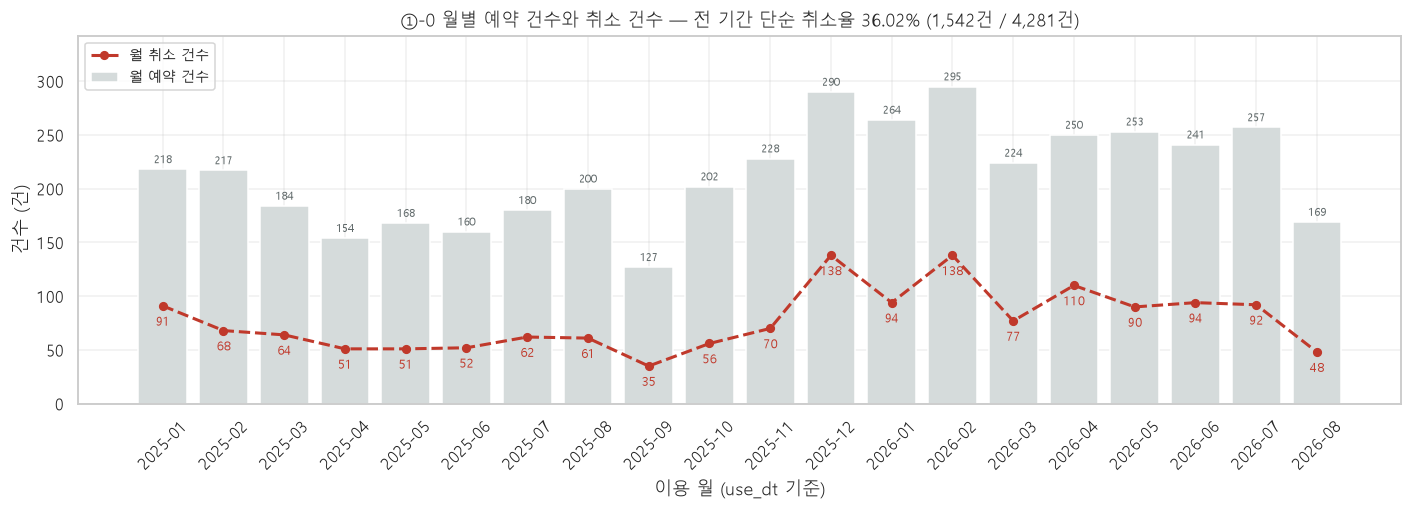

In [7]:
# ── ①-0c 월별 단순 취소율 ────────────────────────────────────────────────────
_mc = (R.groupby("ym")
         .agg(예약=("예약번호", "size"),
              취소=("status", lambda s: int((s == "취소").sum())),
              완료=("status", lambda s: int((s == "이용완료").sum()))))
_mc["취소율(%)"] = _mc.취소 / _mc.예약 * 100
_mc["연도"] = [p.year for p in _mc.index]
_mc["월"]   = [p.month for p in _mc.index]
tbl(_mc.round(2), "①-0c 월별 단순 취소율 (use_dt 기준)")

_yr = _mc.groupby("연도").agg(개월수=("예약", "size"), 예약=("예약", "sum"), 취소=("취소", "sum"))
_yr["취소율(%)"] = _yr.취소 / _yr.예약 * 100
tbl(_yr.round(2), "①-0d 연도별 단순 취소율 (2026년은 8월 23일까지)")
print(f"월별 취소율 범위: 최저 {_mc['취소율(%)'].min():.2f}% ({_mc['취소율(%)'].idxmin()}) ~ "
      f"최고 {_mc['취소율(%)'].max():.2f}% ({_mc['취소율(%)'].idxmax()})")

# 이중축(건수 + %)은 스케일이 달라 취소율 선이 예약 막대 위로 떠올라 오해를 부른다.
# 왼쪽 y축 하나(건수)로 통합하고, 취소는 같은 단위의 '건수' 점선으로 겹쳐 그린다.
# 취소율(%)은 바로 위 ①-0c 표에 있으므로 그래프에서는 뺀다.
fig, ax = plt.subplots(figsize=(13, 4.8))
_x = _mc.index.astype(str)
ax.bar(_x, _mc.예약, color="#d5dbdb", label="월 예약 건수", zorder=1)
ax.plot(_x, _mc.취소, color="#c0392b", marker="o", ms=5, lw=2.0, ls="--",
        label="월 취소 건수", zorder=3)
for i, (a_, c_) in enumerate(zip(_mc.예약, _mc.취소)):
    ax.annotate(f"{int(a_)}", (i, a_), textcoords="offset points", xytext=(0, 4),
                ha="center", fontsize=7.5, color="#616a6b")
    ax.annotate(f"{int(c_)}", (i, c_), textcoords="offset points", xytext=(0, -13),
                ha="center", fontsize=8, color="#c0392b")
ax.set_ylabel("건수 (건)")
ax.set_xlabel("이용 월 (use_dt 기준)")
ax.set_ylim(0, _mc.예약.max() * 1.16)
ax.tick_params(axis="x", rotation=45)
ax.set_title(f"①-0 월별 예약 건수와 취소 건수 — 전 기간 단순 취소율 "
             f"{_n_cancel/len(R)*100:.2f}% ({_n_cancel:,}건 / {len(R):,}건)")
ax.legend(loc="upper left", fontsize=9)
plt.tight_layout(); plt.show()

## ①-1 ⚠️ 정의 수정 — 01번의 ±45일은 틀렸다

01번은 취소 예약의 `use_dt` 를 중심으로 **앞뒤 45일**을 봤다.
그런데 **취소 이전의 방문은 그냥 원래 재방문 고객**이지, "취소했다가 다시 온" 것이 아니다.
취소가 일정 조정이었다는 주장을 뒷받침하려면 **취소 이후**만 봐야 한다.

```
01번 (틀림) : use_dt − 45일  ≤  완료 방문  ≤  use_dt + 45일
이번  (수정) :                use_dt  ≤  완료 방문  ≤  use_dt + 45일
```

아래에서 두 값을 나란히 내고, **이후 모든 계산은 단방향 기준**을 쓴다.

In [8]:
# ── ①-1 ±45일 vs 단방향 45일 ─────────────────────────────────────────────────
WINDOW_D = 45
_done_by_cust = {k: np.sort(v.values) for k, v in DONE.groupby("cust_key")["use_dt"]}

def _days_to_next_done(cust_key, use_dt):
    """취소 예약 use_dt 이후(같은 시각 포함) 첫 완료 방문까지의 일수. 없으면 NaN."""
    arr = _done_by_cust.get(cust_key)
    if arr is None:
        return np.nan
    i = np.searchsorted(arr, np.datetime64(use_dt), side="left")
    if i >= len(arr):
        return np.nan
    return (arr[i] - np.datetime64(use_dt)) / np.timedelta64(1, "D")

def _bidirectional(cust_key, use_dt):
    arr = _done_by_cust.get(cust_key)
    if arr is None:
        return False
    lo = np.datetime64(use_dt - pd.Timedelta(days=WINDOW_D))
    hi = np.datetime64(use_dt + pd.Timedelta(days=WINDOW_D))
    return np.searchsorted(arr, hi, side="right") > np.searchsorted(arr, lo, side="left")

CANC["days_to_next"] = [_days_to_next_done(k, d) for k, d in zip(CANC.cust_key, CANC.use_dt)]
CANC["revisit_fwd"]  = CANC.days_to_next <= WINDOW_D          # 단방향 (채택)
CANC["revisit_bi"]   = [_bidirectional(k, d) for k, d in zip(CANC.cust_key, CANC.use_dt)]  # 01번 방식
CANC["gap_h"]        = (CANC.use_dt - CANC.cancel_dt).dt.total_seconds() / 3600

_cmp = pd.DataFrame([
    {"기준": "01번 ±45일 (양방향)", "재방문 건수": int(CANC.revisit_bi.sum()),
     "재방문 비율(%)": CANC.revisit_bi.mean()*100,
     "순이탈 건수": int((~CANC.revisit_bi).sum()),
     "순이탈률(%)": (~CANC.revisit_bi).sum()/len(R)*100},
    {"기준": "이번 단방향 45일 (채택)", "재방문 건수": int(CANC.revisit_fwd.sum()),
     "재방문 비율(%)": CANC.revisit_fwd.mean()*100,
     "순이탈 건수": int((~CANC.revisit_fwd).sum()),
     "순이탈률(%)": (~CANC.revisit_fwd).sum()/len(R)*100},
])
tbl(_cmp.round(2), f"①-1 정의 변경 효과 — 취소 {len(CANC):,}건 기준")
_delta = int(CANC.revisit_bi.sum() - CANC.revisit_fwd.sum())
print(f"차이 {_delta}건 = 취소 '이전' 45일에만 방문이 있고 이후에는 없는 건.")
print("  이 건들은 원래 다니던 고객이 예약 하나를 취소하고 그 뒤로 안 온 경우이므로,")
print("  '취소했다가 다시 왔다'의 증거로 쓸 수 없다. 그래서 단방향으로 바꾼다.")
print(f"→ 채택값: 취소 후 45일 내 재방문 {CANC.revisit_fwd.mean()*100:.2f}% · "
      f"순이탈률 {(~CANC.revisit_fwd).sum()/len(R)*100:.2f}%")

**①-1 정의 변경 효과 — 취소 1,542건 기준**

,기준,재방문 건수,재방문 비율(%),순이탈 건수,순이탈률(%)
0,01번 ±45일 (양방향),1047,67.9,495,11.56
1,이번 단방향 45일 (채택),771,50.0,771,18.01


차이 276건 = 취소 '이전' 45일에만 방문이 있고 이후에는 없는 건.
  이 건들은 원래 다니던 고객이 예약 하나를 취소하고 그 뒤로 안 온 경우이므로,
  '취소했다가 다시 왔다'의 증거로 쓸 수 없다. 그래서 단방향으로 바꾼다.
→ 채택값: 취소 후 45일 내 재방문 50.00% · 순이탈률 18.01%


## ①-a 재예약 시차 분포

취소한 고객이 **그 다음 완료 방문까지 며칠** 걸렸는가.
7일 이내 재방문이 많다면 "날짜만 옮긴 것"의 직접 증거가 된다.
기준 시점은 취소 예약의 `use_dt`(원래 오기로 한 날)이다.

In [9]:
# ── ①-a 재예약 시차 ──────────────────────────────────────────────────────────
GAPB  = [0, 8, 15, 31, 46, 91, np.inf]
GAPL  = ["0~7일", "8~14일", "15~30일", "31~45일", "46~90일", "90일 초과"]
CANC["재예약시차"] = pd.cut(CANC.days_to_next, bins=GAPB, labels=GAPL, right=False)
_lag = CANC.재예약시차.value_counts().reindex(GAPL).fillna(0).astype(int).rename("건수").to_frame()
_lag.loc["없음 (이후 완료 방문 자체가 없음)"] = int(CANC.days_to_next.isna().sum())
_lag["비중(%)"]  = _lag.건수 / len(CANC) * 100
_lag["누적(%)"]  = _lag["비중(%)"].cumsum()
_lag["평균 paid"] = CANC.groupby("재예약시차").paid.mean().reindex(_lag.index)
tbl(_lag.round(2), f"①-a 취소 후 다음 완료 방문까지의 시차 — 취소 {len(CANC):,}건")

_w1 = (CANC.days_to_next <= 7).sum()
_w2 = (CANC.days_to_next <= 14).sum()
print(f"7일 이내 재방문  {_w1:,}건 ({_w1/len(CANC)*100:.2f}%)")
print(f"14일 이내 재방문 {_w2:,}건 ({_w2/len(CANC)*100:.2f}%)")
print(f"45일 이내 재방문 {int(CANC.revisit_fwd.sum()):,}건 ({CANC.revisit_fwd.mean()*100:.2f}%)")
print(f"이후 완료 방문 없음 {int(CANC.days_to_next.isna().sum()):,}건 "
      f"({CANC.days_to_next.isna().mean()*100:.2f}%)")

**①-a 취소 후 다음 완료 방문까지의 시차 — 취소 1,542건**

,건수,비중(%),누적(%),평균 paid
재예약시차,,,,
0~7일,659,42.74,42.74,112943.85
8~14일,57,3.70,46.43,87280.70
15~30일,34,2.20,48.64,87529.41
31~45일,21,1.36,50.00,92523.81
46~90일,53,3.44,53.44,97396.23
90일 초과,42,2.72,56.16,99309.52
없음 (이후 완료 방문 자체가 없음),676,43.84,100.00,


7일 이내 재방문  644건 (41.76%)
14일 이내 재방문 711건 (46.11%)
45일 이내 재방문 771건 (50.00%)
이후 완료 방문 없음 676건 (43.84%)


## ①-b 취소 → 재예약의 연속성

취소 건과 **그 직후 완료 건**을 1:1로 짝지어, 세 가지가 이어지는지 본다.

* 같은 **디자이너**를 다시 골랐는가
* 같은 **대표시술**을 다시 골랐는가
* **금액**이 비슷한가 (`paid` 차이)

셋이 다 높으면 "같은 시술을 같은 사람에게, 날짜만 옮긴 것"이라는 뜻이다.
45일 이내에 다음 완료 방문이 있는 취소 건만 대상이다.

In [10]:
# ── ①-b 연속성 ───────────────────────────────────────────────────────────────
_next_row = {}
for k, g in DONE.sort_values("use_dt").groupby("cust_key"):
    _next_row[k] = g[["use_dt", "designer", "rep_cat", "paid"]].values

def _next_done_row(k, d):
    arr = _done_by_cust.get(k)
    if arr is None:
        return None
    i = np.searchsorted(arr, np.datetime64(d), side="left")
    if i >= len(arr):
        return None
    return _next_row[k][i]

_rows = []
for t in CANC[CANC.revisit_fwd].itertuples():
    nx = _next_done_row(t.cust_key, t.use_dt)
    if nx is None:
        continue
    _rows.append({"예약번호": t.예약번호, "days": t.days_to_next,
                  "취소_designer": t.designer, "재예약_designer": nx[1],
                  "취소_cat": t.rep_cat,      "재예약_cat": nx[2],
                  "취소_paid": t.paid,        "재예약_paid": nx[3]})
LINK = pd.DataFrame(_rows)
LINK["같은디자이너"] = LINK.취소_designer == LINK.재예약_designer
LINK["같은시술"]     = LINK.취소_cat == LINK.재예약_cat
LINK["금액차"]       = LINK.재예약_paid - LINK.취소_paid
LINK["금액동일"]     = LINK.금액차 == 0
LINK["금액±20%"]     = (LINK.금액차.abs() / LINK.취소_paid) <= 0.20

_cont = pd.DataFrame([
    {"연속성 지표": "같은 디자이너를 다시 고름", "해당": int(LINK.같은디자이너.sum())},
    {"연속성 지표": "같은 대표시술을 다시 고름", "해당": int(LINK.같은시술.sum())},
    {"연속성 지표": "금액이 완전히 동일",        "해당": int(LINK.금액동일.sum())},
    {"연속성 지표": "금액이 ±20% 이내",          "해당": int(LINK["금액±20%"].sum())},
    {"연속성 지표": "디자이너·시술·금액 3개 모두 동일",
     "해당": int((LINK.같은디자이너 & LINK.같은시술 & LINK.금액동일).sum())},
])
_cont["모집단"] = len(LINK)
_cont["비율(%)"] = _cont.해당 / len(LINK) * 100
tbl(_cont.round(2), f"①-b 취소 → 45일 내 재예약 {len(LINK):,}쌍의 연속성")

tbl(LINK.금액차.describe(percentiles=[.1, .25, .5, .75, .9]).round(0).to_frame("금액차(원)"),
    "①-b2 재예약 금액 − 취소 금액 분포")
print("해석: 세 지표가 동시에 높을수록 '날짜만 옮긴 것'에 가깝다.")
print("      낮다면 취소 후 다른 시술/다른 디자이너로 갈아탄 것이므로 단순 일정 조정이 아니다.")

**①-b 취소 → 45일 내 재예약 771쌍의 연속성**

,연속성 지표,해당,모집단,비율(%)
0,같은 디자이너를 다시 고름,571,771,74.06
1,같은 대표시술을 다시 고름,708,771,91.83
2,금액이 완전히 동일,550,771,71.34
3,금액이 ±20% 이내,574,771,74.45
4,디자이너·시술·금액 3개 모두 동일,413,771,53.57


**①-b2 재예약 금액 − 취소 금액 분포**

,금액차(원)
count,771.0
mean,10213.0
std,46971.0
min,-250000.0
10%,0.0
25%,0.0
50%,0.0
75%,0.0
90%,50000.0
max,200000.0


해석: 세 지표가 동시에 높을수록 '날짜만 옮긴 것'에 가깝다.
      낮다면 취소 후 다른 시술/다른 디자이너로 갈아탄 것이므로 단순 일정 조정이 아니다.


## ①-c 취소 사유와 재예약률

01번과 같은 분류 규칙(공백 제거 후 순서대로 매칭)을 쓴다.
**일정 관련 사유**(날짜변경·시간변경·다시예약)와 **그 외**의 재예약률을 갈라서 본다.
일정 사유 쪽이 확실히 높아야 "일정 마찰" 주장이 선다.

In [11]:
# ── ①-c 사유별 재예약률 ──────────────────────────────────────────────────────
def _cancel_reason(s):
    if not isinstance(s, str) or not s.strip():
        return "(사유 미기재)"
    t = re.sub(r"\s+", "", s)
    if re.search(r"(날짜|일정|요일)(변경|변동|수정|바꿈)", t): return "날짜변경"
    if re.search(r"시간(변경|변동|수정|바꿈)", t):            return "시간변경"
    if re.search(r"(재예약|다시예약|예약변경|예약을다시)", t): return "다시예약"
    return "기타"

CANC["cancel_reason"] = CANC.취소사유.map(_cancel_reason)
SCHED = ["날짜변경", "시간변경", "다시예약"]
CANC["사유군"] = np.where(CANC.cancel_reason.isin(SCHED), "일정 관련",
                   np.where(CANC.cancel_reason == "기타", "기타(텍스트 있음)", "미기재"))

_ORD = ["날짜변경", "시간변경", "다시예약", "기타", "(사유 미기재)"]
_cr = (CANC.groupby("cancel_reason")
           .agg(건수=("예약번호", "size"),
                재예약45일=("revisit_fwd", "sum"),
                시차중앙값=("days_to_next", "median"))
           .reindex(_ORD))
_cr["비중(%)"]     = _cr.건수 / len(CANC) * 100
_cr["재예약률(%)"] = _cr.재예약45일 / _cr.건수 * 100
_cr["소표본"]      = _cr.건수.map(lambda n: small(n))
tbl(_cr.round(2), "①-c 취소사유별 45일 내 재예약률")

_grp = (CANC.groupby("사유군")
            .agg(건수=("예약번호", "size"), 재예약=("revisit_fwd", "sum"),
                 시차중앙값=("days_to_next", "median")))
_grp["재예약률(%)"] = _grp.재예약 / _grp.건수 * 100
tbl(_grp.round(2), "①-c2 일정 관련 사유 vs 그 외")
_a = _grp.loc["일정 관련", "재예약률(%)"]
_b = _grp.loc["미기재", "재예약률(%)"]
print(f"일정 관련 사유 재예약률 {_a:.2f}%  vs  미기재 {_b:.2f}%  (차이 {_a-_b:+.2f}%p)")
print("주의: 사유는 매장이 입력하는 자유 텍스트다. 미기재가 42.9%라 사유 기반 해석의 커버리지는 절반 남짓이다.")

**①-c 취소사유별 45일 내 재예약률**

,건수,재예약45일,시차중앙값,비중(%),재예약률(%),소표본
cancel_reason,,,,,,
날짜변경,282,162,1.00,18.29,57.45,
시간변경,186,96,0.08,12.06,51.61,
다시예약,86,38,1.00,5.58,44.19,
기타,326,150,1.03,21.14,46.01,
(사유 미기재),662,325,1.92,42.93,49.09,


**①-c2 일정 관련 사유 vs 그 외**

,건수,재예약,시차중앙값,재예약률(%)
사유군,,,,
기타(텍스트 있음),326,150,1.03,46.01
미기재,662,325,1.92,49.09
일정 관련,554,296,0.83,53.43


일정 관련 사유 재예약률 53.43%  vs  미기재 49.09%  (차이 +4.34%p)
주의: 사유는 매장이 입력하는 자유 텍스트다. 미기재가 42.9%라 사유 기반 해석의 커버리지는 절반 남짓이다.


## ①-d 진짜 손실만 남기기

취소 1,542건에서 **잃지 않은 것**을 순서대로 빼서, 실제로 잃은 예약을 정의한다.

```
전체 취소
 − 45일 내 재방문한 건                         → 일정 조정 (고객을 잃지 않음)
 − 남은 건 중 방문 6시간 이상 전에 취소한 건    → 자리를 다시 팔 시간이 있었음
 = 진짜 손실 (자리도 못 메우고 고객도 안 돌아옴)
```

금액은 취소 건의 `paid`(그 예약이 청구됐을 금액)를 쓴다. 환불금액은 전 건 0원이라 쓸 수 없다.
**이것이 원장님께 보고할 숫자다.**

In [12]:
# ── ①-d 손실 깔때기 ──────────────────────────────────────────────────────────
_N_MONTHS = (R.ym.max() - R.ym.min()).n + 1
_step1 = CANC
_step2 = CANC[~CANC.revisit_fwd]                       # 45일 내 재방문 제외
_step3 = _step2[_step2.gap_h > 6]                      # 6시간 이상 전 취소 = 자리 회복 가능
_loss  = _step2[_step2.gap_h <= 6]                     # 진짜 손실

_fun = pd.DataFrame([
    {"단계": "① 전체 취소", "건수": len(_step1), "금액(paid 합)": int(_step1.paid.sum()),
     "설명": "status == 취소"},
    {"단계": "② − 45일 내 재방문", "건수": -int(CANC.revisit_fwd.sum()),
     "금액(paid 합)": -int(CANC[CANC.revisit_fwd].paid.sum()), "설명": "일정 조정, 고객 유지됨"},
    {"단계": "③ = 잔여", "건수": len(_step2), "금액(paid 합)": int(_step2.paid.sum()),
     "설명": "45일 내 안 돌아온 취소"},
    {"단계": "④ − 방문 6시간 이상 전 취소", "건수": -len(_step3),
     "금액(paid 합)": -int(_step3.paid.sum()), "설명": "빈자리를 다시 팔 시간이 있었음"},
    {"단계": "⑤ = 진짜 손실", "건수": len(_loss), "금액(paid 합)": int(_loss.paid.sum()),
     "설명": "자리도 못 메우고 고객도 안 돌아옴"},
])
_fun["전체 취소 대비(%)"] = _fun.건수.abs() / len(CANC) * 100
tbl(_fun, "①-d 취소에서 진짜 손실만 남기기")

print(f"진짜 손실 = {len(_loss):,}건 · {_loss.paid.sum():,}원 "
      f"(전체 취소의 {len(_loss)/len(CANC)*100:.2f}%, 전체 예약의 {len(_loss)/len(R)*100:.2f}%)")
print(f"  월평균 {len(_loss)/_N_MONTHS:.1f}건 · {_loss.paid.sum()/_N_MONTHS:,.0f}원  ({_N_MONTHS}개월 기준)")
print(f"  완료 매출 {DONE.paid.sum():,}원 대비 {_loss.paid.sum()/DONE.paid.sum()*100:.2f}%")
print()
print(f"참고 — 표면 취소율 {(R.status=='취소').mean()*100:.2f}% ({len(CANC):,}건) 이 "
      f"'진짜 손실' 기준으로는 {len(_loss)/len(R)*100:.2f}% ({len(_loss)}건) 로 줄어든다.")

**①-d 취소에서 진짜 손실만 남기기**

,단계,건수,금액(paid 합),설명,전체 취소 대비(%)
0,① 전체 취소,1542,178971000,status == 취소,100.000000
1,② − 45일 내 재방문,-771,-84324000,"일정 조정, 고객 유지됨",50.000000
2,③ = 잔여,771,94647000,45일 내 안 돌아온 취소,50.000000
3,④ − 방문 6시간 이상 전 취소,-620,-78340000,빈자리를 다시 팔 시간이 있었음,40.207523
4,⑤ = 진짜 손실,151,16307000,자리도 못 메우고 고객도 안 돌아옴,9.792477


진짜 손실 = 151건 · 16,307,000원 (전체 취소의 9.79%, 전체 예약의 3.53%)
  월평균 7.5건 · 815,350원  (20개월 기준)
  완료 매출 308,975,650원 대비 5.28%

참고 — 표면 취소율 36.02% (1,542건) 이 '진짜 손실' 기준으로는 3.53% (151건) 로 줄어든다.


## ①-e 반증 — "일정 마찰" 주장이 틀릴 수 있는 지점

취소 후 **45일 내 안 돌아온 771건**의 특징을 본다.
특정 패턴(첫 방문 / 특정 시술 / 긴 리드타임 / 특정 유입경로)에 몰려 있다면
그건 일정 마찰이 아니라 **진짜 이탈**이고, 별도 대응이 필요하다.

In [13]:
# ── ①-e 안 돌아온 취소의 특징 ────────────────────────────────────────────────
# 그 취소 시점 이전에 완료 방문이 있었는지 = 신규인지 기존인지
def _had_prev_done(k, d):
    arr = _done_by_cust.get(k)
    return False if arr is None else bool(np.searchsorted(arr, np.datetime64(d), side="left") > 0)

CANC["기존고객"] = [_had_prev_done(k, d) for k, d in zip(CANC.cust_key, CANC.use_dt)]
CANC["돌아옴"]   = CANC.revisit_fwd

def _breakdown(col, label, order=None):
    t = CANC.groupby(col, observed=False).agg(취소건수=("예약번호", "size"), 돌아옴=("돌아옴", "sum"))
    if order is not None:
        t = t.reindex(order)
    t["미복귀"]       = t.취소건수 - t.돌아옴
    t["재예약률(%)"]  = t.돌아옴 / t.취소건수 * 100
    t["미복귀 구성(%)"] = t.미복귀 / t.미복귀.sum() * 100
    t["소표본"] = t.취소건수.map(lambda n: small(n))
    tbl(t.round(2), label)
    return t

_breakdown("기존고객", "①-e1 취소 시점에 방문 이력이 있었는가 (False = 첫 예약이 취소)")
_breakdown("rep_cat", "①-e2 대표시술별", [c for c in PRIORITY if c in set(CANC.rep_cat.dropna())])
_breakdown("lead_bin", "①-e3 리드타임 구간별", LEAD_LABELS)
_breakdown("channel", "①-e4 유입경로별")

_f50 = CANC.assign(첫방문50=CANC.designer.str.contains("첫방문 50%할인", na=False))
_breakdown_df = (_f50.groupby("첫방문50").agg(취소건수=("예약번호", "size"), 돌아옴=("돌아옴", "sum")))
_breakdown_df["재예약률(%)"] = _breakdown_df.돌아옴 / _breakdown_df.취소건수 * 100
tbl(_breakdown_df.round(2), "①-e5 첫방문 50%할인 채널 여부별 (designer 컬럼으로 판정)")

**①-e1 취소 시점에 방문 이력이 있었는가 (False = 첫 예약이 취소)**

,취소건수,돌아옴,미복귀,재예약률(%),미복귀 구성(%),소표본
기존고객,,,,,,
False,887,433,454,48.82,58.88,
True,655,338,317,51.60,41.12,


**①-e2 대표시술별**

,취소건수,돌아옴,미복귀,재예약률(%),미복귀 구성(%),소표본
rep_cat,,,,,,
탈색,1100,487,613,44.27,79.51,
펌,76,46,30,60.53,3.89,
염색,260,182,78,70.00,10.12,
컷,64,26,38,40.62,4.93,
클리닉,29,21,8,72.41,1.04,⚠소표본
스타일링,4,1,3,25.00,0.39,⚠소표본
확인필요,9,8,1,88.89,0.13,⚠소표본


**①-e3 리드타임 구간별**

,취소건수,돌아옴,미복귀,재예약률(%),미복귀 구성(%),소표본
lead_bin,,,,,,
6시간 미만,134,83,51,61.94,6.61,
6~24시간,242,134,108,55.37,14.01,
1~3일,339,176,163,51.92,21.14,
3~7일,335,172,163,51.34,21.14,
1~2주,258,129,129,50.00,16.73,
2주 이상,234,77,157,32.91,20.36,


**①-e4 유입경로별**

,취소건수,돌아옴,미복귀,재예약률(%),미복귀 구성(%),소표본
channel,,,,,,
기타 (유입경로 구분 불가),83,57,26,68.67,3.37,
네이버 - 기타,48,31,17,64.58,2.20,
네이버 지도,220,115,105,52.27,13.62,
네이버 플레이스 - 검색 목록,361,179,182,49.58,23.61,
네이버 플레이스 - 상세페이지,712,345,367,48.46,47.60,
네이버 플레이스 - 업체명 검색,114,44,70,38.60,9.08,
네이버 플레이스광고(Beta),4,0,4,0.00,0.52,⚠소표본


**①-e5 첫방문 50%할인 채널 여부별 (designer 컬럼으로 판정)**

,취소건수,돌아옴,재예약률(%)
첫방문50,,,
False,1348,662,49.11
True,194,109,56.19


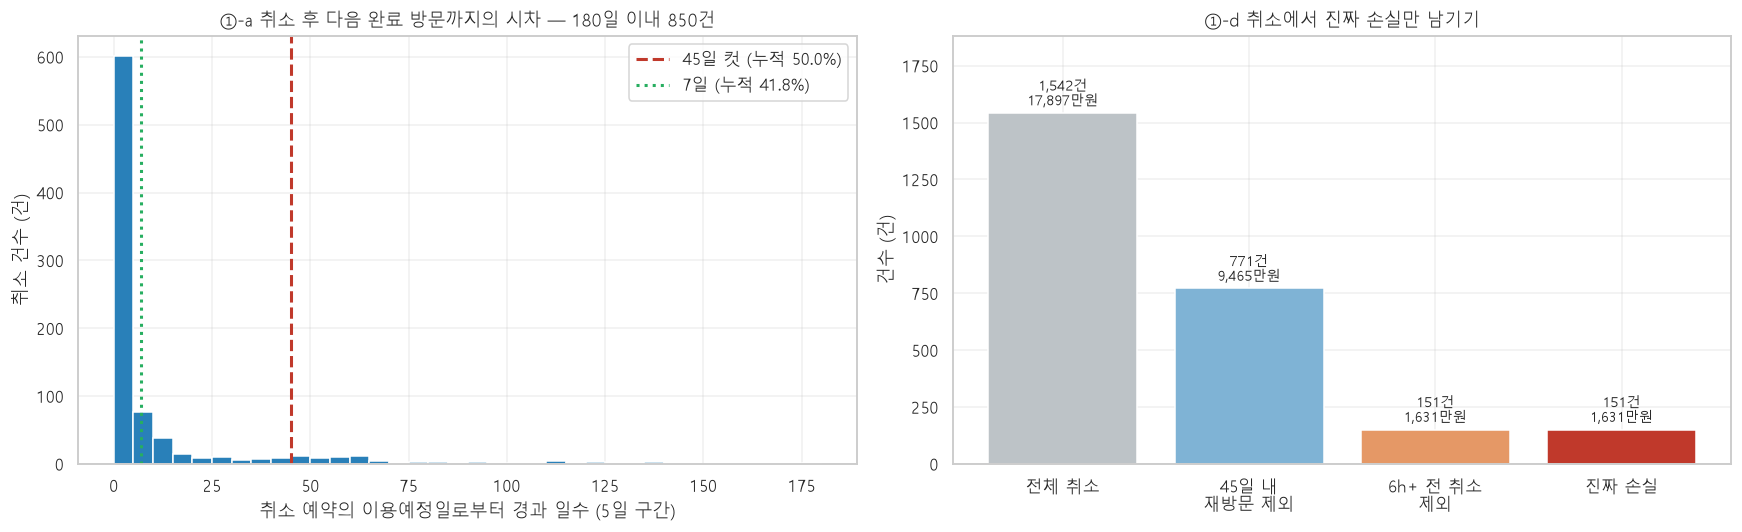

In [14]:
# ── ① 그래프: 재예약 시차 히스토그램 + 손실 깔때기 ───────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

ax = axes[0]
_d = CANC.days_to_next.dropna()
ax.hist(_d[_d <= 180], bins=np.arange(0, 185, 5), color="#2980b9", edgecolor="white")
ax.axvline(45, color="#c0392b", ls="--", lw=2, label=f"45일 컷 (누적 {CANC.revisit_fwd.mean()*100:.1f}%)")
ax.axvline(7,  color="#27ae60", ls=":",  lw=2, label=f"7일 (누적 {(_d<=7).sum()/len(CANC)*100:.1f}%)")
ax.set_title(f"①-a 취소 후 다음 완료 방문까지의 시차 — 180일 이내 {int((_d<=180).sum()):,}건")
ax.set_xlabel("취소 예약의 이용예정일로부터 경과 일수 (5일 구간)")
ax.set_ylabel("취소 건수 (건)")
ax.legend()

ax = axes[1]
_labels = ["전체 취소", "45일 내\n재방문 제외", "6h+ 전 취소\n제외", "진짜 손실"]
_vals   = [len(CANC), len(_step2), len(_step2) - len(_step3), len(_loss)]
_cols   = ["#bdc3c7", "#7fb3d5", "#e59866", "#c0392b"]
bars = ax.bar(_labels, _vals, color=_cols)
for b, v, m in zip(bars, _vals, [_step1.paid.sum(), _step2.paid.sum(),
                                 _step2.paid.sum() - _step3.paid.sum(), _loss.paid.sum()]):
    ax.annotate(f"{v:,}건\n{m/10000:,.0f}만원", (b.get_x() + b.get_width()/2, v),
                textcoords="offset points", xytext=(0, 5), ha="center", fontsize=9)
ax.set_title("①-d 취소에서 진짜 손실만 남기기")
ax.set_ylabel("건수 (건)")
ax.set_ylim(0, len(CANC)*1.22)
plt.tight_layout(); plt.show()

---
# ② 요일별 — 가장 바쁜 때와 한가한 때 (매출 포함)

## ⚠️ 정규화가 핵심이다

20개월 누적이라 요일마다 등장 횟수가 다르다. **누적 건수만 보면 틀린다.**
두 가지 분모를 모두 계산해 병기하고, **요일당 평균은 영업일 수 기준**을 쓴다.

| 분모 | 정의 | 값 |
|---|---|---|
| 달력 요일 수 | 2025-01-01 ~ 2026-08-23 사이 그 요일이 나온 날짜 수 | 85~86 |
| **영업일 수 (채택)** | 그 요일 중 **완료 건이 1건 이상 있는 날** 수 | 81~85 |

영업일 기준을 쓰는 이유: 문 닫은 날을 분모에 넣으면 그 요일의 실제 처리량이 과소평가된다.

## 그 외 정의
* 신규 고객 = 그 완료 예약이 그 `cust_key` 의 **첫 완료 방문**인 건.
* 첫 방문 요일별 재방문율은 01번 ⑤-2와 같은 값이어야 한다(같은 셀에서 대조한다).

In [15]:
# ── ②-1 요일별 기본 집계 ─────────────────────────────────────────────────────
_cal = pd.Series(pd.date_range(R.use_dt.min().normalize(), R.use_dt.max().normalize(), freq="D").dayofweek)
CAL_DOW = _cal.value_counts().sort_index().rename(lambda i: DOW_KO[i])
BIZ_DOW = (DONE.date.drop_duplicates().dt.dayofweek.value_counts().sort_index()
                .rename(lambda i: DOW_KO[i]))

# 신규 고객 표시
_first_ids = set(DONE.sort_values("use_dt").drop_duplicates("cust_key", keep="first").예약번호)
DONE["신규고객"] = DONE.예약번호.isin(_first_ids)

_dw = (R.groupby("dow_ko")
         .agg(예약=("예약번호", "size"),
              완료=("status", lambda s: int((s == "이용완료").sum())),
              취소=("status", lambda s: int((s == "취소").sum())))
         .reindex(DOW_KO))
_dw["취소율(%)"]      = _dw.취소 / _dw.예약 * 100
_dw["달력 요일수"]     = CAL_DOW.reindex(DOW_KO)
_dw["영업일수"]        = BIZ_DOW.reindex(DOW_KO)
_dw["완료매출"]        = DONE.groupby("dow_ko").paid.sum().reindex(DOW_KO)
_dw["요일1회당 매출"]  = _dw.완료매출 / _dw.영업일수
_dw["요일1회당 완료"]  = _dw.완료 / _dw.영업일수
_dw["객단가 중앙값"]   = DONE.groupby("dow_ko").paid.median().reindex(DOW_KO)
_dw["객단가 평균"]     = DONE.groupby("dow_ko").paid.mean().reindex(DOW_KO)
_dw["매출 비중(%)"]    = _dw.완료매출 / DONE.paid.sum() * 100
tbl(_dw.round(1), "②-1 요일별 예약·완료·취소·매출 (use_dt 기준)")

**②-1 요일별 예약·완료·취소·매출 (use_dt 기준)**

,예약,완료,취소,취소율(%),달력 요일수,영업일수,완료매출,요일1회당 매출,요일1회당 완료,객단가 중앙값,객단가 평균,매출 비중(%)
dow_ko,,,,,,,,,,,,
월,661,416,245,37.1,85,82,48114000,586756.1,5.1,100000.0,115658.7,15.6
화,509,320,189,37.1,85,82,37277000,454597.6,3.9,100000.0,116490.6,12.1
수,557,350,207,37.2,86,83,40628500,489500.0,4.2,100000.0,116081.4,13.1
목,609,405,204,33.5,86,83,47091000,567361.4,4.9,100000.0,116274.1,15.2
금,792,532,260,32.8,86,84,60477500,719970.2,6.3,100000.0,113679.5,19.6
토,630,383,247,39.2,86,85,41048150,482919.4,4.5,100000.0,107175.3,13.3
일,523,326,190,36.3,86,81,34339500,423944.4,4.0,100000.0,105335.9,11.1


In [16]:
# ── ②-2 요일별 신규 고객과 첫 방문 재방문율 ──────────────────────────────────
_nw = (DONE.groupby("dow_ko")
           .agg(완료=("예약번호", "size"), 신규=("신규고객", "sum"))
           .reindex(DOW_KO))
_nw["신규 비중(%)"] = _nw.신규 / _nw.완료 * 100
_fd = (CUST.groupby("첫방문요일")
           .agg(첫방문인원=("방문횟수", "size"), 재방문율=("재방문", "mean"),
                평균방문횟수=("방문횟수", "mean"), 누적지출평균=("누적지출", "mean"))
           .reindex(DOW_KO))
_fd["재방문율"] = _fd.재방문율 * 100
_nw = _nw.join(_fd)
tbl(_nw.round(2), "②-2 요일별 신규 고객 비중과 첫 방문 재방문율")

# 01번 ⑤-2 대조 (같은 값이어야 한다)
_exp = {"월": 34.71, "화": 24.73, "수": 18.54, "목": 25.52, "금": 31.08, "토": 20.74, "일": 26.16}
_chk = pd.DataFrame({"이번": _nw.재방문율.round(2), "01번 ⑤-2": pd.Series(_exp)})
_chk["일치"] = np.where(_chk.이번 == _chk["01번 ⑤-2"], "OK", "★불일치")
tbl(_chk, "②-2b 01번 ⑤-2 대조")
assert (_chk.일치 == "OK").all(), "01번 요일별 재방문율과 불일치"

**②-2 요일별 신규 고객 비중과 첫 방문 재방문율**

,완료,신규,신규 비중(%),첫방문인원,재방문율,평균방문횟수,누적지출평균
dow_ko,,,,,,,
월,416,242,58.17,242,34.71,1.96,222045.45
화,320,186,58.13,186,24.73,1.82,203210.48
수,350,205,58.57,205,18.54,1.40,169139.02
목,405,239,59.01,239,25.52,1.63,197384.94
금,532,296,55.64,296,31.08,1.87,208160.47
토,383,217,56.66,217,20.74,1.53,181092.17
일,326,172,52.76,172,26.16,2.07,201642.44


**②-2b 01번 ⑤-2 대조**

,이번,01번 ⑤-2,일치
월,34.71,34.71,OK
화,24.73,24.73,OK
수,18.54,18.54,OK
목,25.52,25.52,OK
금,31.08,31.08,OK
토,20.74,20.74,OK
일,26.16,26.16,OK


In [17]:
# ── ②-3 요일별 대표시술 구성비 ───────────────────────────────────────────────
_dm  = pd.crosstab(DONE.dow_ko, DONE.rep_cat).reindex(index=DOW_KO)
_dm  = _dm[[c for c in PRIORITY if c in _dm.columns]].fillna(0).astype(int)
_dmp = _dm.div(_dm.sum(axis=1), axis=0) * 100
_dmp["완료건수"] = _dm.sum(axis=1)
tbl(_dm, "②-3a 요일 x 대표시술 완료 건수")
tbl(_dmp.round(2), "②-3b 요일별 대표시술 구성비 (%) — 대표시술 기준")

**②-3a 요일 x 대표시술 완료 건수**

rep_cat,탈색,펌,염색,컷,클리닉,스타일링,기타,확인필요
dow_ko,,,,,,,,
월,263,16,87,41,4,1,0,4
화,199,21,65,25,4,4,0,2
수,209,22,87,21,8,2,0,1
목,260,21,80,29,7,3,0,5
금,333,27,126,34,8,2,1,1
토,182,35,105,47,5,3,0,6
일,161,29,97,27,5,3,0,4


**②-3b 요일별 대표시술 구성비 (%) — 대표시술 기준**

rep_cat,탈색,펌,염색,컷,클리닉,스타일링,기타,확인필요,완료건수
dow_ko,,,,,,,,,
월,63.22,3.85,20.91,9.86,0.96,0.24,0.00,0.96,416
화,62.19,6.56,20.31,7.81,1.25,1.25,0.00,0.62,320
수,59.71,6.29,24.86,6.00,2.29,0.57,0.00,0.29,350
목,64.20,5.19,19.75,7.16,1.73,0.74,0.00,1.23,405
금,62.59,5.08,23.68,6.39,1.50,0.38,0.19,0.19,532
토,47.52,9.14,27.42,12.27,1.31,0.78,0.00,1.57,383
일,49.39,8.90,29.75,8.28,1.53,0.92,0.00,1.23,326


In [18]:
# ── ②-4 가장 바쁜 요일 / 한가한 요일 — 건수 기준 vs 매출 기준 ────────────────
_rank = pd.DataFrame({
    "요일1회당 완료건수": _dw["요일1회당 완료"],
    "요일1회당 매출":     _dw["요일1회당 매출"],
    "객단가 중앙값":      _dw["객단가 중앙값"],
})
_rank["건수 순위"] = _rank["요일1회당 완료건수"].rank(ascending=False).astype(int)
_rank["매출 순위"] = _rank["요일1회당 매출"].rank(ascending=False).astype(int)
_rank["순위 차(건수−매출)"] = _rank["건수 순위"] - _rank["매출 순위"]
tbl(_rank.round(1), "②-4 요일 순위 — 건수 기준과 매출 기준")

_busy_n  = _rank["요일1회당 완료건수"].idxmax(); _idle_n = _rank["요일1회당 완료건수"].idxmin()
_busy_m  = _rank["요일1회당 매출"].idxmax();     _idle_m = _rank["요일1회당 매출"].idxmin()
print(f"건수 기준 — 가장 바쁨: {_busy_n}요일 ({_rank.loc[_busy_n,'요일1회당 완료건수']:.2f}건/일) · "
      f"가장 한가함: {_idle_n}요일 ({_rank.loc[_idle_n,'요일1회당 완료건수']:.2f}건/일)")
print(f"매출 기준 — 가장 바쁨: {_busy_m}요일 ({_rank.loc[_busy_m,'요일1회당 매출']:,.0f}원/일) · "
      f"가장 한가함: {_idle_m}요일 ({_rank.loc[_idle_m,'요일1회당 매출']:,.0f}원/일)")
if _busy_n != _busy_m or _idle_n != _idle_m:
    print("→ 건수 순위와 매출 순위가 갈린다. 순위 차가 양수인 요일은 '건수는 많은데 매출은 낮은' 요일이고,")
    print("  그 요일에는 상대적으로 저가 시술이 몰려 있다(위 ②-3b 구성비와 같이 볼 것).")
else:
    print("→ 건수 순위와 매출 순위가 같은 요일을 가리킨다.")
_gap = _rank["순위 차(건수−매출)"]
if (_gap != 0).any():
    print("순위 차가 큰 요일:", ", ".join(f"{i}({v:+d})" for i, v in _gap[_gap != 0].items()))

**②-4 요일 순위 — 건수 기준과 매출 기준**

,요일1회당 완료건수,요일1회당 매출,객단가 중앙값,건수 순위,매출 순위,순위 차(건수−매출)
dow_ko,,,,,,
월,5.1,586756.1,100000.0,2,2,0
화,3.9,454597.6,100000.0,7,6,1
수,4.2,489500.0,100000.0,5,4,1
목,4.9,567361.4,100000.0,3,3,0
금,6.3,719970.2,100000.0,1,1,0
토,4.5,482919.4,100000.0,4,5,-1
일,4.0,423944.4,100000.0,6,7,-1


건수 기준 — 가장 바쁨: 금요일 (6.33건/일) · 가장 한가함: 화요일 (3.90건/일)
매출 기준 — 가장 바쁨: 금요일 (719,970원/일) · 가장 한가함: 일요일 (423,944원/일)
→ 건수 순위와 매출 순위가 갈린다. 순위 차가 양수인 요일은 '건수는 많은데 매출은 낮은' 요일이고,
  그 요일에는 상대적으로 저가 시술이 몰려 있다(위 ②-3b 구성비와 같이 볼 것).
순위 차가 큰 요일: 화(+1), 수(+1), 토(-1), 일(-1)


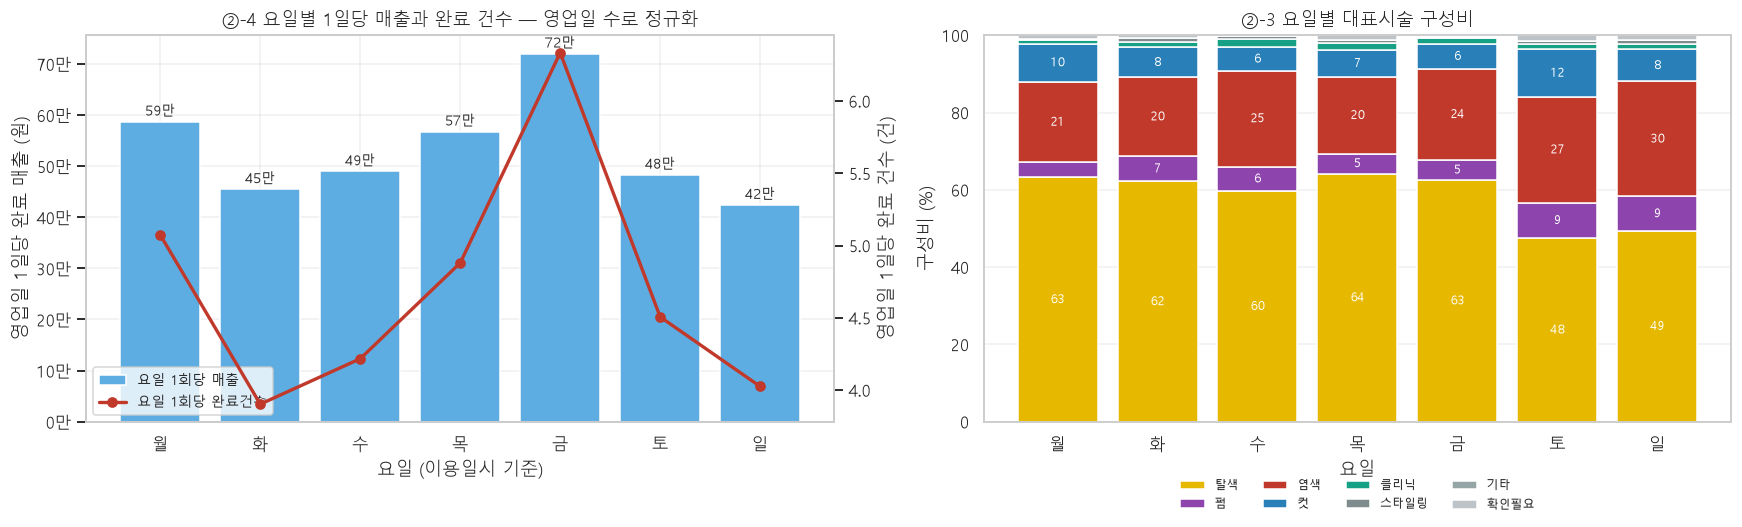

In [19]:
# ── ② 그래프: 매출·건수 이중축 + 시술 구성 100% 누적 ─────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

ax = axes[0]
ax.bar(DOW_KO, _dw["요일1회당 매출"], color="#5dade2", label="요일 1회당 매출")
for i, v in enumerate(_dw["요일1회당 매출"]):
    ax.annotate(f"{v/10000:.0f}만", (i, v), textcoords="offset points", xytext=(0, 4),
                ha="center", fontsize=9)
ax.set_ylabel("영업일 1일당 완료 매출 (원)")
ax.set_xlabel("요일 (이용일시 기준)")
ax.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, p: f"{v/10000:.0f}만"))
ax2 = ax.twinx(); ax2.grid(False)
ax2.plot(DOW_KO, _dw["요일1회당 완료"], color="#c0392b", marker="o", lw=2.2, label="요일 1회당 완료건수")
ax2.set_ylabel("영업일 1일당 완료 건수 (건)")
ax.set_title("②-4 요일별 1일당 매출과 완료 건수 — 영업일 수로 정규화")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="lower left", fontsize=9)

ax = axes[1]
_st = _dmp.drop(columns="완료건수")
_colors = {"탈색": "#e6b800", "펌": "#8e44ad", "염색": "#c0392b", "컷": "#2980b9",
           "클리닉": "#16a085", "스타일링": "#7f8c8d", "기타": "#95a5a6", "확인필요": "#bdc3c7"}
_bottom = np.zeros(len(_st))
for c in _st.columns:
    ax.bar(_st.index, _st[c], bottom=_bottom, label=c, color=_colors.get(c))
    for i, v in enumerate(_st[c]):
        if v >= 5:
            ax.text(i, _bottom[i] + v/2, f"{v:.0f}", ha="center", va="center", fontsize=8, color="white")
    _bottom += _st[c].values
ax.set_ylim(0, 100); ax.set_ylabel("구성비 (%)"); ax.set_xlabel("요일")
ax.set_title("②-3 요일별 대표시술 구성비")
ax.legend(fontsize=8, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.12), frameon=False)
plt.tight_layout(); plt.show()

---
# ③ 시간대별 — 프로모션 넣을 자리 찾기

목적은 **"비어 있으면서 채울 수 있는 슬롯"** 을 찾는 것이다.
단순히 한가한 곳이 아니라 **왜 비었는지**까지 판정해야 광고비를 쓸 자리인지 알 수 있다.

## 판정 규칙 (명시)

시(hour) 10~20시를 대상으로, 완료 건수의 **시간대 중앙값**과 전체 객단가 중앙값을 기준으로 나눈다.

| 유형 | 조건 | 뜻 |
|---|---|---|
| **포화** | 완료건수 ≥ 시간대 중앙값 **그리고** 객단가 중앙값 ≥ 전체 객단가 중앙값 | 이미 차 있다. 광고비 쓰면 낭비 |
| **저효율** | 완료건수 ≥ 시간대 중앙값 **그리고** 객단가 중앙값 < 전체 객단가 중앙값 | 사람은 오는데 단가가 낮다. 상향 판매 여지 |
| **공백(구조적)** | 완료건수 < 중앙값 **그리고** 그 시각에 탈색(3.5h)을 시작할 수 없음 | 마감 때문에 물리적으로 못 받는다 |
| **공백(수요)** | 완료건수 < 중앙값 **그리고** 탈색을 시작할 수 있음 | 받을 수 있는데 예약이 없다 → **프로모션 타겟** |

**시작 가능 판정**: 영업 마감 20:00 기준으로 `시작시각 + 소요시간 ≤ 20:00` 이면 그 시술을 시작할 수 있다.
소요시간은 01번 가정(`탈색 3.5h / 펌 2.5h / 염색 70분 / 컷 40분`)을 쓴다.
사장님이 말씀하신 기준(뿌리탈색 4.5h / 전체탈색 8h)으로 하면 제약이 훨씬 빡빡해지므로
⑤-2에서 그 기준의 판정도 따로 낸다.

**영업일당 평균**의 분모는 전체 영업일 수(완료 건이 1건 이상 있는 날)를 쓴다.

In [20]:
# ── ③-1 시간대별 기본 집계 ───────────────────────────────────────────────────
HOURS   = list(range(10, 21))
CLOSE_H = 20.0
N_BIZ   = DONE.date.nunique()

_h = (DONE[DONE.hour.isin(HOURS)].groupby("hour")
          .agg(완료건수=("예약번호", "size"), 완료매출=("paid", "sum"),
               객단가중앙값=("paid", "median"), 객단가평균=("paid", "mean"))
          .reindex(HOURS).fillna(0))
_hall = R[R.hour.isin(HOURS)].groupby("hour").agg(
    예약=("예약번호", "size"), 취소=("status", lambda s: int((s == "취소").sum()))).reindex(HOURS).fillna(0)
_h["예약건수"]        = _hall.예약
_h["취소율(%)"]       = _hall.취소 / _hall.예약 * 100
_h["영업일당 완료"]   = _h.완료건수 / N_BIZ
_h["시간당 평균매출"] = _h.완료매출 / N_BIZ
_h["매출 비중(%)"]    = _h.완료매출 / DONE.paid.sum() * 100
_h["소표본"]          = _h.완료건수.map(lambda n: small(n))
tbl(_h.round(2), f"③-1 시(hour)별 완료·매출·취소 — 전체 영업일 {N_BIZ}일 기준")

**③-1 시(hour)별 완료·매출·취소 — 전체 영업일 580일 기준**

,완료건수,완료매출,객단가중앙값,객단가평균,예약건수,취소율(%),영업일당 완료,시간당 평균매출,매출 비중(%),소표본
hour,,,,,,,,,,
10,295,39511000,150000.0,133935.59,489,39.06,0.51,68122.41,12.79,
11,421,52031000,116000.0,123589.07,675,37.63,0.73,89708.62,16.84,
12,388,48327000,108000.0,124554.12,633,38.55,0.67,83322.41,15.64,
13,337,42122500,116000.0,124992.58,559,39.36,0.58,72625.00,13.63,
14,325,37661150,100000.0,115880.46,534,39.14,0.56,64933.02,12.19,
15,295,29624000,100000.0,100420.34,423,30.02,0.51,51075.86,9.59,
16,191,20190000,100000.0,105706.81,283,32.51,0.33,34810.34,6.53,
17,198,17169000,68000.0,86712.12,289,31.49,0.34,29601.72,5.56,
18,193,15949000,58000.0,82637.31,259,25.48,0.33,27498.28,5.16,


In [21]:
# ── ③-2 시간대별 대표시술 구성비 ─────────────────────────────────────────────
_hm  = pd.crosstab(DONE[DONE.hour.isin(HOURS)].hour, DONE[DONE.hour.isin(HOURS)].rep_cat).reindex(HOURS)
_hm  = _hm[[c for c in PRIORITY if c in _hm.columns]].fillna(0).astype(int)
_hmp = _hm.div(_hm.sum(axis=1).replace(0, np.nan), axis=0) * 100
_hmp["완료건수"] = _hm.sum(axis=1)
tbl(_hmp.round(2), "③-2 시(hour)별 대표시술 구성비 (%)")

**③-2 시(hour)별 대표시술 구성비 (%)**

rep_cat,탈색,펌,염색,컷,클리닉,스타일링,기타,확인필요,완료건수
hour,,,,,,,,,
10,71.53,6.10,17.63,3.39,0.68,0.00,0.34,0.34,295
11,66.98,7.60,16.39,6.65,1.66,0.48,0.00,0.24,421
12,70.10,5.41,15.98,7.73,0.52,0.26,0.00,0.00,388
13,67.95,6.82,16.91,7.12,0.59,0.59,0.00,0.00,337
14,65.23,5.54,20.00,7.69,0.92,0.31,0.00,0.31,325
15,51.19,7.80,24.41,12.88,1.02,0.68,0.00,2.03,295
16,49.21,7.85,29.32,7.33,3.14,0.52,0.00,2.62,191
17,39.90,4.04,38.89,10.61,3.03,1.52,0.00,2.02,198
18,27.46,5.18,50.78,10.88,3.11,1.04,0.00,1.55,193


In [22]:
# ── ③-3 시간대 유형 판정 ─────────────────────────────────────────────────────
MED_N     = _h.완료건수.median()
MED_PRICE = DONE.paid.median()

def _startable(h, dur):
    return h + dur <= CLOSE_H

def _feasible(h, durmap=DUR_H):
    return [c for c in CORE5 if durmap.get(c, 0) > 0 and _startable(h, durmap[c])]

def _classify(row):
    h = row.name
    if row.완료건수 >= MED_N:
        return "포화" if row.객단가중앙값 >= MED_PRICE else "저효율"
    return "공백(수요)" if _startable(h, DUR_H["탈색"]) else "공백(구조적)"

_h["유형"] = _h.apply(_classify, axis=1)
_h["시작가능 시술"] = [", ".join(_feasible(h)) if _feasible(h) else "(없음)" for h in _h.index]
_h["잔여 영업시간"] = [CLOSE_H - h for h in _h.index]

print(f"판정 기준 — 완료건수 중앙값 {MED_N:.0f}건 · 전체 객단가 중앙값 {MED_PRICE:,.0f}원 · 마감 {CLOSE_H:.0f}:00")
tbl(_h[["완료건수", "영업일당 완료", "완료매출", "객단가중앙값", "취소율(%)",
        "잔여 영업시간", "시작가능 시술", "유형", "소표본"]].round(2),
    "③-3 시간대 유형 판정")
tbl(_h.유형.value_counts().rename("시간대 수").to_frame(), "③-3b 유형별 시간대 수")

판정 기준 — 완료건수 중앙값 295건 · 전체 객단가 중앙값 100,000원 · 마감 20:00


**③-3 시간대 유형 판정**

,완료건수,영업일당 완료,완료매출,객단가중앙값,취소율(%),잔여 영업시간,시작가능 시술,유형,소표본
hour,,,,,,,,,
10,295,0.51,39511000,150000.0,39.06,10.0,"탈색, 펌, 염색, 컷",포화,
11,421,0.73,52031000,116000.0,37.63,9.0,"탈색, 펌, 염색, 컷",포화,
12,388,0.67,48327000,108000.0,38.55,8.0,"탈색, 펌, 염색, 컷",포화,
13,337,0.58,42122500,116000.0,39.36,7.0,"탈색, 펌, 염색, 컷",포화,
14,325,0.56,37661150,100000.0,39.14,6.0,"탈색, 펌, 염색, 컷",포화,
15,295,0.51,29624000,100000.0,30.02,5.0,"탈색, 펌, 염색, 컷",포화,
16,191,0.33,20190000,100000.0,32.51,4.0,"탈색, 펌, 염색, 컷",공백(수요),
17,198,0.34,17169000,68000.0,31.49,3.0,"펌, 염색, 컷",공백(구조적),
18,193,0.33,15949000,58000.0,25.48,2.0,"염색, 컷",공백(구조적),


**③-3b 유형별 시간대 수**

,시간대 수
유형,
포화,6
공백(구조적),4
공백(수요),1


In [23]:
# ── ③-4 (요일 x 시간) 슬롯 — 구체적 프로모션 자리 ────────────────────────────
_DW = DONE[DONE.hour.isin(HOURS)].copy()
_biz_dow = DONE.date.drop_duplicates().dt.dayofweek.value_counts().rename(lambda i: DOW_KO[i])

_cell = (_DW.groupby(["dow_ko", "hour"])
            .agg(완료건수=("예약번호", "size"), 매출=("paid", "sum"), 객단가중앙값=("paid", "median")))
_cell = _cell.reindex(pd.MultiIndex.from_product([DOW_KO, HOURS], names=["dow_ko", "hour"])).fillna(0)
_rall = R[R.hour.isin(HOURS)].groupby(["dow_ko", "hour"]).agg(
    예약=("예약번호", "size"), 취소=("status", lambda s: int((s == "취소").sum())))
_cell = _cell.join(_rall).fillna(0)
_cell["취소율(%)"]     = np.where(_cell.예약 > 0, _cell.취소 / _cell.예약 * 100, np.nan)
_cell = _cell.reset_index()
_cell["요일영업일수"]  = _cell.dow_ko.map(_biz_dow)
_cell["일당 완료건수"] = _cell.완료건수 / _cell.요일영업일수
_cell["일당 매출"]     = _cell.매출 / _cell.요일영업일수

# 히트맵용 피벗
PIV_N = _cell.pivot(index="dow_ko", columns="hour", values="일당 완료건수").reindex(DOW_KO)
PIV_M = _cell.pivot(index="dow_ko", columns="hour", values="일당 매출").reindex(DOW_KO)
tbl(PIV_N.round(3), "③-4a (요일 x 시) 영업일 1일당 완료 건수")
tbl(PIV_M.round(0), "③-4b (요일 x 시) 영업일 1일당 완료 매출 (원)")

**③-4a (요일 x 시) 영업일 1일당 완료 건수**

hour,10,11,12,13,14,15,16,17,18,19,20
dow_ko,,,,,,,,,,,
월,0.427,0.744,0.756,0.671,0.610,0.512,0.317,0.463,0.354,0.220,0.000
화,0.402,0.671,0.549,0.451,0.476,0.390,0.195,0.305,0.293,0.171,0.000
수,0.386,0.639,0.482,0.482,0.518,0.566,0.337,0.349,0.289,0.157,0.012
목,0.530,0.699,0.639,0.590,0.819,0.422,0.361,0.349,0.325,0.133,0.012
금,0.679,1.000,1.012,0.833,0.536,0.655,0.369,0.464,0.548,0.238,0.000
토,0.541,0.741,0.718,0.600,0.541,0.459,0.353,0.247,0.235,0.059,0.012
일,0.593,0.580,0.519,0.432,0.420,0.556,0.370,0.210,0.284,0.062,0.000


**③-4b (요일 x 시) 영업일 1일당 완료 매출 (원)**

hour,10,11,12,13,14,15,16,17,18,19,20
dow_ko,,,,,,,,,,,
월,59585.0,98293.0,89805.0,86634.0,86293.0,50707.0,30451.0,42402.0,26561.0,16024.0,0.0
화,59549.0,90366.0,71378.0,58720.0,48134.0,41293.0,22488.0,26256.0,25159.0,11256.0,0.0
수,55639.0,74265.0,68518.0,63313.0,59554.0,63470.0,37181.0,31747.0,23910.0,10096.0,1807.0
목,69000.0,91952.0,80482.0,76211.0,104482.0,37127.0,38988.0,30205.0,32108.0,5602.0,1205.0
금,93964.0,118595.0,130661.0,101976.0,57917.0,74976.0,37440.0,38524.0,44488.0,21429.0,0.0
토,76188.0,84118.0,76671.0,67435.0,51214.0,38459.0,41682.0,22294.0,19388.0,4294.0,1176.0
일,62074.0,69790.0,64821.0,53395.0,46975.0,51401.0,35049.0,15630.0,20660.0,4148.0,0.0


In [24]:
# ── ③-5 프로모션 후보 슬롯 ───────────────────────────────────────────────────
# 조건: 그 시각에 최소 한 가지 시술을 시작할 수 있고(=물리적으로 받을 수 있고),
#       그 (요일,시) 셀의 일당 완료 건수가 전체 셀 중앙값보다 낮은 곳.
_cell["시작가능 시술"] = _cell.hour.map(lambda h: ", ".join(_feasible(h)) if _feasible(h) else "(없음)")
_cell["탈색 시작가능"] = _cell.hour.map(lambda h: _startable(h, DUR_H["탈색"]))
_MEDCELL = _cell["일당 완료건수"].median()

_cand = _cell[(_cell["시작가능 시술"] != "(없음)") & (_cell["일당 완료건수"] < _MEDCELL)].copy()
_cand["슬롯"] = _cand.dow_ko + "요일 " + _cand.hour.astype(str) + "시"

# 그 시각에 물리적으로 가능한 시술의 대표 단가 (menu_lines 실제 라인 단가 중앙값, 0원 제외)
_catprice = (LX[LX.line_price > 0].groupby("category").line_price
               .agg(["median", "min", "max", "size"]).rename(columns={"size": "라인수"}))
def _price_note(h):
    fs = _feasible(h)
    if not fs:
        return "(없음)"
    return " / ".join(f"{c} {_catprice.loc[c,'median']:,.0f}원" for c in fs if c in _catprice.index)
_cand["가능 시술·대표단가"] = _cand.hour.map(_price_note)

# 빈 슬롯이라도 그 시각에 '무엇을 팔 수 있느냐'에 따라 가치가 완전히 다르다.
# 19시대는 컷(40분)만 들어가서 최고 단가가 낮고, 16시대는 탈색까지 들어간다.
def _max_price(h):
    fs = [c for c in _feasible(h) if c in _catprice.index]
    return float(_catprice.loc[fs, "median"].max()) if fs else 0.0

_cand["최고 가능 단가"] = _cand.hour.map(_max_price)
_cand["빈자리(일당)"]   = _MEDCELL - _cand["일당 완료건수"]
_cand["잠재 일당매출 상한"] = _cand["빈자리(일당)"] * _cand["최고 가능 단가"]

_COLS = ["슬롯", "완료건수", "요일영업일수", "일당 완료건수", "매출", "일당 매출",
         "객단가중앙값", "취소율(%)", "탈색 시작가능", "최고 가능 단가",
         "잠재 일당매출 상한", "가능 시술·대표단가"]
PROMO = _cand.sort_values("일당 완료건수")[_COLS].reset_index(drop=True)
PROMO.index = range(1, len(PROMO) + 1)
print(f"전체 (요일 x 시) {len(_cell)}칸 중 후보 {len(PROMO)}칸 "
      f"(기준: 시술 시작 가능 & 일당 완료건수 < 전체 셀 중앙값 {_MEDCELL:.3f}건)")
tbl(PROMO.head(20).round(3), "③-5 프로모션 후보 슬롯 — 일당 완료건수가 낮은 순 (상위 20)")

# 고단가 슬롯: 그 시각에 탈색(3.5h)까지 시작할 수 있는 빈칸. 실행 가치가 가장 큰 쪽.
PROMO_HI = (PROMO[PROMO["탈색 시작가능"]]
            .sort_values("잠재 일당매출 상한", ascending=False).reset_index(drop=True))
PROMO_HI.index = range(1, len(PROMO_HI) + 1)
tbl(PROMO_HI.round(3),
    "③-5a ★고단가 빈 슬롯 — 탈색까지 받을 수 있는데 비어 있는 (요일,시). 잠재 매출 큰 순")

PROMO_LO = (PROMO[~PROMO["탈색 시작가능"]]
            .sort_values("일당 완료건수").reset_index(drop=True))
PROMO_LO.index = range(1, len(PROMO_LO) + 1)
tbl(PROMO_LO.head(10).round(3),
    "③-5b 저단가 빈 슬롯 — 마감이 가까워 짧은 시술만 가능한 (요일,시) (상위 10)")
print("주의: ③-5b 는 '구조적으로' 긴 시술을 못 받는 시각이다. 컷·염색 단품 프로모션 외에는 채우기 어렵다.")

tbl(_catprice.round(0), "③-5b 참고: 대표시술별 실제 라인 단가 (0원 라인 제외)")

# 시간대 단위 요약(요일 무관)
_promo_h = _h[_h.유형 == "공백(수요)"][["완료건수", "영업일당 완료", "완료매출", "객단가중앙값",
                                        "취소율(%)", "시작가능 시술"]]
tbl(_promo_h.round(2), "③-5c 시간대 단위 프로모션 타겟 — 유형이 '공백(수요)' 인 시각")

전체 (요일 x 시) 77칸 중 후보 31칸 (기준: 시술 시작 가능 & 일당 완료건수 < 전체 셀 중앙값 0.432건)


**③-5 프로모션 후보 슬롯 — 일당 완료건수가 낮은 순 (상위 20)**

,슬롯,완료건수,요일영업일수,일당 완료건수,매출,일당 매출,객단가중앙값,취소율(%),탈색 시작가능,최고 가능 단가,잠재 일당매출 상한,가능 시술·대표단가
1,토요일 19시,5.0,85,0.059,365000.0,4294.118,39000.0,37.500,False,29000.0,10824.982,"컷 29,000원"
2,일요일 19시,5.0,81,0.062,336000.0,4148.148,39000.0,44.444,False,29000.0,10740.741,"컷 29,000원"
3,목요일 19시,11.0,83,0.133,465000.0,5602.410,39000.0,15.385,False,29000.0,8687.491,"컷 29,000원"
4,수요일 19시,13.0,83,0.157,838000.0,10096.386,39000.0,40.909,False,29000.0,7988.696,"컷 29,000원"
5,화요일 19시,14.0,82,0.171,923000.0,11256.098,39500.0,36.364,False,29000.0,7579.645,"컷 29,000원"
6,화요일 16시,16.0,82,0.195,1844000.0,22487.805,125000.0,38.462,True,150000.0,35546.522,"탈색 150,000원 / 펌 120,000원 / 염색 39,000원 / 컷 29,000원"
7,일요일 17시,17.0,81,0.210,1266000.0,15629.630,39000.0,46.875,False,120000.0,26666.667,"펌 120,000원 / 염색 39,000원 / 컷 29,000원"
8,월요일 19시,18.0,82,0.220,1314000.0,16024.390,39000.0,43.750,False,29000.0,6165.011,"컷 29,000원"
9,토요일 18시,20.0,85,0.235,1648000.0,19388.235,63000.0,13.043,False,39000.0,7675.381,"염색 39,000원 / 컷 29,000원"
10,금요일 19시,20.0,84,0.238,1800000.0,21428.571,39000.0,28.571,False,29000.0,5626.102,"컷 29,000원"


**③-5a ★고단가 빈 슬롯 — 탈색까지 받을 수 있는데 비어 있는 (요일,시). 잠재 매출 큰 순**

,슬롯,완료건수,요일영업일수,일당 완료건수,매출,일당 매출,객단가중앙값,취소율(%),탈색 시작가능,최고 가능 단가,잠재 일당매출 상한,가능 시술·대표단가
1,화요일 16시,16.0,82,0.195,1844000.0,22487.805,125000.0,38.462,True,150000.0,35546.522,"탈색 150,000원 / 펌 120,000원 / 염색 39,000원 / 컷 29,000원"
2,월요일 16시,26.0,82,0.317,2497000.0,30451.220,88000.0,31.579,True,150000.0,17253.839,"탈색 150,000원 / 펌 120,000원 / 염색 39,000원 / 컷 29,000원"
3,수요일 16시,28.0,83,0.337,3086000.0,37180.723,100000.0,39.130,True,150000.0,14212.405,"탈색 150,000원 / 펌 120,000원 / 염색 39,000원 / 컷 29,000원"
4,토요일 16시,30.0,85,0.353,3543000.0,41682.353,100000.0,31.818,True,150000.0,11873.638,"탈색 150,000원 / 펌 120,000원 / 염색 39,000원 / 컷 29,000원"
5,목요일 16시,30.0,83,0.361,3236000.0,38987.952,100000.0,30.233,True,150000.0,10597.947,"탈색 150,000원 / 펌 120,000원 / 염색 39,000원 / 컷 29,000원"
6,금요일 16시,31.0,84,0.369,3145000.0,37440.476,100000.0,24.390,True,150000.0,9457.672,"탈색 150,000원 / 펌 120,000원 / 염색 39,000원 / 컷 29,000원"
7,일요일 16시,30.0,81,0.370,2839000.0,35049.383,87000.0,33.333,True,150000.0,9259.259,"탈색 150,000원 / 펌 120,000원 / 염색 39,000원 / 컷 29,000원"
8,수요일 10시,32.0,83,0.386,4618000.0,55638.554,150000.0,40.741,True,150000.0,6983.490,"탈색 150,000원 / 펌 120,000원 / 염색 39,000원 / 컷 29,000원"
9,화요일 15시,32.0,82,0.390,3386000.0,41292.683,100000.0,27.273,True,150000.0,6278.229,"탈색 150,000원 / 펌 120,000원 / 염색 39,000원 / 컷 29,000원"
10,화요일 10시,33.0,82,0.402,4883000.0,59548.780,150000.0,36.538,True,150000.0,4448.961,"탈색 150,000원 / 펌 120,000원 / 염색 39,000원 / 컷 29,000원"


...

주의: ③-5b 는 '구조적으로' 긴 시술을 못 받는 시각이다. 컷·염색 단품 프로모션 외에는 채우기 어렵다.


**③-5b 참고: 대표시술별 실제 라인 단가 (0원 라인 제외)**

,median,min,max,라인수
category,,,,
기타,150000.0,150000,150000,1
스타일링,29000.0,29000,50000,37
염색,39000.0,39000,155000,938
컷,29000.0,5000,50000,423
클리닉,58000.0,58000,250000,30
탈색,150000.0,58000,250000,2744
펌,120000.0,29000,260000,256
확인필요,39000.0,39000,87000,88


**③-5c 시간대 단위 프로모션 타겟 — 유형이 '공백(수요)' 인 시각**

,완료건수,영업일당 완료,완료매출,객단가중앙값,취소율(%),시작가능 시술
hour,,,,,,
16,191,0.33,20190000,100000.0,32.51,"탈색, 펌, 염색, 컷"


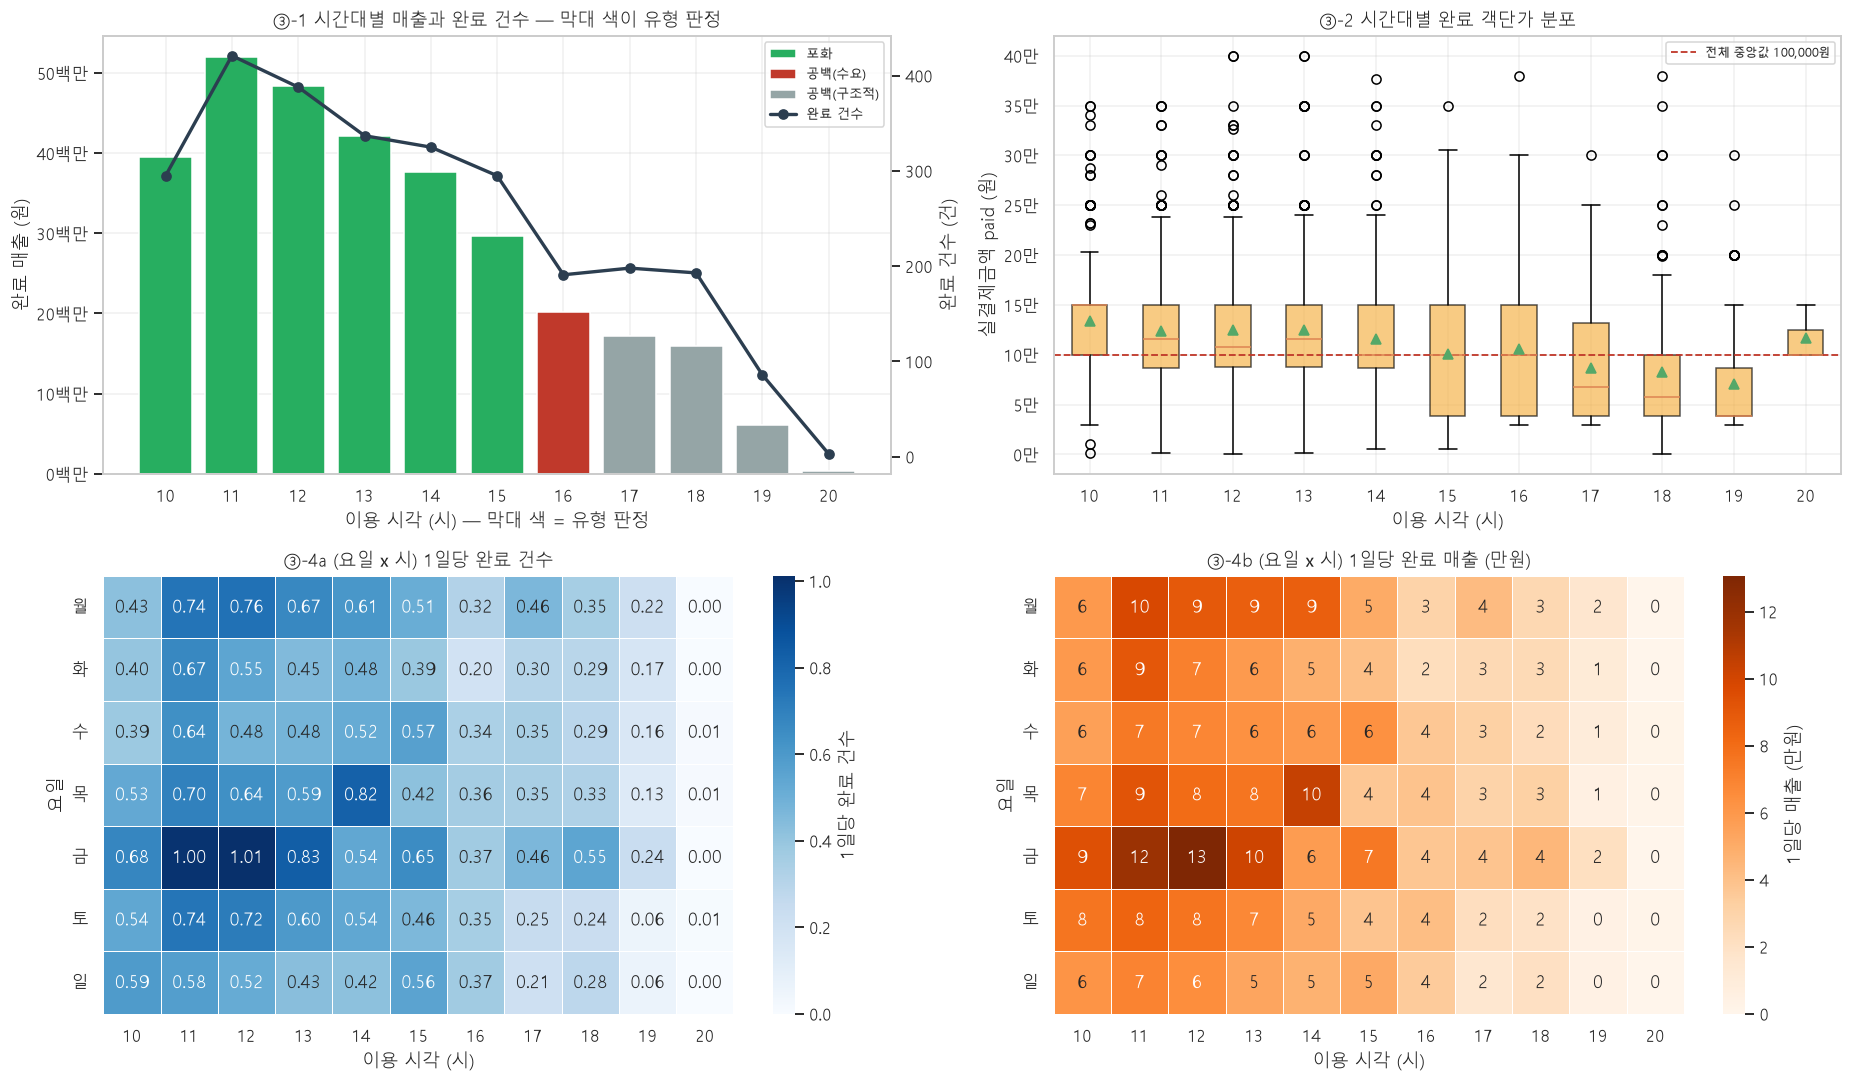

In [25]:
# ── ③ 그래프: 이중축 + 건수/매출 히트맵 나란히 + 객단가 박스플롯 ─────────────
fig = plt.figure(figsize=(17, 10))

ax = plt.subplot2grid((2, 2), (0, 0))
_tc = {"포화": "#27ae60", "저효율": "#f39c12", "공백(수요)": "#c0392b", "공백(구조적)": "#95a5a6"}
ax.bar(_h.index, _h.완료매출, color=[_tc.get(t, "#5dade2") for t in _h.유형])
ax.set_ylabel("완료 매출 (원)"); ax.set_xlabel("이용 시각 (시) — 막대 색 = 유형 판정")
ax.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, p: f"{v/1e6:.0f}백만"))
ax.set_xticks(HOURS)
ax2 = ax.twinx(); ax2.grid(False)
ax2.plot(_h.index, _h.완료건수, color="#2c3e50", marker="o", lw=2.2, label="완료 건수")
ax2.set_ylabel("완료 건수 (건)")
_handles = [matplotlib.patches.Patch(facecolor=c, label=t) for t, c in _tc.items()
            if t in set(_h.유형)]
_handles += ax2.get_legend_handles_labels()[0]
ax.legend(handles=_handles, loc="upper right", fontsize=8.5)
ax.set_title("③-1 시간대별 매출과 완료 건수 — 막대 색이 유형 판정")

ax = plt.subplot2grid((2, 2), (0, 1))
_bd = [DONE.loc[DONE.hour == hh, "paid"].values for hh in HOURS]
bp = ax.boxplot(_bd, tick_labels=[str(x) for x in HOURS], showmeans=True, patch_artist=True)
for patch in bp["boxes"]:
    patch.set_facecolor("#f5b041"); patch.set_alpha(.65)
ax.axhline(MED_PRICE, color="#c0392b", ls="--", lw=1.2, label=f"전체 중앙값 {MED_PRICE:,.0f}원")
ax.set_title("③-2 시간대별 완료 객단가 분포")
ax.set_xlabel("이용 시각 (시)"); ax.set_ylabel("실결제금액 paid (원)")
ax.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, p: f"{v/10000:.0f}만"))
ax.legend(fontsize=8)

ax = plt.subplot2grid((2, 2), (1, 0))
sns.heatmap(PIV_N, annot=True, fmt=".2f", cmap="Blues", ax=ax, linewidths=.5, linecolor="white",
            cbar_kws={"label": "1일당 완료 건수"})
ax.set_title("③-4a (요일 x 시) 1일당 완료 건수")
ax.set_xlabel("이용 시각 (시)"); ax.set_ylabel("요일")
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)

ax = plt.subplot2grid((2, 2), (1, 1))
sns.heatmap(PIV_M / 10000, annot=True, fmt=".0f", cmap="Oranges", ax=ax, linewidths=.5, linecolor="white",
            cbar_kws={"label": "1일당 매출 (만원)"})
ax.set_title("③-4b (요일 x 시) 1일당 완료 매출 (만원)")
ax.set_xlabel("이용 시각 (시)"); ax.set_ylabel("요일")
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)

plt.tight_layout(); plt.show()

---
# ④ 시술별 매출 · 비중 · 재방문

## 두 기준을 모두 낸다

01번에서 라인 기준과 대표시술 기준이 갈린 전례가 있어 **둘 다** 산출한다.

| 기준 | 매출 정의 | 특징 |
|---|---|---|
| **대표시술(예약) 기준** | 예약의 `paid` 전액을 대표시술 1개에 귀속 | 합계가 완료 총매출과 정확히 일치 |
| **메뉴 라인 기준** | `menu_lines.line_price` 를 카테고리별로 합산 | 한 예약의 여러 시술로 매출이 쪼개짐. 합계는 `listed` 기준이라 `paid` 합과 다르다 |

두 기준의 총액이 다른 이유: `paid`(실결제) 합이 `listed`(라인 단가 합) 합보다 크다.
현장에서 추가된 시술이 라인에 안 잡힌 것으로 보이며, 이 차이 자체는 01번에서 확인된 사실이다.

In [26]:
# ── ④-a1 대표시술 기준 매출 ──────────────────────────────────────────────────
_rev_rep = (DONE.groupby("rep_cat")
                .agg(완료건수=("예약번호", "size"), 매출=("paid", "sum"),
                     객단가중앙값=("paid", "median"), 객단가평균=("paid", "mean")))
_rev_rep = _rev_rep.reindex([c for c in PRIORITY if c in _rev_rep.index])
_rev_rep["매출 비중(%)"]   = _rev_rep.매출 / _rev_rep.매출.sum() * 100
_rev_rep["건수 비중(%)"]   = _rev_rep.완료건수 / _rev_rep.완료건수.sum() * 100
_rev_rep = _rev_rep.sort_values("매출", ascending=False)
_rev_rep["매출 누적(%)"]   = _rev_rep["매출 비중(%)"].cumsum()
_rev_rep["소표본"]         = _rev_rep.완료건수.map(lambda n: small(n))
tbl(_rev_rep.round(2), "④-a1 대표시술 기준 매출 (완료 건 · paid)")
print(f"합계 검산: {_rev_rep.매출.sum():,}원 == 완료 총매출 {DONE.paid.sum():,}원")
assert int(_rev_rep.매출.sum()) == int(DONE.paid.sum())

**④-a1 대표시술 기준 매출 (완료 건 · paid)**

,완료건수,매출,객단가중앙값,객단가평균,매출 비중(%),건수 비중(%),매출 누적(%),소표본
rep_cat,,,,,,,,
탈색,1607,234840500,150000.0,146135.97,76.01,58.82,76.01,
염색,647,39932150,39000.0,61718.93,12.92,23.68,88.93,
펌,171,23254500,145000.0,135991.23,7.53,6.26,96.46,
컷,224,6691500,29000.0,29872.77,2.17,8.20,98.62,
클리닉,41,2580000,39000.0,62926.83,0.84,1.50,99.46,
확인필요,23,936000,39000.0,40695.65,0.30,0.84,99.76,⚠소표본
스타일링,18,591000,32000.0,32833.33,0.19,0.66,99.95,⚠소표본
기타,1,150000,150000.0,150000.00,0.05,0.04,100.00,⚠소표본


합계 검산: 308,975,650원 == 완료 총매출 308,975,650원


In [27]:
# ── ④-a2 메뉴 라인 기준 매출 ─────────────────────────────────────────────────
_LD = LX[LX.status == "이용완료"]
_rev_line = (_LD.groupby("category")
                .agg(라인수=("menu", "size"), 매출=("line_price", "sum"),
                     라인단가중앙값=("line_price", "median"),
                     유료라인수=("line_price", lambda s: int((s > 0).sum()))))
_rev_line = _rev_line.reindex([c for c in PRIORITY if c in _rev_line.index])
_rev_line["매출 비중(%)"] = _rev_line.매출 / _rev_line.매출.sum() * 100
_rev_line = _rev_line.sort_values("매출", ascending=False)
_rev_line["매출 누적(%)"] = _rev_line["매출 비중(%)"].cumsum()
tbl(_rev_line.round(2), "④-a2 메뉴 라인 기준 매출 (완료 건 · line_price)")
print(f"라인 기준 합계 {_rev_line.매출.sum():,}원  vs  paid 합계 {DONE.paid.sum():,}원 "
      f"(차이 {DONE.paid.sum()-_rev_line.매출.sum():,}원)")

_cmp_basis = pd.DataFrame({"대표시술 기준 비중(%)": _rev_rep["매출 비중(%)"],
                           "라인 기준 비중(%)": _rev_line["매출 비중(%)"]})
_cmp_basis["차이(%p)"] = _cmp_basis["대표시술 기준 비중(%)"] - _cmp_basis["라인 기준 비중(%)"]
tbl(_cmp_basis.round(2), "④-a3 두 기준의 매출 비중 차이")

**④-a2 메뉴 라인 기준 매출 (완료 건 · line_price)**

,라인수,매출,라인단가중앙값,유료라인수,매출 비중(%),매출 누적(%)
category,,,,,,
탈색,1624,211758000,150000.0,1623,74.24,74.24
염색,668,36872000,39000.0,668,12.93,87.17
펌,178,22191000,145000.0,178,7.78,94.95
컷,336,9215000,29000.0,319,3.23,98.18
확인필요,52,2076000,39000.0,52,0.73,98.91
클리닉,1642,1998000,0.0,21,0.70,99.61
스타일링,30,957000,29000.0,30,0.34,99.95
기타,1,150000,150000.0,1,0.05,100.00


라인 기준 합계 285,217,000원  vs  paid 합계 308,975,650원 (차이 23,758,650원)


**④-a3 두 기준의 매출 비중 차이**

,대표시술 기준 비중(%),라인 기준 비중(%),차이(%p)
기타,0.05,0.05,-0.00
스타일링,0.19,0.34,-0.14
염색,12.92,12.93,-0.00
컷,2.17,3.23,-1.07
클리닉,0.84,0.70,0.13
탈색,76.01,74.24,1.76
펌,7.53,7.78,-0.25
확인필요,0.30,0.73,-0.42


In [28]:
# ── ④-a4 개별 메뉴(94종) 매출 상위 15 ────────────────────────────────────────
_menu_rev = (_LD.groupby("menu")
                .agg(라인수=("menu", "size"), 매출=("line_price", "sum"),
                     단가중앙값=("line_price", "median"))
                .join(CATMAP.set_index("menu")[["category", "is_free"]]))
_menu_rev["매출 비중(%)"] = _menu_rev.매출 / _menu_rev.매출.sum() * 100
_menu_rev = _menu_rev.sort_values("매출", ascending=False)
_menu_rev["매출 누적(%)"] = _menu_rev["매출 비중(%)"].cumsum()
_menu_rev["소표본"] = _menu_rev.라인수.map(lambda n: small(n))
tbl(_menu_rev.head(15).round(2).rename(index=mdisp), "④-a4 개별 메뉴 매출 상위 15 (완료 건 · 라인 기준)")
print(f"상위 5개 메뉴가 라인 매출의 {_menu_rev['매출 비중(%)'].head(5).sum():.2f}%, "
      f"상위 10개가 {_menu_rev['매출 비중(%)'].head(10).sum():.2f}%, "
      f"상위 15개가 {_menu_rev['매출 비중(%)'].head(15).sum():.2f}%")
_n80 = int((_menu_rev["매출 누적(%)"] < 80).sum()) + 1
print(f"매출 80%를 채우는 데 필요한 메뉴 수: {_n80}종 / 전체 {len(_menu_rev)}종")

**④-a4 개별 메뉴 매출 상위 15 (완료 건 · 라인 기준)**

,라인수,매출,단가중앙값,category,is_free,매출 비중(%),매출 누적(%),소표본
menu,,,,,,,,
뿌리탈색이벤트,716,71600000,100000.0,탈색,0,25.10,25.10,
무한탈색이벤트,330,49500000,150000.0,탈색,0,17.36,42.46,
블랙빼기,107,21400000,200000.0,탈색,0,7.50,49.96,
수험생탈색이벤트,139,20850000,150000.0,탈색,0,7.31,57.27,
"알파,베타뿌리염색",221,8619000,39000.0,염색,0,3.02,60.29,
베타뿌리염색,209,8151000,39000.0,염색,0,2.86,63.15,
수험생탈색,51,7650000,150000.0,탈색,0,2.68,65.83,
탈색이벤트,45,6750000,150000.0,탈색,0,2.37,68.20,
무한탈색+원하는컬러,41,6400000,150000.0,탈색,0,2.24,70.44,


상위 5개 메뉴가 라인 매출의 60.29%, 상위 10개가 71.95%, 상위 15개가 78.51%
매출 80%를 채우는 데 필요한 메뉴 수: 17종 / 전체 90종


## ④-b 시술별 재방문율

고객의 **첫 완료 방문 대표시술** 기준이다(01번 ⑤-1b와 같은 정의).
2회는 우연일 수 있으므로 **3회 이상** 비율도 따로 낸다.

In [29]:
# ── ④-b 시술별 재방문 ────────────────────────────────────────────────────────
_fs = (CUST.dropna(subset=["첫방문시술"]).groupby("첫방문시술")
           .agg(인원=("방문횟수", "size"), 재방문율=("재방문", "mean"),
                _3회이상=("3회이상", "mean"), 평균방문횟수=("방문횟수", "mean"),
                누적지출평균=("누적지출", "mean"), 첫방문paid중앙값=("첫방문paid", "median")))
_fs["재방문율(2회+,%)"] = _fs.재방문율 * 100
_fs["3회이상(%)"]       = _fs._3회이상 * 100
_fs = _fs.drop(columns=["재방문율", "_3회이상"])
_fs = _fs.reindex([c for c in PRIORITY if c in _fs.index])
_fs["소표본"] = _fs.인원.map(lambda n: small(n))
tbl(_fs.round(2), "④-b 첫 방문 시술별 재방문 (완료 기준 고객)")

# 01번 ⑤-1b 대조
_exp_b = {"탈색": 22.77, "펌": 39.73, "염색": 46.31, "컷": 31.63, "클리닉": 20.00}
_chk_b = pd.DataFrame({"이번": _fs["재방문율(2회+,%)"].round(2),
                       "01번 ⑤-1b": pd.Series(_exp_b)}).dropna()
_chk_b["일치"] = np.where(_chk_b.이번 == _chk_b["01번 ⑤-1b"], "OK", "★불일치")
tbl(_chk_b, "④-b2 01번 ⑤-1b 대조")
assert (_chk_b.일치 == "OK").all(), "01번 첫시술별 재방문율과 불일치"

**④-b 첫 방문 시술별 재방문 (완료 기준 고객)**

,인원,평균방문횟수,누적지출평균,첫방문paid중앙값,"재방문율(2회+,%)",3회이상(%),소표본
첫방문시술,,,,,,,
탈색,1190,1.39,200951.68,150000.0,22.77,7.65,
펌,73,1.93,236376.71,145000.0,39.73,13.70,
염색,149,4.05,251705.70,68000.0,46.31,33.56,
컷,98,2.37,93790.82,29000.0,31.63,16.33,
클리닉,20,2.00,123950.00,39000.0,20.00,15.00,⚠소표본
스타일링,17,1.12,36470.59,29000.0,11.76,0.00,⚠소표본
기타,1,1.00,150000.00,150000.0,0.00,0.00,⚠소표본
확인필요,9,4.78,293666.67,39000.0,55.56,33.33,⚠소표본


**④-b2 01번 ⑤-1b 대조**

,이번,01번 ⑤-1b,일치
염색,46.31,46.31,OK
컷,31.63,31.63,OK
클리닉,20.00,20.00,OK
탈색,22.77,22.77,OK
펌,39.73,39.73,OK


## ④-c 재방문 주기 — 시술마다 다른가

같은 고객의 **인접 완료 방문 간격**을 **직전 방문의 대표시술**로 나눠 본다.
탈색·염색은 뿌리가 자라는 생리적 주기가 있어 간격이 좁게 몰릴 것으로 예상되고,
컷은 더 넓게 퍼질 것으로 예상된다. 실제로 그런지 확인한다.

**안내 최적 시점 = 간격 중앙값 − 3일** (고객이 스스로 예약하기 직전에 닿도록 3일 앞당김).

In [30]:
# ── ④-c 시술별 재방문 간격 ───────────────────────────────────────────────────
_cyc = (PAIRS.groupby("prev_cat").gap_days
             .agg(쌍수="size", 중앙값="median", 평균="mean",
                  Q1=lambda s: s.quantile(.25), Q3=lambda s: s.quantile(.75),
                  P10=lambda s: s.quantile(.10), P90=lambda s: s.quantile(.90), 표준편차="std"))
_cyc = _cyc.reindex([c for c in PRIORITY if c in _cyc.index]).dropna(how="all")
_cyc["IQR(퍼짐)"]      = _cyc.Q3 - _cyc.Q1
_cyc["안내 최적일(중앙값−3)"] = _cyc.중앙값 - 3
_cyc["소표본"] = _cyc.쌍수.map(lambda n: small(n))
tbl(_cyc.round(2), "④-c 직전 시술별 다음 방문까지의 간격 (일)")
print(f"전체 중앙값 {PAIRS.gap_days.median():.2f}일 (01번 ⑩-2 값과 동일해야 함)")
print("IQR(퍼짐)이 작을수록 방문 주기가 규칙적이다 = 리텐션 메시지 시점을 잡기 쉽다.")

**④-c 직전 시술별 다음 방문까지의 간격 (일)**

,쌍수,중앙값,평균,Q1,Q3,P10,P90,표준편차,IQR(퍼짐),안내 최적일(중앙값−3),소표본
prev_cat,,,,,,,,,,,
탈색,451,49.96,56.47,6.83,71.95,0.81,117.08,66.32,65.11,46.96,
펌,89,46.23,85.09,26.06,96.00,9.42,222.23,103.10,69.94,43.23,
염색,470,35.00,50.99,20.30,59.44,7.28,107.23,55.00,39.15,32.00,
컷,126,35.04,58.91,26.84,62.76,8.14,112.55,67.10,35.91,32.04,
클리닉,18,17.66,31.84,9.02,35.18,6.87,53.86,42.65,26.16,14.66,⚠소표본
스타일링,2,204.60,204.60,103.80,305.41,43.32,365.89,285.11,201.60,201.60,⚠소표본
확인필요,19,21.00,62.82,9.93,45.94,5.54,195.26,105.33,36.01,18.00,⚠소표본


전체 중앙값 41.02일 (01번 ⑩-2 값과 동일해야 함)
IQR(퍼짐)이 작을수록 방문 주기가 규칙적이다 = 리텐션 메시지 시점을 잡기 쉽다.


In [31]:
# ── ④-d 매출 기여 vs 재방문 (버블 산점도) ────────────────────────────────────
# ⚠️ 두 축의 단위가 다르다. x는 예약 단위(대표시술별 매출 비중), y는 고객 단위(첫 시술별 재방문율).
_bub = pd.DataFrame({
    "매출 비중(%)":  _rev_rep["매출 비중(%)"],
    "완료 건수":     _rev_rep["완료건수"],
    "객단가 중앙값": _rev_rep["객단가중앙값"],
}).join(_fs[["재방문율(2회+,%)", "3회이상(%)", "인원"]])
_bub = _bub.dropna(subset=["재방문율(2회+,%)"])
_bub["소표본"] = _bub.인원.map(lambda n: small(n))
_x0, _y0 = _bub["매출 비중(%)"].median(), _bub["재방문율(2회+,%)"].median()
_bub["사분면"] = np.where(_bub["매출 비중(%)"] >= _x0,
                   np.where(_bub["재방문율(2회+,%)"] >= _y0, "매출↑·재방문↑", "★매출↑·재방문↓"),
                   np.where(_bub["재방문율(2회+,%)"] >= _y0, "매출↓·재방문↑", "매출↓·재방문↓"))
tbl(_bub.round(2), f"④-d 매출 비중 x 재방문율 (분면 경계 = 각 축 중앙값 {_x0:.2f}% / {_y0:.2f}%)")
_star = _bub[_bub.사분면 == "★매출↑·재방문↓"]
if len(_star):
    print("★ '매출은 큰데 재방문이 낮은' 시술:", ", ".join(_star.index))
    print("  이 시술과 낮은 재방문율은 같이 움직인다. 인과는 이 데이터로 말할 수 없다.")
    print("  다만 매출 기여가 크므로 재방문 개입의 우선 대상이 된다.")

**④-d 매출 비중 x 재방문율 (분면 경계 = 각 축 중앙값 1.50% / 27.20%)**

,매출 비중(%),완료 건수,객단가 중앙값,"재방문율(2회+,%)",3회이상(%),인원,소표본,사분면
rep_cat,,,,,,,,
탈색,76.01,1607,150000.0,22.77,7.65,1190,,★매출↑·재방문↓
염색,12.92,647,39000.0,46.31,33.56,149,,매출↑·재방문↑
펌,7.53,171,145000.0,39.73,13.70,73,,매출↑·재방문↑
컷,2.17,224,29000.0,31.63,16.33,98,,매출↑·재방문↑
클리닉,0.84,41,39000.0,20.00,15.00,20,⚠소표본,매출↓·재방문↓
확인필요,0.30,23,39000.0,55.56,33.33,9,⚠소표본,매출↓·재방문↑
스타일링,0.19,18,32000.0,11.76,0.00,17,⚠소표본,매출↓·재방문↓
기타,0.05,1,150000.0,0.00,0.00,1,⚠소표본,매출↓·재방문↓


★ '매출은 큰데 재방문이 낮은' 시술: 탈색
  이 시술과 낮은 재방문율은 같이 움직인다. 인과는 이 데이터로 말할 수 없다.
  다만 매출 기여가 크므로 재방문 개입의 우선 대상이 된다.


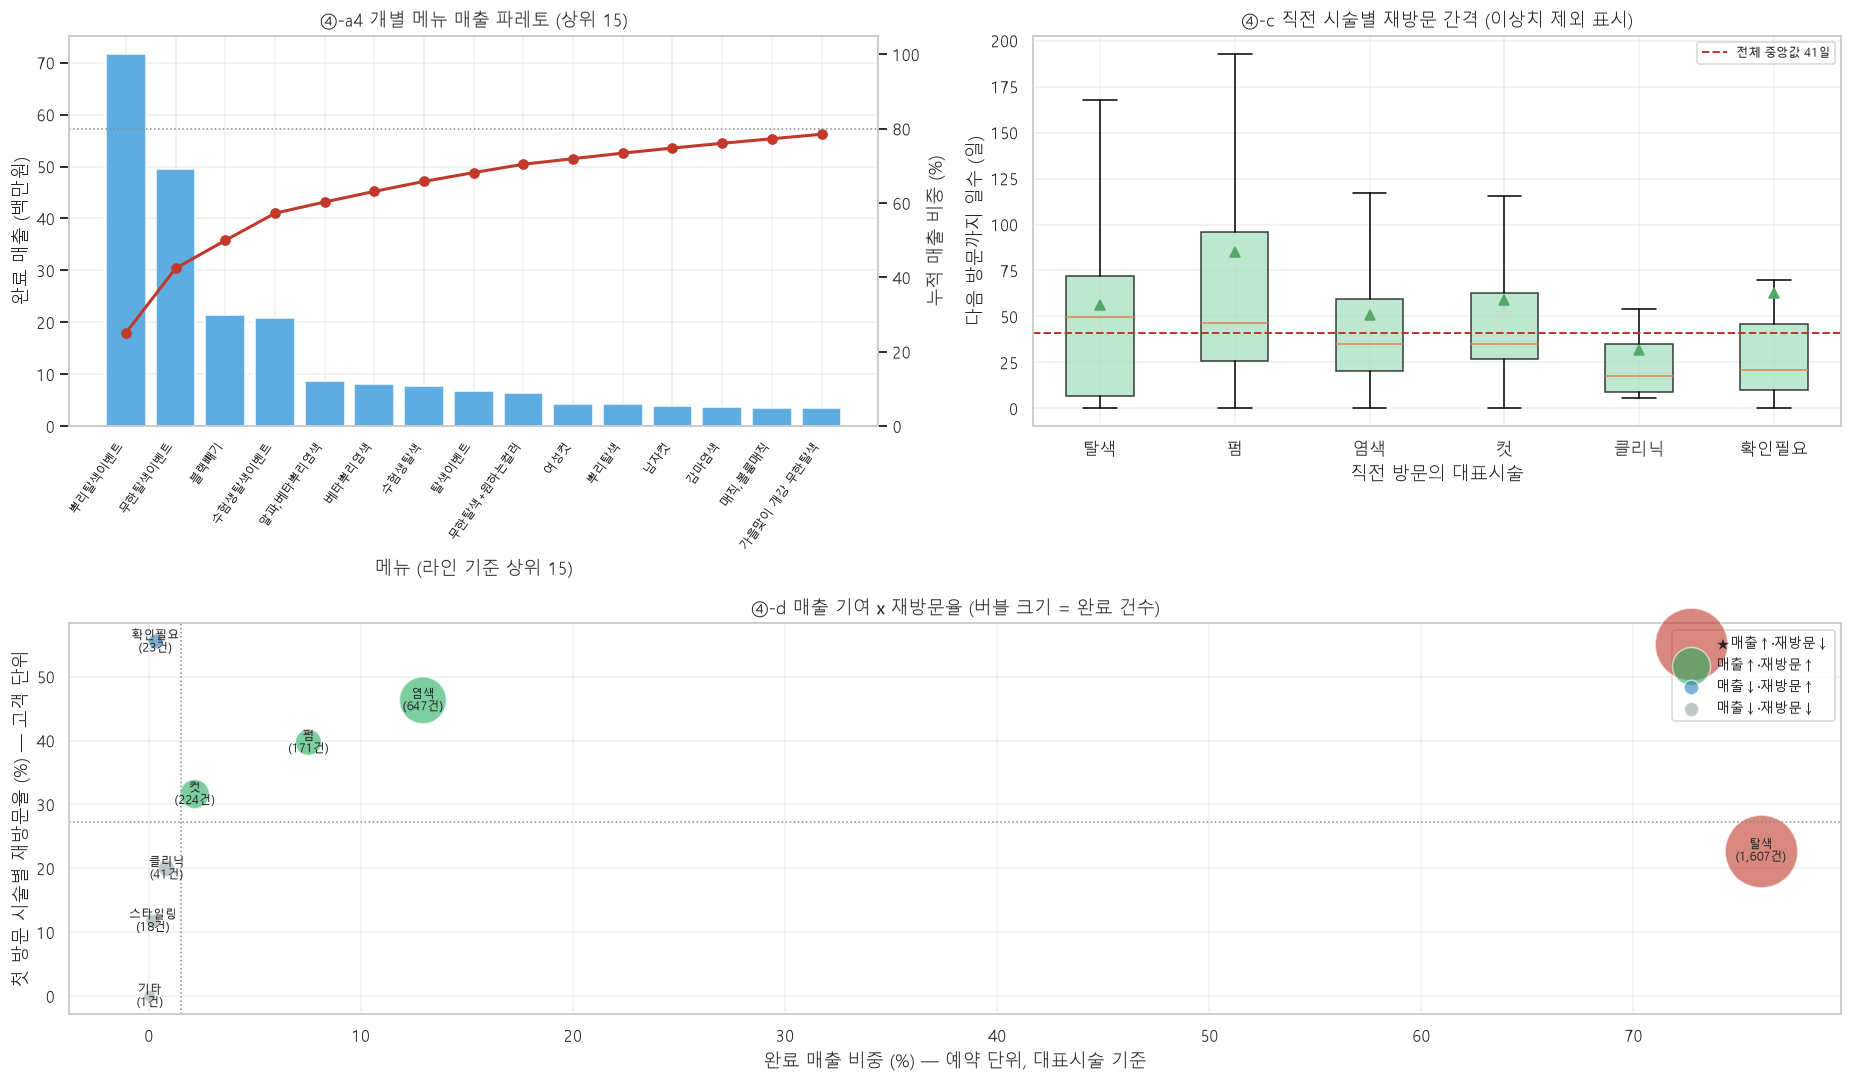

In [32]:
# ── ④ 그래프: 파레토 + 간격 박스플롯 + 버블 산점도 ───────────────────────────
fig = plt.figure(figsize=(17, 10))

ax = plt.subplot2grid((2, 2), (0, 0))
_top = _menu_rev.head(15)
ax.bar(range(len(_top)), _top.매출 / 1e6, color="#5dade2")
ax.set_xticks(range(len(_top)))
ax.set_xticklabels([mdisp(m)[:12] for m in _top.index], rotation=55, ha="right", fontsize=8)
ax.set_ylabel("완료 매출 (백만원)"); ax.set_xlabel("메뉴 (라인 기준 상위 15)")
ax2 = ax.twinx(); ax2.grid(False)
ax2.plot(range(len(_top)), _top["매출 누적(%)"], color="#c0392b", marker="o", lw=2)
ax2.axhline(80, color="#7f8c8d", ls=":", lw=1)
ax2.set_ylabel("누적 매출 비중 (%)"); ax2.set_ylim(0, 105)
ax.set_title("④-a4 개별 메뉴 매출 파레토 (상위 15)")

ax = plt.subplot2grid((2, 2), (0, 1))
_ord = [c for c in _cyc.index if _cyc.loc[c, "쌍수"] >= 5]
bp = ax.boxplot([PAIRS.loc[PAIRS.prev_cat == c, "gap_days"].values for c in _ord],
                tick_labels=_ord, showmeans=True, patch_artist=True, showfliers=False)
for patch in bp["boxes"]:
    patch.set_facecolor("#a9dfbf"); patch.set_alpha(.75)
ax.axhline(PAIRS.gap_days.median(), color="#c0392b", ls="--", lw=1.3,
           label=f"전체 중앙값 {PAIRS.gap_days.median():.0f}일")
ax.set_title("④-c 직전 시술별 재방문 간격 (이상치 제외 표시)")
ax.set_xlabel("직전 방문의 대표시술"); ax.set_ylabel("다음 방문까지 일수 (일)")
ax.legend(fontsize=8)

ax = plt.subplot2grid((2, 2), (1, 0), colspan=2)
_sz = (_bub["완료 건수"] / _bub["완료 건수"].max() * 2200) + 60
_cmap = {"매출↑·재방문↑": "#27ae60", "★매출↑·재방문↓": "#c0392b",
         "매출↓·재방문↑": "#2980b9", "매출↓·재방문↓": "#95a5a6"}
for q, g in _bub.groupby("사분면"):
    ax.scatter(g["매출 비중(%)"], g["재방문율(2회+,%)"],
               s=_sz.loc[g.index], alpha=.6, color=_cmap.get(q, "#888"), label=q, edgecolor="white")
for i, r in _bub.iterrows():
    ax.annotate(f"{i}\n({int(r['완료 건수']):,}건)", (r["매출 비중(%)"], r["재방문율(2회+,%)"]),
                ha="center", va="center", fontsize=8)
ax.axvline(_x0, color="#7f8c8d", ls=":", lw=1)
ax.axhline(_y0, color="#7f8c8d", ls=":", lw=1)
ax.set_xlabel("완료 매출 비중 (%) — 예약 단위, 대표시술 기준")
ax.set_ylabel("첫 방문 시술별 재방문율 (%) — 고객 단위")
ax.set_title("④-d 매출 기여 x 재방문율 (버블 크기 = 완료 건수)")
ax.legend(fontsize=9, loc="upper right")
plt.tight_layout(); plt.show()

---
# ⑤ 사장님 인터뷰 주장 검증

인터뷰에서 나온 주장을 데이터로 확인한다. 항목마다 판정을 명시한다.

| 판정 | 뜻 |
|---|---|
| **확인됨** | 데이터가 주장과 같은 방향이고 크기도 대체로 맞음 |
| **부분 확인** | 방향은 맞지만 크기·범위·조건이 다름 |
| **데이터와 다름** | 데이터가 주장과 어긋남 |
| **검증 불가** | 필요한 필드가 데이터에 없음 |

"데이터와 다름"이 나와도 조정하지 않는다. 다만 **왜 다를 수 있는지** 가능한 설명을 같이 적는다.
인터뷰 원문은 이 저장소에 문서로 들어 있지 않고, 프로젝트 인터뷰 정리에서 전달받은 내용을
아래 셀에 상수로 옮겨 적었다.

In [33]:
# ── ⑤ 판정 누적기 ────────────────────────────────────────────────────────────
VERDICTS = []
def verdict(no, claim, result, judge, note):
    VERDICTS.append({"번호": no, "사장님 주장": claim, "데이터 결과": result,
                     "판정": judge, "비고": note})
    display(Markdown(f"> **판정 {no} — {judge}**  \n> {result}"))

## ⑤-1 가격대 — 가장 중요한 항목

> 사장님: **"뿌리탈색 15만원 내외, 전체탈색 15~30만원"**

`menu_lines` 의 **라인 단가**로 확인한다. 예상되는 불일치가 있다:
데이터의 `뿌리탈색` 은 88,000(최빈)·58,000·78,000 3종이고, `뿌리탈색이벤트` 는 100,000원이다.
15만원은 `무한탈색이벤트`·`수험생탈색` 등의 가격이다.

In [34]:
# ── ⑤-1a 탈색 메뉴 전체 단가표 ───────────────────────────────────────────────
_P = PRICE.merge(CATMAP[["menu", "category", "is_free"]], on="menu")
_bl = (_P[_P.category == "탈색"]
       [["menu", "n_lines", "price", "price_resolved", "price_values",
         "price_min", "price_max", "first_ym", "last_ym"]]
       .sort_values("n_lines", ascending=False).reset_index(drop=True))
tbl(_bl.assign(menu=_bl.menu.map(mdisp)), "⑤-1a 탈색 카테고리 전체 메뉴의 실제 라인 단가 (price_catalog)")

_root = _bl[_bl.menu.str.contains("뿌리|根元|Root|发根", regex=True)]
tbl(_root.assign(menu=_root.menu.map(mdisp)), "⑤-1b '뿌리' 계열 메뉴만")
_p150 = _bl[(_bl.price_min == 150000) & (_bl.price_max == 150000)]
print(f"단가가 정확히 150,000원인 탈색 메뉴: {len(_p150)}종 · {int(_p150.n_lines.sum()):,}라인")
print("  ", ", ".join(_p150.menu.head(12).map(mdisp)))

**⑤-1a 탈색 카테고리 전체 메뉴의 실제 라인 단가 (price_catalog)**

,menu,n_lines,price,price_resolved,price_values,price_min,price_max,first_ym,last_ym
0,뿌리탈색이벤트,1159,100000,True,"100,000x1159",100000,100000,2025-01,2026-08
1,무한탈색이벤트,581,150000,True,"150,000x581",150000,150000,2025-01,2026-08
2,수험생탈색이벤트,283,150000,True,"150,000x283",150000,150000,2025-01,2026-08
3,블랙빼기,183,200000,True,"200,000x183",200000,200000,2025-01,2026-08
4,수험생탈색,113,150000,True,"150,000x113",150000,150000,2025-10,2026-08
5,뿌리탈색,79,<NA>,False,"88,000x56 / 58,000x19 / 78,000x4",58000,88000,2025-01,2026-08
6,탈색이벤트,71,150000,True,"150,000x71",150000,150000,2025-01,2025-08
7,무한탈색+원하는컬러,63,<NA>,False,"150,000x57 / 200,000x6",150000,200000,2025-07,2026-08
8,가을맞이 개강 무한탈색이벤트,41,150000,True,"150,000x41",150000,150000,2025-08,2026-04
9,개강 무한탈색이벤트,32,150000,True,"150,000x32",150000,150000,2026-04,2026-08


**⑤-1b '뿌리' 계열 메뉴만**

,menu,n_lines,price,price_resolved,price_values,price_min,price_max,first_ym,last_ym
0,뿌리탈색이벤트,1159,100000,True,"100,000x1159",100000,100000,2025-01,2026-08
5,뿌리탈색,79,<NA>,False,"88,000x56 / 58,000x19 / 78,000x4",58000,88000,2025-01,2026-08
13,페이퍼뿌리탈색,13,150000,True,"150,000x13",150000,150000,2026-04,2026-08
18,뿌리탈색이벤트 (일본어),5,100000,True,"100,000x5",100000,100000,2026-06,2026-08
19,뿌리탈색이벤트 (영어),5,100000,True,"100,000x5",100000,100000,2025-06,2026-08
24,뿌리탈색이벤트 (중국어),2,100000,True,"100,000x2",100000,100000,2025-11,2026-05


단가가 정확히 150,000원인 탈색 메뉴: 21종 · 1,190라인
   무한탈색이벤트, 수험생탈색이벤트, 수험생탈색, 탈색이벤트, 가을맞이 개강 무한탈색이벤트, 개강 무한탈색이벤트, 전체탈색, 페이퍼뿌리탈색, 무한탈색이벤트 (중국어), 무한탈색이벤트 (영어), 개강이벤트(무한탈색), 가을맞이 개강 무한탈색이벤트 (중국어)


In [35]:
# ── ⑤-1c 예약 단위 금액대 (전체탈색 15~30만 주장 검증) ───────────────────────
_bd = DONE[DONE.rep_cat == "탈색"].paid
tbl(_bd.describe(percentiles=[.25, .5, .75, .9, .95, .99]).round(0).to_frame("탈색 대표시술 예약의 paid"),
    "⑤-1c 탈색 예약의 실결제금액 분포 (예약 단위, 여러 라인 합산 반영)")
print(f"15만~30만 구간: {int(((_bd>=150000)&(_bd<=300000)).sum()):,}건 "
      f"({((_bd>=150000)&(_bd<=300000)).mean()*100:.2f}%)")
print(f"30만원 이상    : {int((_bd>=300000).sum()):,}건 ({(_bd>=300000).mean()*100:.2f}%)")
print(f"메뉴 라인 단가 최고가: {_bl.price_max.max():,.0f}원 "
      f"({mdisp(_bl.loc[_bl.price_max.idxmax(),'menu'])})")

# 시기별 단가 변동
_bl_time = (LX[(LX.category == "탈색") & (LX.line_price > 0)]
            .groupby("ym").line_price.agg(["size", "median", "mean"]))
tbl(_bl_time.round(0), "⑤-1d 탈색 라인 단가의 월별 추이 (단가 인상·이벤트가 섞였는지)")

verdict("5-1", "뿌리탈색 15만원 내외 / 전체탈색 15~30만원",
        f"뿌리 계열 실제 단가는 58,000~100,000원(뿌리탈색 88,000 최빈 · 뿌리탈색이벤트 100,000 x {int(_root[_root.menu=='뿌리탈색이벤트'].n_lines.iloc[0]):,}라인). "
        f"150,000원은 무한탈색·수험생탈색 계열의 가격이다. "
        f"라인 단가 최고는 250,000원(블랙빼기무제한)이고 30만원짜리 메뉴는 없다. "
        f"다만 예약 단위로는 30만원 이상이 {int((_bd>=300000).sum())}건 있다(라인 합산).",
        "부분 확인",
        "사장님이 '뿌리탈색'이라 부르시는 시술이 데이터의 무한탈색·전체탈색 계열일 가능성이 크다. "
        "메뉴명이 이벤트가 기준으로 등록돼 있어 정가와 어긋난다. 원장님께 메뉴명↔시술 대조 확인 필요.")

**⑤-1c 탈색 예약의 실결제금액 분포 (예약 단위, 여러 라인 합산 반영)**

,탈색 대표시술 예약의 paid
count,1607.0
mean,146136.0
std,54656.0
min,500.0
25%,100000.0
50%,150000.0
75%,150000.0
90%,200000.0
95%,250000.0
99%,350000.0


15만~30만 구간: 953건 (59.30%)
30만원 이상    : 55건 (3.42%)
메뉴 라인 단가 최고가: 250,000원 (블랙빼기무제한탈색)


**⑤-1d 탈색 라인 단가의 월별 추이 (단가 인상·이벤트가 섞였는지)**

,size,median,mean
ym,,,
2025-01,105,150000.0,143238.0
2025-02,119,150000.0,135832.0
2025-03,70,100000.0,124371.0
2025-04,66,100000.0,116152.0
2025-05,76,100000.0,120763.0
2025-06,90,100000.0,118556.0
2025-07,91,150000.0,134242.0
2025-08,118,150000.0,130627.0
2025-09,69,150000.0,135159.0


> **판정 5-1 — 부분 확인**  
> 뿌리 계열 실제 단가는 58,000~100,000원(뿌리탈색 88,000 최빈 · 뿌리탈색이벤트 100,000 x 1,159라인). 150,000원은 무한탈색·수험생탈색 계열의 가격이다. 라인 단가 최고는 250,000원(블랙빼기무제한)이고 30만원짜리 메뉴는 없다. 다만 예약 단위로는 30만원 이상이 55건 있다(라인 합산).

## ⑤-2 시술 소요시간 — 가동률이 걸려 있다

> 사장님: **"뿌리탈색 4~5시간, 전체탈색 8시간"**
> 01번 노트북 가정: **탈색 일괄 3.5시간**

사장님 기준으로 가동률을 다시 계산한다.

| 구분 | 01번 가정 | 사장님 기준 |
|---|---|---|
| 뿌리탈색 계열 (메뉴명에 `뿌리` 또는 그 영어·중국어·일본어 자동번역 표기가 든 것) | 3.5h | **4.5h** |
| 그 외 탈색 (무한·전체·블랙빼기·수험생 등) | 3.5h | **8.0h** |
| 펌 | 2.5h | 2.5h |
| 염색 | 70분 | 70분 |
| 컷 | 40분 | 40분 |

### ⚠️ 100% 초과를 오류로 보지 말 것
탈색은 약을 올리고 기다리는 **방치 시간**이 있어 디자이너가 다른 손님을 병행할 수 있다.
그래서 "총 시술시간 ÷ 영업시간"이 100%를 넘는 것 자체는 모순이 아니다.
아래에 **방치 시간을 제외한 하한 추정**(탈색의 밀착 작업 비율을 낮춰 잡은 값)을 같이 낸다.

In [36]:
# ── ⑤-2a 사장님 기준 소요시간 부여 ───────────────────────────────────────────
ROOT_RE = re.compile("뿌리|根元|Root|发根")

def _dur_owner(row):
    if row.category == "탈색":
        return 4.5 if ROOT_RE.search(row.menu) else 8.0
    return DUR_H.get(row.category, 0.0)

LX["dur_owner"] = LX.apply(_dur_owner, axis=1)
_chk_dur = (LX[LX.category == "탈색"]
            .assign(계열=lambda d: np.where(d.menu.str.contains(ROOT_RE), "뿌리 계열", "그 외 탈색"))
            .groupby("계열").agg(라인수=("menu", "size"), 소요시간=("dur_owner", "first"),
                                 메뉴종수=("menu", "nunique")))
tbl(_chk_dur, "⑤-2a 탈색 라인의 계열 분류 (사장님 기준 소요시간 부여)")

**⑤-2a 탈색 라인의 계열 분류 (사장님 기준 소요시간 부여)**

,라인수,소요시간,메뉴종수
계열,,,
그 외 탈색,1483,8.0,30
뿌리 계열,1263,4.5,6


In [37]:
# ── ⑤-2b 가동률 재계산 (01번 가정 vs 사장님 기준) ────────────────────────────
BIZ_HOURS = 10.0
YEAR = 2026
_Y = DONE[DONE.use_dt.dt.year == YEAR].copy()
_d01  = LX.groupby("예약번호").dur_h.sum()
_down = LX.groupby("예약번호").dur_owner.sum()
_Y["dur_01"]    = _Y.예약번호.map(_d01).fillna(0.0)
_Y["dur_owner"] = _Y.예약번호.map(_down).fillna(0.0)

_day = _Y.groupby(["designer", "date"]).agg(d01=("dur_01", "sum"), dow_=("dur_owner", "sum"),
                                            n=("예약번호", "size"))
_ut = _day.groupby("designer").agg(근무일수=("d01", "size"), 완료건수=("n", "sum"),
                                   총시간_01=("d01", "sum"), 총시간_사장님=("dow_", "sum"))
_ut["가동률_01(%)"]     = _ut.총시간_01     / _ut.근무일수 / BIZ_HOURS * 100
_ut["가동률_사장님(%)"] = _ut.총시간_사장님 / _ut.근무일수 / BIZ_HOURS * 100
_ut["배수"]             = _ut["가동률_사장님(%)"] / _ut["가동률_01(%)"]
_ut["8h초과일_01"]      = _day.groupby("designer").d01.apply(lambda s: int((s > 8).sum()))
_ut["8h초과일_사장님"]  = _day.groupby("designer").dow_.apply(lambda s: int((s > 8).sum()))
_ut = _ut.sort_values("총시간_사장님", ascending=False)
_ut["소표본"] = _ut.완료건수.map(lambda n: small(n))
tbl(_ut.round(2), f"⑤-2b {YEAR}년 가동률 — 01번 가정 vs 사장님 기준 (10시간 영업)")

**⑤-2b 2026년 가동률 — 01번 가정 vs 사장님 기준 (10시간 영업)**

,근무일수,완료건수,총시간_01,총시간_사장님,가동률_01(%),가동률_사장님(%),배수,8h초과일_01,8h초과일_사장님,소표본
designer,,,,,,,,,,
가온 대표원장,219,662,1715.33,2796.33,78.33,127.69,1.63,96,142,
나래 디자이너,140,306,977.33,1638.33,69.81,117.02,1.68,44,86,
다솜 디자이너,83,112,380.67,647.67,45.86,78.03,1.70,2,27,
첫방문 50%할인 헤어살롱 본점 (구)헤어공방 미지정전용예약,66,81,215.33,356.33,32.63,53.99,1.65,1,11,
마루 디자이너,27,31,112.00,207.00,41.48,76.67,1.85,2,4,
라온 디자이너,11,12,24.17,46.67,21.97,42.42,1.93,0,1,⚠소표본


In [38]:
# ── ⑤-2c 방치시간 민감도 (병행 가능성 전제 하한 추정) ────────────────────────
# 탈색의 '밀착 작업 비율'을 낮춰 잡으면, 방치 시간 동안 다른 손님을 받을 수 있다는 뜻이 된다.
# 비율을 모르므로 값을 고르지 않고 여러 값을 나란히 낸다.
_rows = []
for ratio in [1.00, 0.70, 0.50, 0.40]:
    LX["_dh"] = np.where(LX.category == "탈색", LX.dur_owner * ratio, LX.dur_owner)
    _dd = LX.groupby("예약번호")._dh.sum()
    _Y["_d"] = _Y.예약번호.map(_dd).fillna(0.0)
    u = _Y.groupby(["designer", "date"])._d.sum().groupby("designer").agg(["size", "sum"])
    u["util"] = u["sum"] / u["size"] / BIZ_HOURS * 100
    for d, v in u.util.items():
        _rows.append({"디자이너": d, "탈색 밀착비율": f"{ratio:.0%}", "가동률(%)": v})
_sens = pd.DataFrame(_rows).pivot(index="디자이너", columns="탈색 밀착비율", values="가동률(%)")
_sens = _sens[["100%", "70%", "50%", "40%"]].reindex(_ut.index)
_sens["01번 가정(3.5h)"] = _ut["가동률_01(%)"]
tbl(_sens.round(2), "⑤-2c 가동률 민감도 — 탈색 방치시간을 얼마나 빼느냐에 따라")
print("읽는 법: 100% = 탈색 8시간 내내 디자이너가 붙어 있다고 볼 때. 40% = 8시간 중 3.2시간만 밀착.")
print("       어느 값이 맞는지는 데이터로 알 수 없다. 원장님 확인이 필요한 지점이다.")

# ⚠️ 판정 5-2 는 ⑤-2d 로 옮겼다. 계산은 그대로 두고 판정만 옮긴다.
_o1 = _ut.loc["가온 대표원장"]
print()
print(f"사장님 기준으로 재계산하면 {YEAR}년 가동률이 "
      f"가온 {_ut.loc['가온 대표원장','가동률_01(%)']:.1f}% → "
      f"{_ut.loc['가온 대표원장','가동률_사장님(%)']:.1f}%, "
      f"나래 {_ut.loc['나래 디자이너','가동률_01(%)']:.1f}% → "
      f"{_ut.loc['나래 디자이너','가동률_사장님(%)']:.1f}%, "
      f"다솜 {_ut.loc['다솜 디자이너','가동률_01(%)']:.1f}% → "
      f"{_ut.loc['다솜 디자이너','가동률_사장님(%)']:.1f}% 로 바뀐다.")
print("100%를 넘는 디자이너가 생기는데, 탈색 방치 시간에 병행이 가능하므로 곧 오류는 아니다.")
print()
print("→ 여기까지는 전부 **가정**이다. 어느 쪽이 맞는지는 ⑤-2d 의 관측으로 정한다.")
print("   옛 판정 '검증 불가 — 종료 시각이 없어 직접 측정 불가' 는 ⑤-2d 에서 철회한다.")

**⑤-2c 가동률 민감도 — 탈색 방치시간을 얼마나 빼느냐에 따라**

탈색 밀착비율,100%,70%,50%,40%,01번 가정(3.5h)
designer,,,,,
가온 대표원장,127.69,94.28,72.00,60.86,78.33
나래 디자이너,117.02,83.21,60.67,49.40,69.81
다솜 디자이너,78.03,54.97,39.60,31.91,45.86
첫방문 50%할인 헤어살롱 본점 (구)헤어공방 미지정전용예약,53.99,39.63,30.05,25.26,32.63
마루 디자이너,76.67,53.67,38.33,30.67,41.48
라온 디자이너,42.42,31.52,24.24,20.61,21.97


읽는 법: 100% = 탈색 8시간 내내 디자이너가 붙어 있다고 볼 때. 40% = 8시간 중 3.2시간만 밀착.
       어느 값이 맞는지는 데이터로 알 수 없다. 원장님 확인이 필요한 지점이다.

사장님 기준으로 재계산하면 2026년 가동률이 가온 78.3% → 127.7%, 나래 69.8% → 117.0%, 다솜 45.9% → 78.0% 로 바뀐다.
100%를 넘는 디자이너가 생기는데, 탈색 방치 시간에 병행이 가능하므로 곧 오류는 아니다.

→ 여기까지는 전부 **가정**이다. 어느 쪽이 맞는지는 ⑤-2d 의 관측으로 정한다.
   옛 판정 '검증 불가 — 종료 시각이 없어 직접 측정 불가' 는 ⑤-2d 에서 철회한다.


### ⑤-2d ⚠️ 정정 — 소요시간은 측정 가능하다

⑤-2a~c 는 **"실제 소요시간 필드가 데이터에 없다"** 는 전제 위에 서 있었다. 그 전제가 틀렸다.

`done_dt` 는 시술 종료가 아니라 정산 시각이라 **시간대 분석**에는 쓸 수 없다(01번 결론).
하지만 **당일 처리된 건**에 한해서는 `done_dt - use_dt` 가 소요시간의 유효한 추정치다.
근거는 원본 분석 문서 §6-1 단서에 있다 — 초 단위 동일 타임스탬프 0개 · 시작 시각대별 중앙 종료시각이
3.2시간 퍼짐 · 병행 불가 표본(디자이너-일 완료 1건)에서 재현 · 인터뷰와 정합.

아래에서 관측값을 내고 그것으로 **판정 5-2 를 다시 매긴다.**
⑤-2a~c 의 계산은 하나도 지우지 않는다 — 무엇이 어떻게 빗나갔는지가 기록으로 남아야 한다.

In [39]:
# ── ⑤-2d 관측 소요시간 — 가정도 인터뷰도 아닌 실측 ───────────────────────────
# ⑤-2a~c 는 전부 '소요시간을 못 잰다'는 전제 위에 있었다. 그 전제가 틀렸다.
# done_dt 는 정산 시각이라 **시간대 분석**에는 못 쓰지만(01번 결론, 원본 분석 문서 §6-1),
# **당일 처리된 건**에 한해서는 done_dt - use_dt 가 소요시간의 유효한 추정치다.
# ⚠️ 01번·03번 산출물은 읽지 않는다. 파이프라인 입력과 reservations 만 보고 다시 계산한다.
SDM_PATH = Path(os.environ.get("SALON_MANUAL", "../data/manual")) / "service_duration_v2.csv"
if not SDM_PATH.exists():
    SDM_PATH = Path("data/manual/service_duration_v2.csv")
assert SDM_PATH.exists(), (f"관측 소요시간 CSV 를 찾지 못했다: {SDM_PATH.resolve()}\n"
                           f"  프로젝트 루트에서 python make_service_duration.py 를 먼저 실행할 것")
SDM = pd.read_csv(SDM_PATH, encoding="utf-8-sig")

DONE["gap_obs"] = (DONE.done_dt - DONE.use_dt).dt.total_seconds() / 3600
OBS       = DONE[(DONE.done_dt.dt.normalize() == DONE.date) & (DONE.gap_obs > 0)]
OBS_SHARE = len(OBS) / len(DONE) * 100

_d2oc = SDM[SDM.level == "카테고리"].set_index("category")
DUR_OBS = _d2oc["중앙값_h"].to_dict()               # ⑥ 에서 재사용
OBS_CMP = pd.DataFrame({"관측 n": _d2oc["n"], "관측 중앙값(h)": _d2oc["중앙값_h"],
                        "가정 A(h)": pd.Series(DUR_H), "신뢰도": _d2oc["신뢰도"]})
OBS_CMP = OBS_CMP.reindex([c for c in ["탈색", "펌", "염색", "컷", "클리닉", "스타일링", "확인필요"]
                           if c in _d2oc.index])
OBS_CMP["가정A / 관측(%)"] = OBS_CMP["가정 A(h)"] / OBS_CMP["관측 중앙값(h)"] * 100
OBS_CMP["관측 / 가정A(배)"] = OBS_CMP["관측 중앙값(h)"] / OBS_CMP["가정 A(h)"].replace(0, np.nan)
tbl(OBS_CMP.round(2),
    f"⑤-2d-1 관측 중앙값 vs 01번 가정 A — 당일 처리 {len(OBS):,}건 (완료 {len(DONE):,}건의 {OBS_SHARE:.1f}%)")

_d2core = OBS_CMP.loc[[c for c in ["탈색", "펌", "염색", "컷"] if c in OBS_CMP.index], "가정A / 관측(%)"]
print(f"가정 A 는 네 카테고리 전부에서 관측의 {_d2core.min():.0f}~{_d2core.max():.0f}% 다.")
print("한 종목만 빗나간 게 아니라 **같은 방향으로 일관되게 과소**하다. 우연한 오차가 아니다.")
print()

# ── 사장님 주장의 직접 검증 — ⑤-2a 와 같은 기준으로 탈색을 둘로 나눈다 ──────
_d2only1 = LX[LX.is_free == 0].groupby("예약번호").menu.agg(["nunique", "first"])
_d2only1 = _d2only1[_d2only1["nunique"] == 1]["first"]          # 유료 메뉴가 1종인 예약만
_d2bl = (OBS[OBS.rep_cat == "탈색"].assign(menu1=lambda d: d.예약번호.map(_d2only1))
          .dropna(subset=["menu1"]))
_d2bl["계열"] = np.where(_d2bl.menu1.str.contains(ROOT_RE), "뿌리 계열", "그 외 탈색")
OWNER_H = {"뿌리 계열": 4.5, "그 외 탈색": 8.0}
BL_OBS = _d2bl.groupby("계열").gap_obs.agg(관측_n="size", 관측_중앙="median",
                                          p25=lambda s: s.quantile(.25),
                                          p75=lambda s: s.quantile(.75))
BL_OBS["사장님 기준(h)"]  = BL_OBS.index.map(OWNER_H)
BL_OBS["가정 A(h)"]       = DUR_H["탈색"]
BL_OBS["관측/사장님(%)"]  = BL_OBS.관측_중앙 / BL_OBS["사장님 기준(h)"] * 100
BL_OBS["관측/가정A(배)"]  = BL_OBS.관측_중앙 / BL_OBS["가정 A(h)"]
tbl(BL_OBS.round(2), "⑤-2d-2 ★ 사장님 주장의 직접 검증 — 유료 메뉴가 1종인 탈색 예약만")

_d2r    = BL_OBS.round(2)          # 표에 찍은 값과 본문 숫자를 일치시킨다
_d2root = _d2r.loc["뿌리 계열"]
_d2full = _d2r.loc["그 외 탈색"]
print(f"뿌리 계열 관측 중앙 {_d2root.관측_중앙:.2f}h — 사장님이 말씀하신 4~5시간 구간 **안에 있다**.")
print(f"그 외 탈색 관측 중앙 {_d2full.관측_중앙:.2f}h — 사장님 8시간보다 낮지만(p75 {_d2full.p75:.2f}h), "
      f"아래 절단 편향 때문에 관측은 하한이다.")
print(f"어느 쪽이든 01번 가정 3.5h 보다는 {_d2root['관측/가정A(배)']:.2f}~{_d2full['관측/가정A(배)']:.2f}배 길다.")
print()

# ── 절단 편향의 크기 — 늦게 시작한 건일수록 표본에서 빠진다 ──────────────────
_d2tr = DONE.assign(관측됨=DONE.index.isin(OBS.index)).groupby("hour").agg(
    완료=("예약번호", "size"), 관측=("관측됨", "sum"))
_d2tr["당일처리율(%)"] = _d2tr.관측 / _d2tr.완료 * 100
tbl(_d2tr.round(1), "⑤-2d-3 시작 시각별 당일처리율 — 이게 낮을수록 그 시각 표본이 잘려 나간다")
_d2e, _d2l = _d2tr.loc[10:13, "당일처리율(%)"], _d2tr.loc[18:19, "당일처리율(%)"]
print(f"10~13시 시작 {_d2e.min():.1f}~{_d2e.max():.1f}% vs 18~19시 {_d2l.min():.1f}~{_d2l.max():.1f}%. "
      f"늦게 끝난 건이 계통적으로 빠진다 → **관측값은 하한이다.**")
print()

verdict("5-2", "뿌리탈색 4~5시간 / 전체탈색 8시간",
        f"**측정 가능하다.** 이용완료 {len(DONE):,}건 중 당일 처리된 {len(OBS):,}건"
        f"({OBS_SHARE:.1f}%)은 done_dt − use_dt 로 소요시간을 직접 잰다. 관측 중앙값은 "
        f"탈색 {OBS_CMP.loc['탈색','관측 중앙값(h)']:.2f}h · 펌 {OBS_CMP.loc['펌','관측 중앙값(h)']:.2f}h · "
        f"염색 {OBS_CMP.loc['염색','관측 중앙값(h)']:.2f}h · 컷 {OBS_CMP.loc['컷','관측 중앙값(h)']:.2f}h 이고, "
        f"01번 가정 A는 네 카테고리 전부에서 관측의 {_d2core.min():.0f}~{_d2core.max():.0f}%로 "
        f"일관되게 과소하다. 사장님 기준으로 나누면 뿌리 계열 {_d2root.관측_중앙:.2f}h"
        f"(말씀하신 4~5시간 구간 안), 그 외 탈색 {_d2full.관측_중앙:.2f}h(말씀하신 8시간의 "
        f"{_d2full['관측/사장님(%)']:.0f}%)다. 즉 **가정 A(3.5h)가 아니라 사장님 쪽이 데이터와 맞는다.**",
        "부분 확인",
        f"뿌리탈색은 주장 구간 안에서 확인됐고, 전체탈색은 관측이 주장보다 "
        f"{_d2full['사장님 기준(h)'] - _d2full.관측_중앙:.2f}h 낮다. 다만 절단 편향(⑤-2d-3)이 "
        f"정확히 그 방향으로 작용하므로 반증은 아니다. 관측은 완료의 {OBS_SHARE:.1f}%만 본다. "
        f"⚠️ 가동률로 옮기면 ⑤-2b 의 사장님 기준 값(2026년 가온 "
        f"{_ut.loc['가온 대표원장','가동률_사장님(%)']:.1f}% / 나래 "
        f"{_ut.loc['나래 디자이너','가동률_사장님(%)']:.1f}%)이 나오는데, 이는 예약별 소요시간을 "
        f"**합산**한 값이라 탈색 방치 중 병행 구간을 두 번 센다. 100% 초과는 그래서 생긴다. "
        f"가정을 안 쓰는 구간 합집합 점유율은 03번 ③-E1 에 있다. "
        f"이전 판정('검증 불가 — 종료 시각이 없어 직접 측정 불가')은 철회한다.")


**⑤-2d-1 관측 중앙값 vs 01번 가정 A — 당일 처리 945건 (완료 2,732건의 34.6%)**

,관측 n,관측 중앙값(h),가정 A(h),신뢰도,가정A / 관측(%),관측 / 가정A(배)
탈색,701.0,5.40,3.50,충분(n>=30),64.81,1.54
펌,20.0,3.76,2.50,참고(n10~29),66.49,1.50
염색,171.0,2.07,1.17,충분(n>=30),56.36,1.77
컷,41.0,1.05,0.67,충분(n>=30),63.49,1.58
클리닉,4.0,0.74,0.00,소표본(n<10),0.00,
스타일링,4.0,0.68,0.00,소표본(n<10),0.00,
확인필요,4.0,1.31,0.00,소표본(n<10),0.00,


가정 A 는 네 카테고리 전부에서 관측의 56~66% 다.
한 종목만 빗나간 게 아니라 **같은 방향으로 일관되게 과소**하다. 우연한 오차가 아니다.



**⑤-2d-2 ★ 사장님 주장의 직접 검증 — 유료 메뉴가 1종인 탈색 예약만**

,관측_n,관측_중앙,p25,p75,사장님 기준(h),가정 A(h),관측/사장님(%),관측/가정A(배)
계열,,,,,,,,
그 외 탈색,301,6.52,5.14,7.71,8.0,3.5,81.56,1.86
뿌리 계열,363,4.85,3.99,5.72,4.5,3.5,107.70,1.38


뿌리 계열 관측 중앙 4.85h — 사장님이 말씀하신 4~5시간 구간 **안에 있다**.
그 외 탈색 관측 중앙 6.52h — 사장님 8시간보다 낮지만(p75 7.71h), 아래 절단 편향 때문에 관측은 하한이다.
어느 쪽이든 01번 가정 3.5h 보다는 1.38~1.86배 길다.



**⑤-2d-3 시작 시각별 당일처리율 — 이게 낮을수록 그 시각 표본이 잘려 나간다**

,완료,관측,당일처리율(%)
hour,,,
10,295,111,37.6
11,421,159,37.8
12,388,153,39.4
13,337,136,40.4
14,325,108,33.2
15,295,99,33.6
16,191,66,34.6
17,198,59,29.8
18,193,42,21.8


10~13시 시작 37.6~40.4% vs 18~19시 12.8~21.8%. 늦게 끝난 건이 계통적으로 빠진다 → **관측값은 하한이다.**



> **판정 5-2 — 부분 확인**  
> **측정 가능하다.** 이용완료 2,732건 중 당일 처리된 945건(34.6%)은 done_dt − use_dt 로 소요시간을 직접 잰다. 관측 중앙값은 탈색 5.40h · 펌 3.76h · 염색 2.07h · 컷 1.05h 이고, 01번 가정 A는 네 카테고리 전부에서 관측의 56~66%로 일관되게 과소하다. 사장님 기준으로 나누면 뿌리 계열 4.85h(말씀하신 4~5시간 구간 안), 그 외 탈색 6.52h(말씀하신 8시간의 82%)다. 즉 **가정 A(3.5h)가 아니라 사장님 쪽이 데이터와 맞는다.**

## ⑤-3 "저녁 20시에 매출이 몰린다"

> 사장님: 아침에 오셔도 시술이 길어 저녁에 마무리된다

**시작 시각(`use_dt`)** 과 **정산 시각(`done_dt`)** 을 나란히 놓고,
사장님이 체감하시는 "20시 매출"이 어느 쪽인지 판정한다.
01번에서 `done_dt` 가 오전 9~10시에 몰린다는 것을 이미 확인했다.

In [40]:
# ── ⑤-3 시작 시각 vs 정산 시각 ───────────────────────────────────────────────
_u = DONE.use_dt.dt.hour.value_counts().reindex(range(24), fill_value=0)
_dn = DONE.done_dt.dropna().dt.hour.value_counts().reindex(range(24), fill_value=0)
_t3 = pd.DataFrame({"시작 use_dt (건)": _u, "정산 done_dt (건)": _dn})
_t3["시작 비중(%)"] = _t3["시작 use_dt (건)"] / _t3["시작 use_dt (건)"].sum() * 100
_t3["정산 비중(%)"] = _t3["정산 done_dt (건)"] / _t3["정산 done_dt (건)"].sum() * 100
_t3["시작 매출"]    = DONE.groupby(DONE.use_dt.dt.hour).paid.sum().reindex(range(24), fill_value=0)
_t3["정산 매출"]    = DONE.dropna(subset=["done_dt"]).groupby(DONE.done_dt.dt.hour).paid.sum().reindex(range(24), fill_value=0)
_t3.index.name = "시(hour)"
tbl(_t3[_t3.sum(axis=1) > 0].round(2), "⑤-3 시작 시각 vs 정산 시각 분포 (완료 건)")

_n20 = int((DONE.use_dt.dt.hour == 20).sum())
_n19 = int((DONE.use_dt.dt.hour == 19).sum())
_late_share = DONE[DONE.use_dt.dt.hour >= 19].paid.sum() / DONE.paid.sum() * 100
_done_am = int(DONE.done_dt.dropna().dt.hour.isin([9, 10]).sum())
print(f"시작 시각 20시 완료 건: {_n20}건 (전체 완료의 {_n20/len(DONE)*100:.2f}%)")
print(f"시작 시각 19시 완료 건: {_n19}건 · 19~20시 매출 비중 {_late_share:.2f}%")
print(f"정산 시각이 오전 9~10시인 건: {_done_am:,}건 ({_done_am/DONE.done_dt.notna().sum()*100:.2f}%)")
print(f"정산 시각이 19시 이후인 건: {int(DONE.done_dt.dropna().dt.hour.ge(19).sum()):,}건")

# ⚠️ 판정 5-3 은 ⑤-3b 로 옮겼다. 여기는 '시작 시각으로만 보면 이렇다' 까지만 말한다.
print()
print("→ 시작 시각만 보면 '20시 집중 없음'이다. 그러나 사장님이 말씀하신 것은 시작이 아니라")
print("   **결제·마감 시각**이다. 그 시각을 재는 데이터를 ⑤-3b 에서 붙인 뒤 판정한다.")

**⑤-3 시작 시각 vs 정산 시각 분포 (완료 건)**

,시작 use_dt (건),정산 done_dt (건),시작 비중(%),정산 비중(%),시작 매출,정산 매출
시(hour),,,,,,
9,0,959,0.00,35.10,0,105477000
10,295,694,10.80,25.40,39511000,62404500
11,421,102,15.41,3.73,52031000,8337000
12,388,32,14.20,1.17,48327000,2168500
13,337,32,12.34,1.17,42122500,2135500
14,325,38,11.90,1.39,37661150,3704000
15,295,63,10.80,2.31,29624000,7369650
16,191,116,6.99,4.25,20190000,12348500
17,198,135,7.25,4.94,17169000,18789500


시작 시각 20시 완료 건: 3건 (전체 완료의 0.11%)
시작 시각 19시 완료 건: 86건 · 19~20시 매출 비중 2.07%
정산 시각이 오전 9~10시인 건: 1,653건 (60.51%)


정산 시각이 19시 이후인 건: 403건

→ 시작 시각만 보면 '20시 집중 없음'이다. 그러나 사장님이 말씀하신 것은 시작이 아니라
   **결제·마감 시각**이다. 그 시각을 재는 데이터를 ⑤-3b 에서 붙인 뒤 판정한다.


### ⑤-3b 다른 데이터로 다시 — 카드매출과 관측 종료시각

⑤-3 은 네이버 예약의 **시작 시각**만 보고 "데이터와 다름"으로 판정했다.
사장님이 체감하시는 것은 시작이 아니라 **결제·마감 시각**이고, 그 시각을 재는 데이터가 두 개 있다.

1. **소상공인 데이터 포털 카드매출** — `data/manual/card_sales_portal.csv`
2. **당일 처리분의 `done_dt`** — ⑤-2d 에서 만든 관측 표본

판정을 뒤집는다면 근거와 한계를 여기서 전부 적는다.

In [41]:
# ── ⑤-3b 20시 주장 재검토 — 다른 데이터 두 개를 더 본다 ──────────────────────
# ⑤-3 은 네이버 예약의 **시작 시각(use_dt)** 만 보고 '데이터와 다름'으로 판정했다.
# 사장님이 체감하시는 것은 시작이 아니라 **결제·마감 시각**이다. 그 시각을 재는 데이터가
# 두 개 있다. (1) 소상공인 데이터 포털 카드매출 (2) 당일 처리분의 done_dt.
CARD_PATH = Path(os.environ.get("SALON_MANUAL", "../data/manual")) / "card_sales_portal.csv"
if not CARD_PATH.exists():
    CARD_PATH = Path("data/manual/card_sales_portal.csv")
assert CARD_PATH.exists(), f"카드매출 CSV 를 찾지 못했다: {CARD_PATH.resolve()}"
CARD = pd.read_csv(CARD_PATH, encoding="utf-8-sig")

_d3cs = CARD[CARD.axis == "요약"].pivot(index="key", columns="ym", values="value")
tbl(_d3cs, "⑤-3b-1 카드매출 요약 (소상공인 데이터 포털 · 카드 결제분만)")

_d3ch = CARD[CARD.axis == "시간대"].copy()
_d3ch["시"] = _d3ch.key.astype(int)
CARD_H = _d3ch.pivot(index="시", columns="ym", values="value").sort_index()
_d3show = pd.concat([CARD_H, CARD_H.sum().rename("읽힌 값 합계").to_frame().T])
tbl(_d3show.round(1),
    "⑤-3b-2 ★ 카드매출 시간대별 비중(%) — 두 달 모두 20시가 1위. 나머지 시각은 PDF 캡처 구간만")
print("⚠️ PDF 의 시간대 그래프는 가로 스크롤 차트의 **한 화면만** 캡처돼 있어 분포가 완전하지 않다.")
print("   20시 값은 본문 문장('20시(xx%) 매출이 가장 높아요')에 적혀 있어 확실하다.")
print("   읽히는 오전·오후 시각을 전부 더해도 30% 안팎인데, 20시 하나가 22.6% / 38.3% 다.")
print("   (자세한 한계는 data/manual/card_sales_portal.README.md)")
print()

# ── 우리 데이터에서도 같은 방향이 보이는가 — 오전 일괄 배치를 빼고 본다 ───────
_d3dm = DONE.dropna(subset=["done_dt"]).copy()
_d3dh = (_d3dm.groupby(_d3dm.done_dt.dt.hour)
              .agg(정산건수=("예약번호", "size"), 정산매출=("paid", "sum")))
_d3dh["매출 비중(%)"] = _d3dh.정산매출 / _d3dh.정산매출.sum() * 100
_d3batch = _d3dh.loc[[h for h in (9, 10) if h in _d3dh.index]]
_d3rest  = _d3dh.drop(index=_d3batch.index)
_d3top   = _d3rest.sort_values("정산매출", ascending=False).head(5)
tbl(_d3top.round(2), "⑤-3b-3 정산 시각별 매출 상위 5 — 오전 9·10시 일괄 배치를 제외하면")
_d3ev = _d3rest.loc[[h for h in (19, 20) if h in _d3rest.index], "매출 비중(%)"].sum()
print(f"오전 9~10시 배치가 정산 매출의 {_d3batch['매출 비중(%)'].sum():.1f}% 를 가져간다 "
      f"(사장님이 아침에 몰아서 처리하시기 때문).")
print(f"그 배치를 빼면 매출 1·2위는 {_d3top.index[0]}시·{_d3top.index[1]}시이고, "
      f"19~20시 합계가 정산 매출의 {_d3ev:.1f}% 다.")
print()

# ── 실제로 20시 이후까지 시술이 이어지는가 — 당일 처리분의 종료 시각 ─────────
CLOSE_WD, CLOSE_WE = 20.5, 20.0        # 원페이지 소개자료 기준. ③ 의 CLOSE_H=20.0 과 다르다
_d3end  = OBS.done_dt.dt.hour + OBS.done_dt.dt.minute / 60
_d3clof = np.where(OBS.use_dt.dt.weekday >= 5, CLOSE_WE, CLOSE_WD)
OVERRUN_RATE = float((_d3end > _d3clof).mean() * 100)
LATE20_RATE  = float((_d3end >= 20.0).mean() * 100)
LATE21_RATE  = float((_d3end >= 21.0).mean() * 100)
_d3et = pd.DataFrame(
    {"건수": [int((_d3end >= 19).sum()), int((_d3end >= 20).sum()),
              int((_d3end > _d3clof).sum()), int((_d3end >= 21).sum())],
     "관측 대비(%)": [float((_d3end >= 19).mean() * 100), LATE20_RATE, OVERRUN_RATE, LATE21_RATE]},
    index=["19시 이후 종료", "20시 이후 종료", "요일별 마감 이후 종료", "21시 이후 종료"])
tbl(_d3et.round(2),
    f"⑤-3b-4 당일 처리 {len(OBS):,}건의 종료 시각 — 마감 평일 {CLOSE_WD}시 / 주말 {CLOSE_WE}시")
print(f"관측 표본의 {LATE20_RATE:.1f}% 가 20시 이후에, {LATE21_RATE:.1f}% 가 21시 이후에 끝난다.")
print("사장님이 '아침에 오셔도 저녁에 마무리된다'고 하신 것은 관측으로 확인된다.")
print("(덧붙여 — 마감 20:30 은 하드 제약이 아니다. 위 값이 곧 연장 근무의 크기다.)")
print()

verdict("5-3", "저녁 20시에 매출이 몰린다 (아침에 와도 시술이 길어 저녁에 마무리)",
        f"**다른 데이터로 확인된다.** 소상공인 데이터 포털 카드매출에서 20시가 "
        f"2025-07 {float(CARD_H.loc[20,'2025-07']):.1f}% · 2025-12 {float(CARD_H.loc[20,'2025-12']):.1f}% 로 "
        f"두 달 모두 **그 달 1위 시간대**다. 우리 데이터로도 정산 시각 기준 오전 9~10시 일괄 배치"
        f"({_d3batch['매출 비중(%)'].sum():.1f}%)를 빼면 {_d3top.index[0]}시·{_d3top.index[1]}시가 "
        f"매출 1·2위이고(19~20시 합 {_d3ev:.1f}%), 당일 처리 {len(OBS):,}건 중 "
        f"{LATE20_RATE:.1f}%가 20시 이후, {LATE21_RATE:.1f}%가 21시 이후에 끝난다. "
        f"⑤-3 이 반대로 본 것은 **시작 시각(use_dt)만 봤기 때문**이다. 20시에 '시작'하는 예약이 "
        f"{_n20}건뿐인 것과 20시에 '결제'가 몰리는 것은 모순이 아니다 — "
        f"두 데이터는 충돌한 게 아니라 서로 다른 시각을 재고 있었다.",
        "확인됨",
        f"⚠️ 카드매출은 카드 결제분만이고(2025-07 {int(_d3cs.loc['결제건수','2025-07'])}건 / "
        f"2025-12 {int(_d3cs.loc['결제건수','2025-12'])}건), 네이버 완료 건수와 모수가 다르다. "
        f"두 숫자를 빼거나 나누지 말 것. PDF 는 시간대 차트의 한 화면만 담고 있어 20시 이외 시각의 "
        f"분포는 불완전하다(20시 값만 본문에 명시). done_dt 는 여전히 시술 종료가 아니라 정산 시각이며, "
        f"당일 처리된 {OBS_SHARE:.1f}% 에 대해서만 종료 시각의 대리값으로 쓴다. "
        f"앞선 판정('데이터와 다름')은 철회한다 — 사장님이 틀린 게 아니라 우리가 볼 데이터가 없었던 것이다.")


**⑤-3b-1 카드매출 요약 (소상공인 데이터 포털 · 카드 결제분만)**

ym,2025-07,2025-12
key,,
결제건수,72.0,102.0
매출액합계,11023000.0,19839000.0
평균건단가,153000.0,195000.0


**⑤-3b-2 ★ 카드매출 시간대별 비중(%) — 두 달 모두 20시가 1위. 나머지 시각은 PDF 캡처 구간만**

ym,2025-07,2025-12
3,2.3,
11,0.1,
12,,0.3
13,2.3,3.0
14,7.9,7.0
15,13.1,3.9
16,6.4,7.4
17,,8.1
20,22.6,38.3
읽힌 값 합계,54.7,68.0


⚠️ PDF 의 시간대 그래프는 가로 스크롤 차트의 **한 화면만** 캡처돼 있어 분포가 완전하지 않다.
   20시 값은 본문 문장('20시(xx%) 매출이 가장 높아요')에 적혀 있어 확실하다.
   읽히는 오전·오후 시각을 전부 더해도 30% 안팎인데, 20시 하나가 22.6% / 38.3% 다.
   (자세한 한계는 data/manual/card_sales_portal.README.md)



...

오전 9~10시 배치가 정산 매출의 54.3% 를 가져간다 (사장님이 아침에 몰아서 처리하시기 때문).
그 배치를 빼면 매출 1·2위는 19시·20시이고, 19~20시 합계가 정산 매출의 17.3% 다.



**⑤-3b-4 당일 처리 945건의 종료 시각 — 마감 평일 20.5시 / 주말 20.0시**

,건수,관측 대비(%)
19시 이후 종료,391,41.38
20시 이후 종료,208,22.01
요일별 마감 이후 종료,128,13.54
21시 이후 종료,55,5.82


관측 표본의 22.0% 가 20시 이후에, 5.8% 가 21시 이후에 끝난다.
사장님이 '아침에 오셔도 저녁에 마무리된다'고 하신 것은 관측으로 확인된다.
(덧붙여 — 마감 20:30 은 하드 제약이 아니다. 위 값이 곧 연장 근무의 크기다.)



> **판정 5-3 — 확인됨**  
> **다른 데이터로 확인된다.** 소상공인 데이터 포털 카드매출에서 20시가 2025-07 22.6% · 2025-12 38.3% 로 두 달 모두 **그 달 1위 시간대**다. 우리 데이터로도 정산 시각 기준 오전 9~10시 일괄 배치(54.3%)를 빼면 19시·20시가 매출 1·2위이고(19~20시 합 17.3%), 당일 처리 945건 중 22.0%가 20시 이후, 5.8%가 21시 이후에 끝난다. ⑤-3 이 반대로 본 것은 **시작 시각(use_dt)만 봤기 때문**이다. 20시에 '시작'하는 예약이 3건뿐인 것과 20시에 '결제'가 몰리는 것은 모순이 아니다 — 두 데이터는 충돌한 게 아니라 서로 다른 시각을 재고 있었다.

## ⑤-4 성수기 · 비수기

> 사장님: **"성수기 11~2월, 비수기 6~8월"**

**⚠️ 2026년 상반기 성장에는 중국 단체관광 무비자(2025-09 ~ 2026-06)가 겹친다.**
성수기 판정에 이 기간을 음영으로 표시하고, 단순 전년 대비로 결론 내지 않는다.
2026-08은 23일치라 **월별 비교는 영업일당 값으로 정규화**한다.

In [42]:
# ── ⑤-4a 월별 매출·건수·객단가 ───────────────────────────────────────────────
VISA_FREE = (pd.Period("2025-09", "M"), pd.Period("2026-06", "M"))

_biz_m = DONE.groupby("ym").date.nunique().rename("영업일수")
_mon = (DONE.groupby("ym")
            .agg(완료건수=("예약번호", "size"), 완료매출=("paid", "sum"),
                 객단가중앙값=("paid", "median"), 객단가평균=("paid", "mean"),
                 고객수=("cust_key", "nunique"))
            .join(_biz_m))
_mon["일당 완료건수"] = _mon.완료건수 / _mon.영업일수
_mon["일당 매출"]     = _mon.완료매출 / _mon.영업일수
_mon["월"]            = [p.month for p in _mon.index]
_mon["연도"]          = [p.year for p in _mon.index]
_mon["무비자기간"]    = [(VISA_FREE[0] <= p <= VISA_FREE[1]) for p in _mon.index]
tbl(_mon.round(1), "⑤-4a 월별 완료 건수·매출·객단가 (영업일 정규화 포함)")

**⑤-4a 월별 완료 건수·매출·객단가 (영업일 정규화 포함)**

,완료건수,완료매출,객단가중앙값,객단가평균,고객수,영업일수,일당 완료건수,일당 매출,월,연도,무비자기간
ym,,,,,,,,,,,
2025-01,127,11477500,68000.0,90374.0,115,29,4.4,395775.9,1,2025,False
2025-02,149,15711000,100000.0,105443.0,135,26,5.7,604269.2,2,2025,False
2025-03,120,10752000,87000.0,89600.0,105,31,3.9,346838.7,3,2025,False
2025-04,103,9315000,87000.0,90436.9,91,30,3.4,310500.0,4,2025,False
2025-05,117,10993000,87000.0,93957.3,105,30,3.9,366433.3,5,2025,False
2025-06,108,10705000,100000.0,99120.4,103,28,3.9,382321.4,6,2025,False
2025-07,118,12635000,100000.0,107076.3,101,30,3.9,421166.7,7,2025,False
2025-08,138,15707000,100000.0,113818.8,129,30,4.6,523566.7,8,2025,False
2025-09,92,10123000,100000.0,110032.6,80,29,3.2,349069.0,9,2025,True


In [43]:
# ── ⑤-4b 성수기/비수기 판정 ──────────────────────────────────────────────────
PEAK_M, LOW_M = [11, 12, 1, 2], [6, 7, 8]
def _season(m):
    if m in PEAK_M: return "성수기 주장(11~2월)"
    if m in LOW_M:  return "비수기 주장(6~8월)"
    return "그 외(3~5,9~10월)"
_mon["구간"] = _mon.월.map(_season)

_se = (_mon.groupby("구간")
           .agg(개월수=("완료건수", "size"), 일당완료=("일당 완료건수", "mean"),
                일당매출=("일당 매출", "mean"), 객단가중앙=("객단가중앙값", "median")))
_se = _se.reindex(["성수기 주장(11~2월)", "그 외(3~5,9~10월)", "비수기 주장(6~8월)"])
tbl(_se.round(1), "⑤-4b 주장한 성수기/비수기 구간 평균 (영업일 정규화)")

_mx, _mn = _mon["일당 매출"].idxmax(), _mon["일당 매출"].idxmin()
_ratio = _mon["일당 매출"].max() / _mon["일당 매출"].min()
print(f"일당 매출 최대 월: {_mx} ({_mon.loc[_mx,'일당 매출']:,.0f}원/일)")
print(f"일당 매출 최소 월: {_mn} ({_mon.loc[_mn,'일당 매출']:,.0f}원/일)")
print(f"계절 편차 배수(최대월÷최소월) = {_ratio:.2f}배")

# 월(1~12) 평균 — 연도 합산
_bym = _mon.groupby("월")[["일당 완료건수", "일당 매출", "객단가중앙값"]].mean()
_bym["관측 연수"] = _mon.groupby("월").size()
_bym["매출 순위"] = _bym["일당 매출"].rank(ascending=False).astype(int)
tbl(_bym.round(1), "⑤-4c 월(1~12)별 평균 — 2025·2026 합산, 관측 연수 차이 주의")

_peak_v = _se.loc["성수기 주장(11~2월)", "일당매출"]
_low_v  = _se.loc["비수기 주장(6~8월)", "일당매출"]
verdict("5-4", "성수기 11~2월 / 비수기 6~8월",
        f"영업일 정규화 기준 11~2월 일당매출 {_peak_v:,.0f}원 vs 6~8월 {_low_v:,.0f}원 "
        f"({_peak_v/_low_v:.2f}배). 일당매출 최대는 {_mx}, 최소는 {_mn}이고 계절 편차는 {_ratio:.2f}배다.",
        "부분 확인" if _peak_v > _low_v else "데이터와 다름",
        "2026년 상반기는 중국 단체관광 무비자(2025-09~2026-06)와 겹쳐 계절 효과와 분리되지 않는다. "
        "관측이 20개월(2025년 12개월 + 2026년 8개월)뿐이라 월별 평균의 연수가 달라, "
        "9~12월은 1회 관측이고 1~8월은 2회 관측이다. 계절성 결론은 최소 2년치가 더 필요하다.")

**⑤-4b 주장한 성수기/비수기 구간 평균 (영업일 정규화)**

,개월수,일당완료,일당매출,객단가중앙
구간,,,,
성수기 주장(11~2월),6,5.3,614749.0,100000.0
"그 외(3~5,9~10월)",8,4.3,470938.1,100000.0
비수기 주장(6~8월),6,4.7,540199.2,100000.0


일당 매출 최대 월: 2026-02 (748,296원/일)
일당 매출 최소 월: 2025-04 (310,500원/일)
계절 편차 배수(최대월÷최소월) = 2.41배


**⑤-4c 월(1~12)별 평균 — 2025·2026 합산, 관측 연수 차이 주의**

,일당 완료건수,일당 매출,객단가중앙값,관측 연수,매출 순위
월,,,,,
1,4.9,528597.6,84000.0,2,7
2,5.8,676282.8,100000.0,2,1
3,4.5,484971.1,93500.0,2,10
4,4.0,425783.3,93500.0,2,11
5,4.7,509633.3,93500.0,2,8
6,4.6,499803.6,100000.0,2,9
7,4.6,545760.8,100000.0,2,6
8,4.9,575033.3,100000.0,2,5
9,3.2,349069.0,100000.0,1,12


> **판정 5-4 — 부분 확인**  
> 영업일 정규화 기준 11~2월 일당매출 614,749원 vs 6~8월 540,199원 (1.14배). 일당매출 최대는 2026-02, 최소는 2025-04이고 계절 편차는 2.41배다.

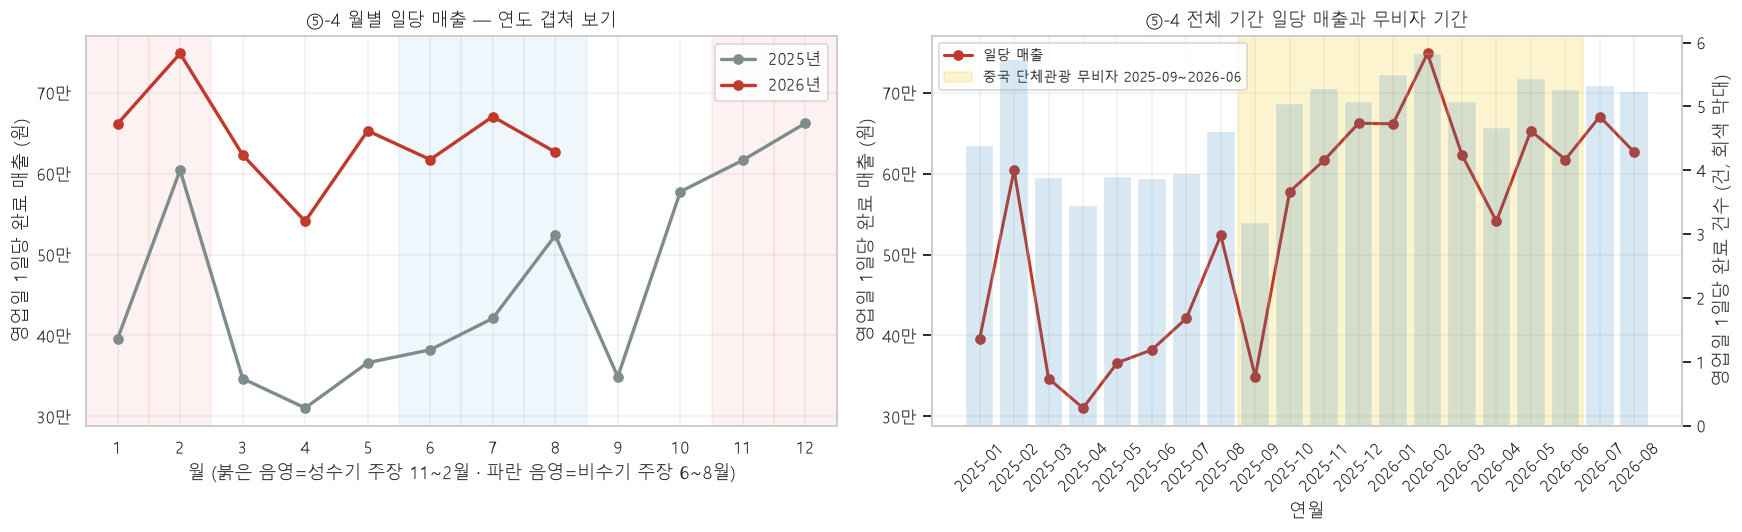

In [44]:
# ── ⑤-4 그래프: 연도 겹침 + 무비자 기간 음영 ─────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

ax = axes[0]
for yr, color in [(2025, "#7f8c8d"), (2026, "#c0392b")]:
    g = _mon[_mon.연도 == yr]
    ax.plot(g.월, g["일당 매출"], marker="o", lw=2.2, color=color, label=f"{yr}년")
for m in PEAK_M:
    ax.axvspan(m-0.5, m+0.5, color="#e74c3c", alpha=.07)
for m in LOW_M:
    ax.axvspan(m-0.5, m+0.5, color="#3498db", alpha=.07)
ax.set_xticks(range(1, 13)); ax.set_xlim(0.5, 12.5)
ax.set_xlabel("월 (붉은 음영=성수기 주장 11~2월 · 파란 음영=비수기 주장 6~8월)")
ax.set_ylabel("영업일 1일당 완료 매출 (원)")
ax.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, p: f"{v/10000:.0f}만"))
ax.set_title("⑤-4 월별 일당 매출 — 연도 겹쳐 보기")
ax.legend()

ax = axes[1]
_x = _mon.index.astype(str)
ax.plot(_x, _mon["일당 매출"], marker="o", color="#c0392b", lw=2, label="일당 매출")
_vs = [i for i, p in enumerate(_mon.index) if VISA_FREE[0] <= p <= VISA_FREE[1]]
ax.axvspan(min(_vs)-0.5, max(_vs)+0.5, color="#f1c40f", alpha=.20,
           label="중국 단체관광 무비자 2025-09~2026-06")
ax.set_xlabel("연월"); ax.set_ylabel("영업일 1일당 완료 매출 (원)")
ax.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, p: f"{v/10000:.0f}만"))
ax.tick_params(axis="x", rotation=45)
ax.set_title("⑤-4 전체 기간 일당 매출과 무비자 기간")
ax2 = ax.twinx(); ax2.grid(False)
ax2.bar(_x, _mon["일당 완료건수"], alpha=.18, color="#2980b9")
ax2.set_ylabel("영업일 1일당 완료 건수 (건, 회색 막대)")
ax.legend(fontsize=9, loc="upper left")
plt.tight_layout(); plt.show()

## ⑤-5 요일 패턴 — 방학 vs 학기

> 사장님: **"방학 아닐 때는 일요일·주말 강세, 방학 때는 평일 강세. 주 타깃이 대학생이라"**

**방학 정의(노트북에 명시)**: 여름 **6/20 ~ 8/31**, 겨울 **12/20 ~ 2/28**. 그 외는 학기.
대학 학사일정의 통상 범위를 쓴 것이며, 실제 학사일정 데이터는 없다.

②번 요일 분석은 전 기간 통합이라 이 효과가 상쇄돼 있을 수 있으므로 **반드시 대조**한다.
두 기간의 요일 분포가 다른지는 **카이제곱 독립성 검정**으로 본다(scipy 없이 직접 계산).

In [45]:
# ── ⑤-5a 방학 구간 정의 ──────────────────────────────────────────────────────
def _is_vacation(d):
    m, day = d.month, d.day
    if (m == 6 and day >= 20) or m in (7, 8):          # 여름 6/20~8/31
        return True
    if (m == 12 and day >= 20) or m in (1, 2):         # 겨울 12/20~2/28(29)
        return True
    return False

DONE["방학"] = DONE.use_dt.map(_is_vacation)
R["방학"]    = R.use_dt.map(_is_vacation)
_vd = DONE.date.drop_duplicates().to_frame("date")
_vd["방학"] = _vd.date.map(_is_vacation)
_vd["dow_ko"] = _vd.date.dt.dayofweek.map(lambda i: DOW_KO[i])
BIZ_VD = _vd.groupby(["방학", "dow_ko"]).size().rename("영업일수")

print(f"방학 기간 완료 {int(DONE.방학.sum()):,}건 / 학기 {int((~DONE.방학).sum()):,}건")
print(f"방학 영업일 {int(_vd.방학.sum())}일 / 학기 영업일 {int((~_vd.방학).sum())}일")

방학 기간 완료 1,302건 / 학기 1,430건
방학 영업일 258일 / 학기 영업일 322일


In [46]:
# ── ⑤-5b 방학/학기 x 요일 ────────────────────────────────────────────────────
_vc = (DONE.groupby(["방학", "dow_ko"])
           .agg(완료건수=("예약번호", "size"), 매출=("paid", "sum"))
           .join(BIZ_VD))
_vc["일당 완료건수"] = _vc.완료건수 / _vc.영업일수
_vc["일당 매출"]     = _vc.매출 / _vc.영업일수
_vc = _vc.reset_index()
_vc["구간"] = np.where(_vc.방학, "방학", "학기")

PV_N = _vc.pivot(index="구간", columns="dow_ko", values="일당 완료건수")[DOW_KO]
PV_M = _vc.pivot(index="구간", columns="dow_ko", values="일당 매출")[DOW_KO]
PV_C = _vc.pivot(index="구간", columns="dow_ko", values="완료건수")[DOW_KO]
tbl(PV_C, "⑤-5b1 방학/학기 x 요일 완료 건수 (원자료)")
tbl(PV_N.round(3), "⑤-5b2 방학/학기 x 요일 영업일 1일당 완료 건수")
tbl(PV_M.round(0), "⑤-5b3 방학/학기 x 요일 영업일 1일당 매출 (원)")

_share = PV_C.div(PV_C.sum(axis=1), axis=0) * 100
tbl(_share.round(2), "⑤-5b4 각 구간 내 요일 구성비 (%) — 이 두 줄이 다른지를 검정한다")

**⑤-5b1 방학/학기 x 요일 완료 건수 (원자료)**

dow_ko,월,화,수,목,금,토,일
구간,,,,,,,
방학,209,166,181,198,227,176,145
학기,207,154,169,207,305,207,181


**⑤-5b2 방학/학기 x 요일 영업일 1일당 완료 건수**

dow_ko,월,화,수,목,금,토,일
구간,,,,,,,
방학,5.649,4.743,5.171,5.211,6.135,4.4,4.028
학기,4.600,3.277,3.521,4.600,6.489,4.6,4.022


**⑤-5b3 방학/학기 x 요일 영업일 1일당 매출 (원)**

dow_ko,월,화,수,목,금,토,일
구간,,,,,,,
방학,660946.0,564257.0,634186.0,627553.0,690027.0,484700.0,416194.0
학기,525756.0,372936.0,384000.0,516533.0,743543.0,481337.0,430144.0


**⑤-5b4 각 구간 내 요일 구성비 (%) — 이 두 줄이 다른지를 검정한다**

dow_ko,월,화,수,목,금,토,일
구간,,,,,,,
방학,16.05,12.75,13.90,15.21,17.43,13.52,11.14
학기,14.48,10.77,11.82,14.48,21.33,14.48,12.66


In [47]:
# ── ⑤-5c 카이제곱 독립성 검정 (scipy 없이 직접) ──────────────────────────────
import math

def _gammq(s, x):
    """정규화 상부 불완전감마 Q(s,x). 카이제곱 p값용 (Numerical Recipes gammq)."""
    if x < 0 or s <= 0:
        return float("nan")
    if x == 0:
        return 1.0
    if x < s + 1.0:                                   # 급수 전개
        ap, total, d = s, 1.0/s, 1.0/s
        for _ in range(2000):
            ap += 1.0; d *= x/ap; total += d
            if abs(d) < abs(total)*1e-15:
                break
        return 1.0 - total*math.exp(-x + s*math.log(x) - math.lgamma(s))
    tiny = 1e-300                                     # 연분수
    b = x + 1.0 - s; c = 1.0/tiny; d = 1.0/b; h = d
    for i in range(1, 2000):
        an = -i*(i - s); b += 2.0
        d = an*d + b
        if abs(d) < tiny: d = tiny
        c = b + an/c
        if abs(c) < tiny: c = tiny
        d = 1.0/d; de = d*c; h *= de
        if abs(de - 1.0) < 1e-15:
            break
    return h*math.exp(-x + s*math.log(x) - math.lgamma(s))

def chi2_test(obs):
    O = obs.values.astype(float)
    E = np.outer(O.sum(1), O.sum(0)) / O.sum()
    chi2 = float(((O - E)**2 / E).sum())
    df = (O.shape[0]-1) * (O.shape[1]-1)
    return chi2, df, _gammq(df/2.0, chi2/2.0), pd.DataFrame(E, index=obs.index, columns=obs.columns)

_chi2, _df, _pv, _E = chi2_test(PV_C)
tbl(_E.round(1), "⑤-5c 기대도수 (두 구간의 요일 분포가 같다고 가정했을 때)")
_res = pd.DataFrame([{"카이제곱 통계량": _chi2, "자유도": _df, "p-value": _pv,
                      "임계값 α=0.05": 12.592, "임계값 α=0.01": 16.812,
                      "판정": "유의미하게 다름" if _pv < 0.05 else "차이가 유의하지 않음"}])
tbl(_res.round(4), "⑤-5c2 카이제곱 독립성 검정 결과 (방학/학기 x 요일)")

_wk = ["토", "일"]
_v_wknd = PV_C.loc["방학", _wk].sum() / PV_C.loc["방학"].sum() * 100
_s_wknd = PV_C.loc["학기", _wk].sum() / PV_C.loc["학기"].sum() * 100
print(f"주말(토·일) 비중 — 방학 {_v_wknd:.2f}% vs 학기 {_s_wknd:.2f}% (차이 {_v_wknd-_s_wknd:+.2f}%p)")
print()
print("②번(전 기간 통합) 요일 1일당 완료 건수와 대조:")
_cross = pd.DataFrame({"② 전기간": _dw["요일1회당 완료"],
                       "방학": PV_N.loc["방학"], "학기": PV_N.loc["학기"]})
_cross["방학−학기"] = _cross.방학 - _cross.학기
tbl(_cross.round(3), "⑤-5d ②번 전기간 vs 방학/학기 분리 — 상쇄 여부 확인")

verdict("5-5", "방학 아닐 때 일요일·주말 강세 / 방학 때 평일 강세",
        f"주말 비중은 방학 {_v_wknd:.2f}% vs 학기 {_s_wknd:.2f}% ({_v_wknd-_s_wknd:+.2f}%p). "
        f"카이제곱 검정 χ²={_chi2:.2f} (df={_df}, p={_pv:.4f}) → "
        f"{'두 기간의 요일 분포는 유의미하게 다르다' if _pv < 0.05 else '두 기간의 요일 분포 차이는 유의하지 않다'}.",
        ("확인됨" if (_pv < 0.05 and _s_wknd > _v_wknd) else
         ("부분 확인" if _pv < 0.05 else "데이터와 다름")),
        "방학 구간을 6/20~8/31, 12/20~2/28 로 임의 정의했다. 실제 대학 학사일정이 다르면 결과가 바뀐다. "
        "또 방학은 계절(성수기/비수기)과 겹쳐 있어 두 효과가 분리되지 않는다.")

**⑤-5c 기대도수 (두 구간의 요일 분포가 같다고 가정했을 때)**

dow_ko,월,화,수,목,금,토,일
구간,,,,,,,
방학,198.3,152.5,166.8,193.0,253.5,182.5,155.4
학기,217.7,167.5,183.2,212.0,278.5,200.5,170.6


**⑤-5c2 카이제곱 독립성 검정 결과 (방학/학기 x 요일)**

,카이제곱 통계량,자유도,p-value,임계값 α=0.05,임계값 α=0.01,판정
0,13.0232,6,0.0427,12.592,16.812,유의미하게 다름


주말(토·일) 비중 — 방학 24.65% vs 학기 27.13% (차이 -2.48%p)

②번(전 기간 통합) 요일 1일당 완료 건수와 대조:


**⑤-5d ②번 전기간 vs 방학/학기 분리 — 상쇄 여부 확인**

,② 전기간,방학,학기,방학−학기
dow_ko,,,,
월,5.073,5.649,4.600,1.049
화,3.902,4.743,3.277,1.466
수,4.217,5.171,3.521,1.651
목,4.880,5.211,4.600,0.611
금,6.333,6.135,6.489,-0.354
토,4.506,4.400,4.600,-0.200
일,4.025,4.028,4.022,0.006


> **판정 5-5 — 확인됨**  
> 주말 비중은 방학 24.65% vs 학기 27.13% (-2.48%p). 카이제곱 검정 χ²=13.02 (df=6, p=0.0427) → 두 기간의 요일 분포는 유의미하게 다르다.

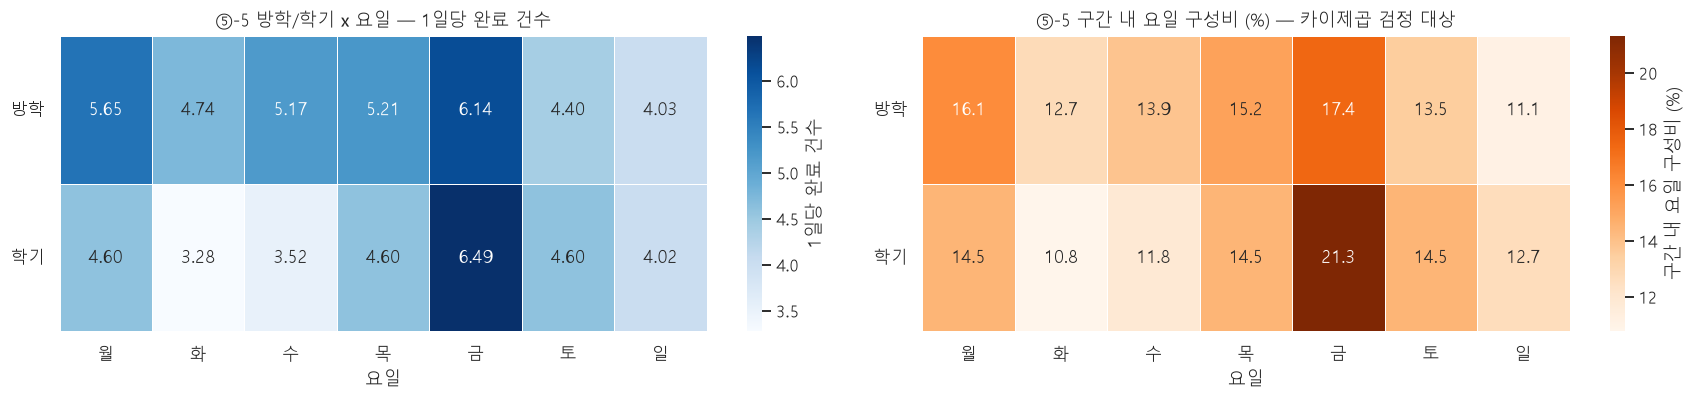

In [48]:
# ── ⑤-5 그래프: 방학/학기 x 요일 히트맵 ──────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 3.8))
sns.heatmap(PV_N, annot=True, fmt=".2f", cmap="Blues", ax=axes[0],
            linewidths=.5, linecolor="white", cbar_kws={"label": "1일당 완료 건수"})
axes[0].set_title("⑤-5 방학/학기 x 요일 — 1일당 완료 건수")
axes[0].set_xlabel("요일"); axes[0].set_ylabel("")
axes[0].set_yticklabels(axes[0].get_yticklabels(), rotation=0)

sns.heatmap(_share, annot=True, fmt=".1f", cmap="Oranges", ax=axes[1],
            linewidths=.5, linecolor="white", cbar_kws={"label": "구간 내 요일 구성비 (%)"})
axes[1].set_title("⑤-5 구간 내 요일 구성비 (%) — 카이제곱 검정 대상")
axes[1].set_xlabel("요일"); axes[1].set_ylabel("")
axes[1].set_yticklabels(axes[1].get_yticklabels(), rotation=0)
plt.tight_layout(); plt.show()

## ⑤-6 주 고객층 — 대학생 · 수험생

> 사장님: **"대학생, 시험 끝난 수험생"**

**⚠️ 연령 데이터가 없다. 대학생 비중은 직접 검증 불가다.**
아래 두 가지는 **간접 증거**일 뿐이며, 인과로 읽으면 안 된다.

1. `수험생탈색`·`수험생탈색이벤트` 메뉴의 월별 건수 — 수능(11월 중순) 직후에 몰리는가
2. 방학 기간 신규 고객 유입이 학기 중보다 높은가

In [49]:
# ── ⑤-6a 수험생 메뉴 월별 ────────────────────────────────────────────────────
_exam = LX[LX.menu.str.contains("수험|考生|examinee", case=False, regex=True)]
_ex_m = (_exam[_exam.status == "이용완료"].groupby("ym")
              .agg(라인수=("menu", "size"), 매출=("line_price", "sum")))
_ex_m = _ex_m.reindex(_mon.index).fillna(0).astype({"라인수": int, "매출": int})
_ex_m["완료건수(전체)"] = _mon.완료건수
_ex_m["수험생 비중(%)"] = _ex_m.라인수 / _ex_m["완료건수(전체)"] * 100
_ex_m["수능 직후(11~1월)"] = [p.month in (11, 12, 1) for p in _ex_m.index]
tbl(_ex_m.round(2), "⑤-6a 수험생 계열 메뉴의 월별 라인 수 (완료 건)")

_post = _ex_m[_ex_m["수능 직후(11~1월)"]].라인수.sum()
_tot  = _ex_m.라인수.sum()
print(f"수험생 메뉴 총 {_tot:,}라인 중 11~1월이 {_post:,}라인 ({_post/_tot*100:.2f}%)")
print(f"11~1월은 20개월 중 5개월({5/20*100:.0f}%)이므로, 균등하다면 {5/20*100:.0f}% 여야 한다.")

**⑤-6a 수험생 계열 메뉴의 월별 라인 수 (완료 건)**

,라인수,매출,완료건수(전체),수험생 비중(%),수능 직후(11~1월)
ym,,,,,
2025-01,21,3150000,127,16.54,True
2025-02,32,4800000,149,21.48,False
2025-03,5,750000,120,4.17,False
2025-04,0,0,103,0.00,False
2025-05,0,0,117,0.00,False
2025-06,0,0,108,0.00,False
2025-07,0,0,118,0.00,False
2025-08,0,0,138,0.00,False
2025-09,0,0,92,0.00,False


수험생 메뉴 총 194라인 중 11~1월이 123라인 (63.40%)
11~1월은 20개월 중 5개월(25%)이므로, 균등하다면 25% 여야 한다.


In [50]:
# ── ⑤-6b 방학 vs 학기 신규 유입 ──────────────────────────────────────────────
_nv = (DONE.groupby("방학")
           .agg(완료건수=("예약번호", "size"), 신규=("신규고객", "sum")))
_nv["영업일수"]     = _vd.groupby("방학").size()
_nv["신규 비중(%)"] = _nv.신규 / _nv.완료건수 * 100
_nv["일당 신규"]    = _nv.신규 / _nv.영업일수
_nv.index = ["학기", "방학"]
tbl(_nv.round(3), "⑤-6b 방학/학기 신규 고객 유입")

verdict("5-6", "주 고객층은 대학생과 시험 끝난 수험생",
        f"수험생 계열 메뉴 {_tot:,}라인 중 {_post/_tot*100:.1f}%가 11~1월(수능 직후)에 몰려 있다 "
        f"— 균등 분포라면 25%다. 방학 기간 일당 신규 고객은 {_nv.loc['방학','일당 신규']:.2f}명, "
        f"학기 중은 {_nv.loc['학기','일당 신규']:.2f}명이다.",
        "부분 확인",
        "⚠️ 연령·학적 필드가 없어 '대학생'은 직접 검증 불가다. 수험생 메뉴의 11~1월 집중은 "
        "메뉴명이 '수험생'이라 자기실현적이며, 그 메뉴를 고르지 않은 수험생은 잡히지 않는다. "
        "간접 증거로만 읽어야 한다.")

**⑤-6b 방학/학기 신규 고객 유입**

,완료건수,신규,영업일수,신규 비중(%),일당 신규
학기,1430,749,322,52.378,2.326
방학,1302,808,258,62.058,3.132


> **판정 5-6 — 부분 확인**  
> 수험생 계열 메뉴 194라인 중 63.4%가 11~1월(수능 직후)에 몰려 있다 — 균등 분포라면 25%다. 방학 기간 일당 신규 고객은 3.13명, 학기 중은 2.33명이다.

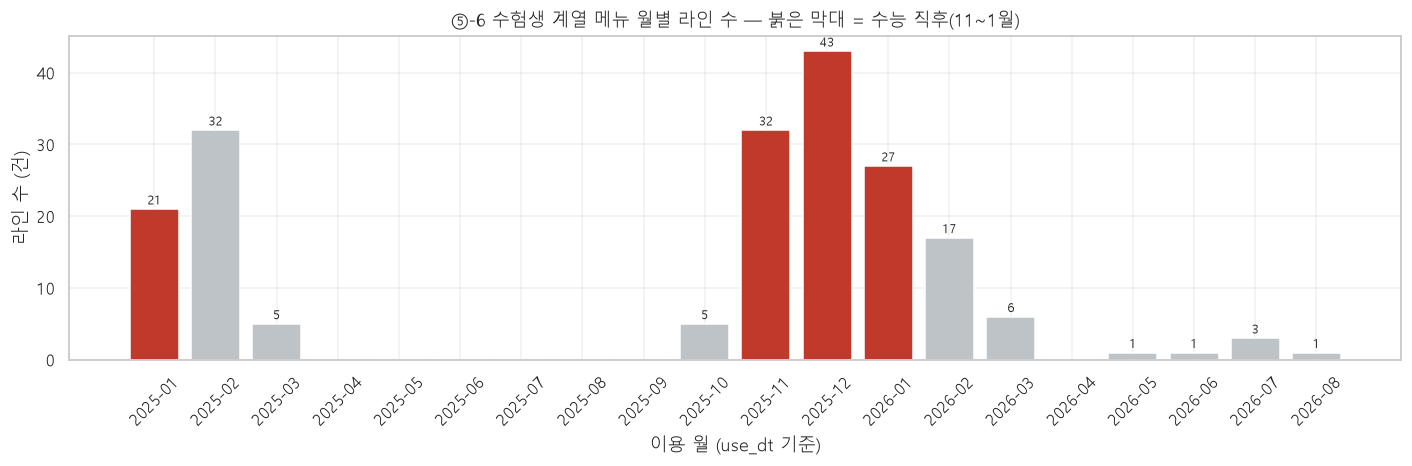

In [51]:
# ── ⑤-6 그래프 ───────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(13, 4.4))
_x = _ex_m.index.astype(str)
_c = ["#c0392b" if m else "#bdc3c7" for m in _ex_m["수능 직후(11~1월)"]]
ax.bar(_x, _ex_m.라인수, color=_c)
for i, v in enumerate(_ex_m.라인수):
    if v > 0:
        ax.annotate(int(v), (i, v), textcoords="offset points", xytext=(0, 3), ha="center", fontsize=8)
ax.set_title("⑤-6 수험생 계열 메뉴 월별 라인 수 — 붉은 막대 = 수능 직후(11~1월)")
ax.set_xlabel("이용 월 (use_dt 기준)"); ax.set_ylabel("라인 수 (건)")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

## ⑤-7 외국인 — 중국 비중

> 사장님: **"중국 비중 높고 일본·동남아는 적음"**

**⚠️ 국적 필드가 없다.** 네이버 예약 원본에 언어·국가 컬럼이 아예 없다.
유일한 대리 지표는 **메뉴명 문자종**이다 — 네이버 플레이스가 외국어 UI 사용자에게
메뉴명을 자동 번역해 보여주고, export에 그 문자열이 그대로 찍히기 때문이다.
(25종 각각이 어느 한국어 메뉴의 번역인지는 `make_menu_category.py` 의 `MENU_KO` 에 있다 — 단가·판매 시기·같은 예약의 POS(핸즈) 기록으로 확인한 대응이다.)
대리 지표일 뿐이며 국적을 말해주지 않는다.

In [52]:
# ── ⑤-7a 메뉴 언어별 (01번 ⑧-2 기준 유지) ───────────────────────────────────
_HANGUL = re.compile(r"[가-힣]")
_CJK    = re.compile("[一-鿿぀-ゟ゠-ヿ]")
_KANA   = re.compile("[぀-ゟ゠-ヿ]")
_LATIN  = re.compile(r"[A-Za-z]")

def _lang(s):
    if _HANGUL.search(s): return "한국어"
    if _CJK.search(s):    return "중국어·일본어"
    if _LATIN.search(s):  return "영어"
    return "기타"

LX["lang"] = LX.menu.map(_lang)
LANG_ORDER = ["한국어", "중국어·일본어", "영어", "기타"]
_lg = (LX.groupby("lang")
         .agg(라인수=("menu", "size"), 취소라인=("status", lambda s: int((s == "취소").sum())),
              완료라인=("status", lambda s: int((s == "이용완료").sum())), 메뉴종수=("menu", "nunique"))
         .reindex(LANG_ORDER).dropna(how="all")
         .astype({"라인수": int, "취소라인": int, "완료라인": int, "메뉴종수": int}))
_lg["취소율(%)"]   = _lg.취소라인 / _lg.라인수 * 100
_lg["라인비중(%)"] = _lg.라인수 / len(LX) * 100
_lg["소표본"]      = _lg.라인수.map(lambda n: small(n))
tbl(_lg.round(2), "⑤-7a 메뉴 언어별 라인 수와 취소율 — ★라인 기준★ (01번 ⑧-2와 동일)")

_exp7 = {"한국어": 36.75, "중국어·일본어": 21.54, "영어": 25.00}
_chk7 = pd.DataFrame({"이번": _lg["취소율(%)"].round(2), "01번 ⑧-2": pd.Series(_exp7)}).dropna()
_chk7["일치"] = np.where(_chk7.이번 == _chk7["01번 ⑧-2"], "OK", "★불일치")
tbl(_chk7, "⑤-7a2 01번 ⑧-2 대조")
assert (_chk7.일치 == "OK").all(), "01번 메뉴 언어별 취소율과 불일치"

# 중국어(한자만) vs 일본어(가나 포함) 분리
_fx = LX[LX.lang == "중국어·일본어"].copy()
_fx["세부"] = np.where(_fx.menu.str.contains(_KANA), "일본어(가나 포함)", "중국어(한자만)")
_fx2 = _fx.groupby("세부").agg(라인수=("menu", "size"), 메뉴종수=("menu", "nunique"))
_fx2["소표본"] = _fx2.라인수.map(lambda n: small(n))
tbl(_fx2, "⑤-7b 중국어 vs 일본어 분리 (한자만 = 중국어 간체/번체 추정)")

**⑤-7a 메뉴 언어별 라인 수와 취소율 — ★라인 기준★ (01번 ⑧-2와 동일)**

,라인수,취소라인,완료라인,메뉴종수,취소율(%),라인비중(%),소표본
lang,,,,,,,
한국어,7069,2598,4459,68,36.75,98.70,
중국어·일본어,65,14,51,17,21.54,0.91,
영어,28,7,21,8,25.00,0.39,⚠소표본


**⑤-7a2 01번 ⑧-2 대조**

,이번,01번 ⑧-2,일치
한국어,36.75,36.75,OK
중국어·일본어,21.54,21.54,OK
영어,25.00,25.00,OK


**⑤-7b 중국어 vs 일본어 분리 (한자만 = 중국어 간체/번체 추정)**

,라인수,메뉴종수,소표본
세부,,,
일본어(가나 포함),15,5,⚠소표본
중국어(한자만),50,12,


In [53]:
# ── ⑤-7c 요청사항·취소사유의 한자 사용 ───────────────────────────────────────
_HANZI = re.compile("[一-鿿]")
_txt = []
for col in ["요청사항", "취소사유", "직원메모"]:
    v = R[col].dropna().astype(str)
    _txt.append({"필드": col, "작성된 건수": len(v),
                 "한자 포함 건수": int(v.str.contains(_HANZI, regex=True).sum())})
tbl(pd.DataFrame(_txt), "⑤-7c 자유 텍스트 필드의 한자 사용")

**⑤-7c 자유 텍스트 필드의 한자 사용**

,필드,작성된 건수,한자 포함 건수
0,요청사항,427,0
1,취소사유,882,1
2,직원메모,1,0


In [54]:
# ── ⑤-7d 무비자 기간 전후 외국어 메뉴 예약 ───────────────────────────────────
_per_res = LX.groupby("예약번호").lang.agg(lambda s: sorted(set(s))[0] if len(set(s)) == 1 else "혼합")
R["예약언어"] = R.예약번호.map(_per_res)
_fl = (R.groupby(["ym", "예약언어"]).size().unstack(fill_value=0)
        .reindex(columns=["한국어", "중국어·일본어", "영어", "혼합"], fill_value=0))
_fl["외국어 계"]   = _fl["중국어·일본어"] + _fl["영어"]
_fl["전체 예약"]   = _fl.sum(axis=1) - _fl["외국어 계"]
_fl["외국어 비중(%)"] = _fl["외국어 계"] / _fl["전체 예약"] * 100
_fl["무비자기간"]  = [(VISA_FREE[0] <= p <= VISA_FREE[1]) for p in _fl.index]
tbl(_fl.round(2), "⑤-7d 월별 예약 언어 (예약 단위 · 한 예약 안에서 언어가 섞인 경우는 0건)")

_in  = _fl[_fl.무비자기간]["외국어 계"].sum()
_out = _fl[~_fl.무비자기간]["외국어 계"].sum()
_in_m, _out_m = int(_fl.무비자기간.sum()), int((~_fl.무비자기간).sum())
print(f"무비자 기간({_in_m}개월) 외국어 예약 {_in}건 · 월평균 {_in/_in_m:.2f}건")
print(f"그 외 기간({_out_m}개월)   외국어 예약 {_out}건 · 월평균 {_out/_out_m:.2f}건")

_cn = int(_fx2.loc["중국어(한자만)", "라인수"]) if "중국어(한자만)" in _fx2.index else 0
_jp = int(_fx2.loc["일본어(가나 포함)", "라인수"]) if "일본어(가나 포함)" in _fx2.index else 0
verdict("5-7", "중국 비중이 높고 일본·동남아는 적다",
        f"메뉴 언어 기준 외국어 라인은 {int(_lg.loc['중국어·일본어','라인수'])+int(_lg.loc['영어','라인수'])}건"
        f"(전체 라인의 {(_lg.loc['중국어·일본어','라인비중(%)']+_lg.loc['영어','라인비중(%)']):.2f}%)뿐이고, "
        f"그중 중국어(한자만) {_cn}라인 · 일본어(가나) {_jp}라인이다. 방향은 중국 > 일본으로 일치한다. "
        f"무비자 기간 월평균 {_in/_in_m:.2f}건 vs 그 외 {_out/_out_m:.2f}건.",
        "부분 확인",
        "⚠️ 국적 필드가 없다. 메뉴 언어는 예약 시점 UI 언어일 뿐이고, 한국어 UI로 예약한 외국인은 "
        "전혀 잡히지 않는다. 표본이 45건이라 비율 해석 불가. 동남아는 지표 자체가 없다.")

**⑤-7d 월별 예약 언어 (예약 단위 · 한 예약 안에서 언어가 섞인 경우는 0건)**

예약언어,한국어,중국어·일본어,영어,혼합,외국어 계,전체 예약,외국어 비중(%),무비자기간
ym,,,,,,,,
2025-01,218,0,0,0,0,218,0.00,False
2025-02,217,0,0,0,0,217,0.00,False
2025-03,184,0,0,0,0,184,0.00,False
2025-04,154,0,0,0,0,154,0.00,False
2025-05,168,0,0,0,0,168,0.00,False
2025-06,159,0,1,0,1,160,0.62,False
2025-07,180,0,0,0,0,180,0.00,False
2025-08,200,0,0,0,0,200,0.00,False
2025-09,127,0,0,0,0,127,0.00,True


무비자 기간(10개월) 외국어 예약 38건 · 월평균 3.80건
그 외 기간(10개월)   외국어 예약 7건 · 월평균 0.70건


> **판정 5-7 — 부분 확인**  
> 메뉴 언어 기준 외국어 라인은 93건(전체 라인의 1.30%)뿐이고, 그중 중국어(한자만) 50라인 · 일본어(가나) 15라인이다. 방향은 중국 > 일본으로 일치한다. 무비자 기간 월평균 3.80건 vs 그 외 0.70건.

## ⑤-8 재방문 할인 인지 문제 — 사장님이 우선순위 1번으로 꼽으신 것

> 사장님: **"재방문에도 같은 할인이 되는데 고객이 '첫 방문만'인 줄 알고 안 온다"**

이 항목이 개입 설계의 근거가 되므로 가장 꼼꼼하게 본다.

**정의**: "첫방문 50%할인" 은 `channel`(유입경로)이 아니라 **`designer` 컬럼 값**이다
(`designer == "첫방문 50%할인 헤어살롱 본점 (구)헤어공방 미지정전용예약"`, 413건).
그래서 designer 문자열로 판정한다. 01번 ⑤-4와 같은 방식이다.

"재방문 고객"은 **그 예약의 `use_dt` 이전에 그 `cust_key` 의 완료 방문이 있었는가**로 판정한다.

In [55]:
# ── ⑤-8a 이 채널을 재방문 고객이 쓰고 있는가 ─────────────────────────────────
F50 = "첫방문 50%할인"
R["f50"] = R.designer.str.contains(F50, na=False)
R["기존고객"] = [_had_prev_done(k, d) for k, d in zip(R.cust_key, R.use_dt)]

_f = R[R.f50]
_ct = pd.crosstab(_f.기존고객, _f.status, margins=True, margins_name="합계")
_ct.index = ["신규(이전 방문 없음)", "재방문(이전 방문 있음)", "합계"][:len(_ct)]
tbl(_ct, f"⑤-8a 첫방문 50%할인 채널 {len(_f):,}건 — 신규 vs 재방문 x 상태")

_a = (_f.groupby("기존고객")
        .agg(예약=("예약번호", "size"), 취소=("status", lambda s: int((s == "취소").sum())),
             완료=("status", lambda s: int((s == "이용완료").sum()))))
_a["취소율(%)"] = _a.취소 / _a.예약 * 100
_a["완료 객단가 중앙값"] = R[R.f50 & (R.status == "이용완료")].groupby("기존고객").paid.median()
_a.index = ["신규", "재방문"]
tbl(_a.round(2), "⑤-8a2 이 채널 내 신규 vs 재방문")
print(f"이 채널 {len(_f):,}건 중 재방문 고객의 예약은 {int(_f.기존고객.sum()):,}건 "
      f"({_f.기존고객.mean()*100:.2f}%)")
print("→ 이미 일부 고객은 재방문에도 이 채널을 쓰고 있다. '아무도 모른다'는 아니다.")

**⑤-8a 첫방문 50%할인 채널 413건 — 신규 vs 재방문 x 상태**

status,노쇼,이용완료,취소,합계
신규(이전 방문 없음),1,170,157,328
재방문(이전 방문 있음),0,48,37,85
합계,1,218,194,413


**⑤-8a2 이 채널 내 신규 vs 재방문**

,예약,취소,완료,취소율(%),완료 객단가 중앙값
신규,328,157,170,47.87,100000.0
재방문,85,37,48,43.53,39000.0


이 채널 413건 중 재방문 고객의 예약은 85건 (20.58%)
→ 이미 일부 고객은 재방문에도 이 채널을 쓰고 있다. '아무도 모른다'는 아니다.


In [56]:
# ── ⑤-8b 이 채널로 첫 방문한 고객의 재방문율 ─────────────────────────────────
CUST["첫방문_f50"] = CUST.첫디자이너.str.contains(F50, na=False)
_b = (CUST.groupby("첫방문_f50")
          .agg(인원=("방문횟수", "size"), 재방문율=("재방문", "mean"), _3회=("3회이상", "mean"),
               평균방문횟수=("방문횟수", "mean"), 첫방문paid중앙=("첫방문paid", "median"),
               누적지출평균=("누적지출", "mean")))
_b["재방문율(%)"] = _b.재방문율 * 100
_b["3회이상(%)"]  = _b._3회 * 100
_b = _b.drop(columns=["재방문율", "_3회"])
_b.index = ["일반 채널로 첫 방문", "첫방문50%할인으로 첫 방문"]
tbl(_b.round(2), "⑤-8b 첫 방문 채널별 재방문율 (완료 기준 고객)")

**⑤-8b 첫 방문 채널별 재방문율 (완료 기준 고객)**

,인원,평균방문횟수,첫방문paid중앙,누적지출평균,재방문율(%),3회이상(%)
일반 채널로 첫 방문,1387,1.76,150000.0,199197.66,25.59,11.25
첫방문50%할인으로 첫 방문,170,1.75,100000.0,192285.29,32.94,10.00


In [57]:
# ── ⑤-8c 할인받고 온 고객의 2회차 금액 ───────────────────────────────────────
_c50 = set(CUST[CUST.첫방문_f50].index)
_seq = DONE[DONE.cust_key.isin(_c50)].sort_values("use_dt")
_second = _seq.groupby("cust_key").nth(1)          # 2회차
_first50 = CUST.loc[list(_c50)]

_pay = pd.DataFrame({
    "구분": ["1회차 (할인 채널)", "2회차"],
    "인원": [len(_first50), len(_second)],
    "paid 중앙값": [_first50.첫방문paid.median(), _second.paid.median()],
    "paid 평균":   [_first50.첫방문paid.mean(),   _second.paid.mean()],
})
tbl(_pay.round(0), "⑤-8c 첫 방문을 할인 채널로 한 고객의 1회차 vs 2회차 결제금액")

_reuse = _second.designer.str.contains(F50, na=False)
print(f"2회차가 있는 고객 {len(_second):,}명 중 2회차에도 이 채널을 쓴 사람: "
      f"{int(_reuse.sum()):,}명 ({_reuse.mean()*100:.2f}%)")
_up = (_second.set_index("cust_key").paid - _first50.첫방문paid).dropna()
print(f"2회차 − 1회차 금액 차: 중앙값 {_up.median():,.0f}원 · "
      f"올라간 사람 {int((_up>0).sum())}명 / 같음 {int((_up==0).sum())}명 / 내려간 사람 {int((_up<0).sum())}명")
tbl(_up.describe(percentiles=[.25, .5, .75]).round(0).to_frame("2회차 − 1회차 (원)"),
    "⑤-8c2 금액 변화 분포")

_v8 = (f"이 채널 {len(_f):,}건 중 재방문 고객 예약이 {int(_f.기존고객.sum()):,}건({_f.기존고객.mean()*100:.1f}%)로 "
       f"이미 일부는 쓰고 있다. 이 채널로 첫 방문한 고객의 재방문율은 {_b.loc['첫방문50%할인으로 첫 방문','재방문율(%)']:.2f}%로 "
       f"일반 채널 {_b.loc['일반 채널로 첫 방문','재방문율(%)']:.2f}%보다 오히려 높다. "
       f"다만 2회차에 이 채널을 다시 쓴 고객은 {_reuse.mean()*100:.1f}%뿐이고, "
       f"결제금액 중앙값이 {_first50.첫방문paid.median():,.0f}원 → {_second.paid.median():,.0f}원으로 올라간다.")
verdict("5-8", "재방문에도 같은 할인이 되는데 고객이 '첫 방문만'인 줄 알고 안 온다",
        _v8, "부분 확인",
        f"2회차 채널 재사용률 {_reuse.mean()*100:.1f}%와 결제금액 상승은 사장님 가설(할인 인지 부족)과 정합한다. "
        f"다만 '할인을 몰라서 안 왔다'는 것은 이 데이터로 증명할 수 없다 — 안 온 고객이 왜 안 왔는지 필드가 없다. "
        f"2회차 표본이 {len(_second)}명이라 소표본이다. 개입(재방문 시 할인 고지) 후 A/B로 확인해야 한다.")

**⑤-8c 첫 방문을 할인 채널로 한 고객의 1회차 vs 2회차 결제금액**

,구분,인원,paid 중앙값,paid 평균
0,1회차 (할인 채널),170,100000.0,119132.0
1,2회차,56,150000.0,142946.0


2회차가 있는 고객 56명 중 2회차에도 이 채널을 쓴 사람: 11명 (19.64%)
2회차 − 1회차 금액 차: 중앙값 0원 · 올라간 사람 21명 / 같음 25명 / 내려간 사람 10명


**⑤-8c2 금액 변화 분포**

,2회차 − 1회차 (원)
count,56.0
mean,21768.0
std,69239.0
min,-200000.0
25%,0.0
50%,0.0
75%,50000.0
max,230000.0


> **판정 5-8 — 부분 확인**  
> 이 채널 413건 중 재방문 고객 예약이 85건(20.6%)로 이미 일부는 쓰고 있다. 이 채널로 첫 방문한 고객의 재방문율은 32.94%로 일반 채널 25.59%보다 오히려 높다. 다만 2회차에 이 채널을 다시 쓴 고객은 19.6%뿐이고, 결제금액 중앙값이 100,000원 → 150,000원으로 올라간다.

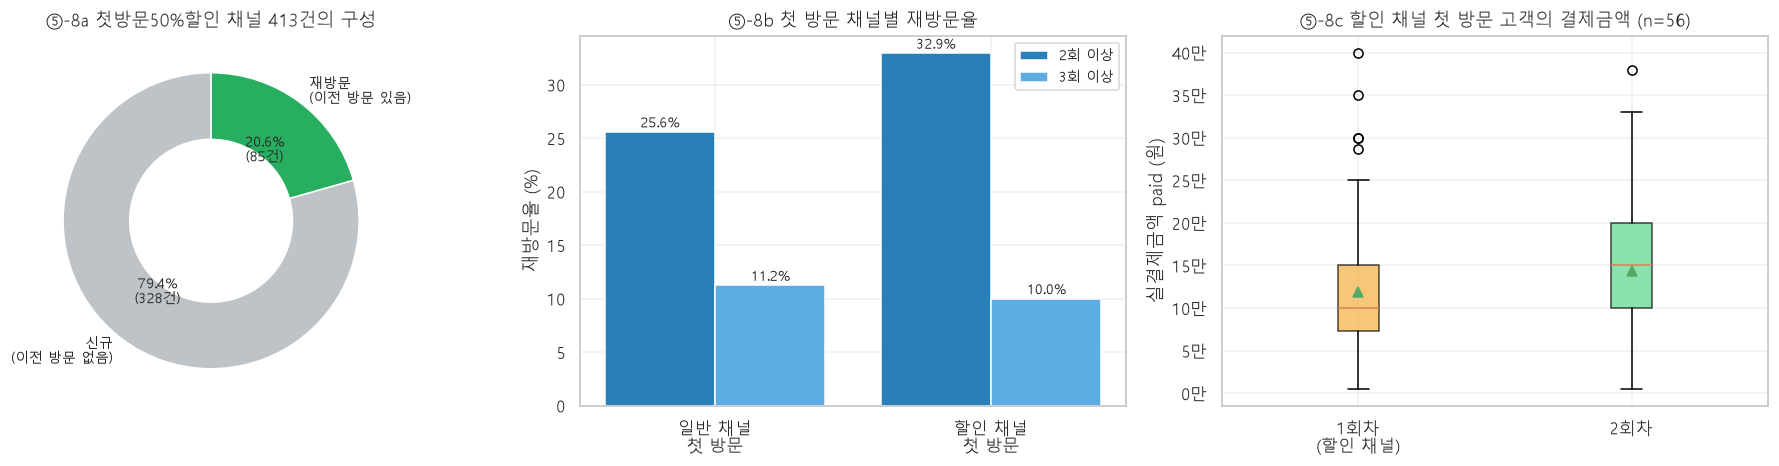

In [58]:
# ── ⑤-8 그래프 ───────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))

ax = axes[0]
_w = _f.기존고객.value_counts().reindex([False, True]).fillna(0)
ax.pie(_w, labels=["신규\n(이전 방문 없음)", "재방문\n(이전 방문 있음)"],
       autopct=lambda p: f"{p:.1f}%\n({int(round(p*_w.sum()/100))}건)",
       colors=["#bdc3c7", "#27ae60"], wedgeprops={"width": 0.45, "edgecolor": "white"},
       startangle=90, textprops={"fontsize": 9})
ax.set_title(f"⑤-8a 첫방문50%할인 채널 {len(_f):,}건의 구성")

ax = axes[1]
_bb = _b[["재방문율(%)", "3회이상(%)"]]
_x = np.arange(len(_bb))
ax.bar(_x - 0.2, _bb["재방문율(%)"], 0.4, color="#2980b9", label="2회 이상")
ax.bar(_x + 0.2, _bb["3회이상(%)"], 0.4, color="#5dade2", label="3회 이상")
for i, (a_, b_) in enumerate(zip(_bb["재방문율(%)"], _bb["3회이상(%)"])):
    ax.annotate(f"{a_:.1f}%", (i-0.2, a_), textcoords="offset points", xytext=(0, 3), ha="center", fontsize=9)
    ax.annotate(f"{b_:.1f}%", (i+0.2, b_), textcoords="offset points", xytext=(0, 3), ha="center", fontsize=9)
ax.set_xticks(_x); ax.set_xticklabels(["일반 채널\n첫 방문", "할인 채널\n첫 방문"])
ax.set_ylabel("재방문율 (%)"); ax.set_title("⑤-8b 첫 방문 채널별 재방문율")
ax.legend(fontsize=9)

ax = axes[2]
bp = ax.boxplot([_first50.첫방문paid.dropna().values, _second.paid.dropna().values],
                tick_labels=["1회차\n(할인 채널)", "2회차"], showmeans=True, patch_artist=True)
for patch, col in zip(bp["boxes"], ["#f5b041", "#58d68d"]):
    patch.set_facecolor(col); patch.set_alpha(.7)
ax.set_title(f"⑤-8c 할인 채널 첫 방문 고객의 결제금액 (n={len(_second)})")
ax.set_ylabel("실결제금액 paid (원)")
ax.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, p: f"{v/10000:.0f}만"))
plt.tight_layout(); plt.show()

## ⑤-9 프로모션 · 이벤트 상시 진행

> 사장님: **"개강 이벤트, 추석 이벤트 등 상시"**

메뉴명에 `이벤트` 가 붙거나, 자동번역 표기에서 그에 해당하는 말(영어·중국어·일본어 하나씩)이 붙은 메뉴를 이벤트 메뉴로 본다.
**메뉴명에 이벤트가 안 붙은 프로모션은 잡히지 않는다** — 이 지표의 한계다.

In [59]:
# ── ⑤-9a 이벤트 메뉴 월별 ────────────────────────────────────────────────────
EV_RE = re.compile("이벤트|Event|活动|イベント", re.I)
LX["이벤트메뉴"] = LX.menu.str.contains(EV_RE)
_evlist = sorted(LX.loc[LX.이벤트메뉴, "menu"].unique())
print(f"이벤트 메뉴 {len(_evlist)}종:", ", ".join(map(mdisp, _evlist)))

_LD2 = LX[LX.status == "이용완료"]
_ev = (_LD2.groupby("ym")
           .agg(전체라인=("menu", "size"), 이벤트라인=("이벤트메뉴", "sum"),
                전체매출=("line_price", "sum")))
_ev["이벤트매출"]     = _LD2[_LD2.이벤트메뉴].groupby("ym").line_price.sum().reindex(_ev.index).fillna(0)
_ev["라인 비중(%)"]   = _ev.이벤트라인 / _ev.전체라인 * 100
_ev["매출 비중(%)"]   = _ev.이벤트매출 / _ev.전체매출 * 100
_ev["월 객단가중앙값"] = _mon.객단가중앙값
tbl(_ev.round(2), "⑤-9a 월별 이벤트 메뉴 비중 (완료 건 · 라인 기준)")
print(f"전 기간 이벤트 라인 비중 {_ev.이벤트라인.sum()/_ev.전체라인.sum()*100:.2f}% · "
      f"매출 비중 {_ev.이벤트매출.sum()/_ev.전체매출.sum()*100:.2f}%")
print(f"이벤트 비중이 0%인 달: {int((_ev['라인 비중(%)'] == 0).sum())}개월 / {len(_ev)}개월")

이벤트 메뉴 15종: 무한탈색이벤트 (영어), 뿌리탈색이벤트 (영어), 개강 무한탈색이벤트 (중국어), 무한탈색이벤트 (중국어), 뿌리탈색이벤트 (일본어), 무한탈색이벤트 (일본어), 가을맞이 개강 무한탈색이벤트 (중국어), 가을맞이 개강 무한탈색이벤트, 개강 무한탈색이벤트, 개강이벤트(무한탈색), 무한탈색이벤트, 뿌리탈색이벤트, 수험생탈색이벤트, 수험탈색이벤트, 탈색이벤트


**⑤-9a 월별 이벤트 메뉴 비중 (완료 건 · 라인 기준)**

,전체라인,이벤트라인,전체매출,이벤트매출,라인 비중(%),매출 비중(%),월 객단가중앙값
ym,,,,,,,
2025-01,139,38,12552000,5000000,27.34,39.83,68000.0
2025-02,158,67,14218000,9000000,42.41,63.30,100000.0
2025-03,125,29,10173000,3500000,23.20,34.40,87000.0
2025-04,113,30,8632000,3500000,26.55,40.55,87000.0
2025-05,128,46,10191000,5450000,35.94,53.48,87000.0
2025-06,117,49,9955000,5700000,41.88,57.26,100000.0
2025-07,122,44,11237000,5500000,36.07,48.95,100000.0
2025-08,185,64,13810000,7950000,34.59,57.57,100000.0
2025-09,191,40,9241000,4850000,20.94,52.48,100000.0


전 기간 이벤트 라인 비중 28.63% · 매출 비중 55.50%
이벤트 비중이 0%인 달: 0개월 / 20개월


In [60]:
# ── ⑤-9b 이벤트 메뉴 첫 방문 고객의 재방문율 ─────────────────────────────────
_ev_res = set(LX.loc[LX.이벤트메뉴, "예약번호"])
_fr = DONE.sort_values("use_dt").drop_duplicates("cust_key", keep="first")[["cust_key", "예약번호"]]
CUST["첫방문_이벤트"] = CUST.index.map(_fr.set_index("cust_key").예약번호.isin(_ev_res))
_e2 = (CUST.groupby("첫방문_이벤트")
           .agg(인원=("방문횟수", "size"), 재방문율=("재방문", "mean"), _3회=("3회이상", "mean"),
                평균방문횟수=("방문횟수", "mean"), 첫방문paid중앙=("첫방문paid", "median"),
                누적지출평균=("누적지출", "mean")))
_e2["재방문율(%)"] = _e2.재방문율 * 100
_e2["3회이상(%)"]  = _e2._3회 * 100
_e2 = _e2.drop(columns=["재방문율", "_3회"])
_e2.index = ["일반 메뉴로 첫 방문", "이벤트 메뉴로 첫 방문"]
tbl(_e2.round(2), "⑤-9b 이벤트 메뉴 첫 방문 고객의 재방문율")

**⑤-9b 이벤트 메뉴 첫 방문 고객의 재방문율**

,인원,평균방문횟수,첫방문paid중앙,누적지출평균,재방문율(%),3회이상(%)
일반 메뉴로 첫 방문,592,2.36,87000.0,208325.42,32.94,16.55
이벤트 메뉴로 첫 방문,965,1.39,150000.0,192380.31,22.38,7.77


In [61]:
# ── ⑤-9c 이벤트 비중 높은 달 vs 낮은 달의 객단가 ─────────────────────────────
_med_ev = _ev["라인 비중(%)"].median()
_ev["구간"] = np.where(_ev["라인 비중(%)"] >= _med_ev, "이벤트 비중 상위", "이벤트 비중 하위")
_e3 = (_ev.join(_mon[["객단가평균", "일당 매출", "일당 완료건수"]])
          .groupby("구간")
          .agg(개월수=("전체라인", "size"), 평균이벤트비중=("라인 비중(%)", "mean"),
               객단가중앙_평균=("월 객단가중앙값", "mean"), 객단가평균_평균=("객단가평균", "mean"),
               일당매출_평균=("일당 매출", "mean")))
tbl(_e3.round(1), f"⑤-9c 이벤트 비중 상위/하위 월 비교 (경계 = 중앙값 {_med_ev:.2f}%)")

verdict("5-9", "개강 이벤트·추석 이벤트 등 프로모션을 상시 진행한다",
        f"메뉴명에 '이벤트'가 붙은 메뉴는 {len(_evlist)}종이고 전 기간 라인의 "
        f"{_ev.이벤트라인.sum()/_ev.전체라인.sum()*100:.2f}%, 매출의 "
        f"{_ev.이벤트매출.sum()/_ev.전체매출.sum()*100:.2f}%를 차지한다. "
        f"20개월 중 이벤트 비중이 0%인 달은 {int((_ev['라인 비중(%)'] == 0).sum())}개월이다. "
        f"이벤트 메뉴로 첫 방문한 고객의 재방문율은 {_e2.loc['이벤트 메뉴로 첫 방문','재방문율(%)']:.2f}%, "
        f"일반 메뉴는 {_e2.loc['일반 메뉴로 첫 방문','재방문율(%)']:.2f}%다.",
        "확인됨",
        "메뉴명에 '이벤트'가 안 붙은 프로모션(가격 할인, 굿즈 증정 등)은 이 지표에 잡히지 않는다. "
        "이벤트 메뉴가 사실상 상시 등록돼 있어 '이벤트'와 '정가'의 구분이 흐려져 있다.")

**⑤-9c 이벤트 비중 상위/하위 월 비교 (경계 = 중앙값 28.77%)**

,개월수,평균이벤트비중,객단가중앙_평균,객단가평균_평균,일당매출_평균
구간,,,,,
이벤트 비중 상위,10,34.4,98700.0,112163.0,548373.9
이벤트 비중 하위,10,24.8,99200.0,111242.7,521345.5


> **판정 5-9 — 확인됨**  
> 메뉴명에 '이벤트'가 붙은 메뉴는 15종이고 전 기간 라인의 28.63%, 매출의 55.50%를 차지한다. 20개월 중 이벤트 비중이 0%인 달은 0개월이다. 이벤트 메뉴로 첫 방문한 고객의 재방문율은 22.38%, 일반 메뉴는 32.94%다.

## ⑤-10 검증 불가 항목

데이터에 필드가 없어 확인할 수 없는 것들이다.
**원장님께 추가 자료를 요청하거나 챗봇으로 수집할 항목**이 된다.

In [62]:
# ── ⑤-10 검증 불가 목록 ──────────────────────────────────────────────────────
UNVERIFIABLE = pd.DataFrame([
    {"항목": "연령·성별 (20~40대 여성 주 고객)",
     "왜 못 하나": "네이버 예약 export(58/46컬럼)와 핸즈 어디에도 생년월일·성별 필드가 없다. 이름 마스킹으로 성별 추정도 불가.",
     "어떻게 하면 가능한가": "핸즈 고객카드에 성별·연령대 입력을 받거나, 예약 챗봇에서 선택 항목으로 수집. 최소 3개월치가 쌓여야 분석 가능."},
    {"항목": "거주지 (서울 외 지역 유입)",
     "왜 못 하나": "주소 필드 없음. 전화번호 뒤 4자리만 있어 지역번호도 알 수 없다.",
     "어떻게 하면 가능한가": "예약 시 '어디서 오셨나요' 선택지(구 단위) 추가. 또는 리뷰 텍스트에서 지명 추출(정확도 낮음)."},
    {"항목": "광고비 대비 효과 (인스타 월 50~60만 / 네이버 2~5만 / 샤오홍슈 5~6만)",
     "왜 못 하나": "광고 집행액·노출·클릭 데이터가 이 저장소에 없다. 예약 데이터에는 비용 필드가 아예 없다.",
     "어떻게 하면 가능한가": "월별 채널별 집행액 표(엑셀 1장)를 받으면 월 매출과 상관은 볼 수 있다. 다만 20개월 표본으로 채널별 ROAS 인과 추정은 불가."},
    {"항목": "샤오홍슈·인스타 유입",
     "왜 못 하나": "네이버 예약의 channel 값은 네이버 내부 경로 9종뿐(플레이스 상세/검색목록/지도/업체명/기타 등). 외부 SNS 구분이 없다.",
     "어떻게 하면 가능한가": "예약 시 '알게 된 경로' 문항 추가, 또는 채널별 전용 예약 링크·쿠폰코드 운영."},
    {"항목": "중국인 고객의 리뷰 참여율",
     "왜 못 하나": "리뷰 데이터 자체가 이 저장소에 없고, 국적 필드도 없다. 메뉴 언어는 대리 지표일 뿐이며 45건뿐이다.",
     "어떻게 하면 가능한가": "네이버 리뷰 수집 후 언어 판별. 단 리뷰-예약 연결 키가 없어 개인 단위 매칭은 불가."},
    {"항목": "시술 실제 소요시간 (⑤-2 가동률의 전제)",
     "왜 못 하나": "use_dt(시작)만 있고 종료 시각이 없다. done_dt는 정산 배치 시각이라 쓸 수 없다.",
     "어떻게 하면 가능한가": "핸즈에 시술 종료 체크를 남기거나, 메뉴별 표준 소요시간표를 원장님께 받아 확정."},
    {"항목": "취소 사유의 실제 이유",
     "왜 못 하나": "취소사유가 매장 입력 자유 텍스트이고 42.93%가 미기재다. 고객이 직접 쓴 것이 아니다.",
     "어떻게 하면 가능한가": "취소 시 사유 선택지(고정 항목) 제공. 챗봇으로 수집 가능."},
])
tbl(UNVERIFIABLE, "⑤-10 검증 불가 항목과 확보 방법")
verdict("5-10", "(검증 불가 항목 정리)",
        f"연령·성별, 거주지, 광고비 효과, 외부 SNS 유입, 중국인 리뷰 참여율 등 {len(UNVERIFIABLE)}개 항목은 "
        "데이터에 필드가 없어 확인할 수 없다. 위 표에 확보 방법을 정리했다.",
        "검증 불가", "추가 자료 요청 또는 챗봇 수집 대상.")

**⑤-10 검증 불가 항목과 확보 방법**

,항목,왜 못 하나,어떻게 하면 가능한가
0,연령·성별 (20~40대 여성 주 고객),네이버 예약 export(58/46컬럼)와 핸즈 어디에도 생년월일·성별 필드가 없다. 이름 마스킹으로 성별 추정도 불가.,"핸즈 고객카드에 성별·연령대 입력을 받거나, 예약 챗봇에서 선택 항목으로 수집. 최소 3개월치가 쌓여야 분석 가능."
1,거주지 (서울 외 지역 유입),주소 필드 없음. 전화번호 뒤 4자리만 있어 지역번호도 알 수 없다.,예약 시 '어디서 오셨나요' 선택지(구 단위) 추가. 또는 리뷰 텍스트에서 지명 추출(정확도 낮음).
2,광고비 대비 효과 (인스타 월 50~60만 / 네이버 2~5만 / 샤오홍슈 5~6만),광고 집행액·노출·클릭 데이터가 이 저장소에 없다. 예약 데이터에는 비용 필드가 아예 없다.,월별 채널별 집행액 표(엑셀 1장)를 받으면 월 매출과 상관은 볼 수 있다. 다만 20개월 표본으로 채널별 ROAS 인과 추정은 불가.
3,샤오홍슈·인스타 유입,네이버 예약의 channel 값은 네이버 내부 경로 9종뿐(플레이스 상세/검색목록/지도/업체명/기타 등). 외부 SNS 구분이 없다.,"예약 시 '알게 된 경로' 문항 추가, 또는 채널별 전용 예약 링크·쿠폰코드 운영."
4,중국인 고객의 리뷰 참여율,"리뷰 데이터 자체가 이 저장소에 없고, 국적 필드도 없다. 메뉴 언어는 대리 지표일 뿐이며 45건뿐이다.",네이버 리뷰 수집 후 언어 판별. 단 리뷰-예약 연결 키가 없어 개인 단위 매칭은 불가.
5,시술 실제 소요시간 (⑤-2 가동률의 전제),use_dt(시작)만 있고 종료 시각이 없다. done_dt는 정산 배치 시각이라 쓸 수 없다.,"핸즈에 시술 종료 체크를 남기거나, 메뉴별 표준 소요시간표를 원장님께 받아 확정."
6,취소 사유의 실제 이유,취소사유가 매장 입력 자유 텍스트이고 42.93%가 미기재다. 고객이 직접 쓴 것이 아니다.,취소 시 사유 선택지(고정 항목) 제공. 챗봇으로 수집 가능.


> **판정 5-10 — 검증 불가**  
> 연령·성별, 거주지, 광고비 효과, 외부 SNS 유입, 중국인 리뷰 참여율 등 7개 항목은 데이터에 필드가 없어 확인할 수 없다. 위 표에 확보 방법을 정리했다.

---
# 요약 (1) — 인터뷰 검증 요약표

⑤에서 나온 10개 항목 전부. **주장 / 데이터 결과 / 판정 / 비고**.
"데이터와 다름"이 나온 항목도 조정하지 않았다. 왜 다를 수 있는지를 비고에 적었다.

In [63]:
# ── 요약 (1) 인터뷰 검증 요약표 ──────────────────────────────────────────────
INTERVIEW = pd.DataFrame(VERDICTS)[["번호", "사장님 주장", "데이터 결과", "판정", "비고"]]
INTERVIEW = INTERVIEW.sort_values("번호").reset_index(drop=True)
INTERVIEW.index = range(1, len(INTERVIEW) + 1)

_ORDER = ["확인됨", "부분 확인", "데이터와 다름", "검증 불가"]
_cnt = INTERVIEW.판정.value_counts().reindex(_ORDER).fillna(0).astype(int)
tbl(_cnt.rename("항목 수").to_frame(), "판정 분포")

with pd.option_context("display.max_colwidth", 200):
    display(INTERVIEW)
print(f"\n인터뷰 검증 {len(INTERVIEW)}개 항목")

**판정 분포**

,항목 수
판정,
확인됨,3
부분 확인,6
데이터와 다름,0
검증 불가,1


,번호,사장님 주장,데이터 결과,판정,비고
1,5-1,뿌리탈색 15만원 내외 / 전체탈색 15~30만원,"뿌리 계열 실제 단가는 58,000~100,000원(뿌리탈색 88,000 최빈 · 뿌리탈색이벤트 100,000 x 1,159라인). 150,000원은 무한탈색·수험생탈색 계열의 가격이다. 라인 단가 최고는 250,000원(블랙빼기무제한)이고 30만원짜리 메뉴는 없다. 다만 예약 단위로는 30만원 이상이 55건 있다(라인 합산).",부분 확인,사장님이 '뿌리탈색'이라 부르시는 시술이 데이터의 무한탈색·전체탈색 계열일 가능성이 크다. 메뉴명이 이벤트가 기준으로 등록돼 있어 정가와 어긋난다. 원장님께 메뉴명↔시술 대조 확인 필요.
2,5-10,(검증 불가 항목 정리),"연령·성별, 거주지, 광고비 효과, 외부 SNS 유입, 중국인 리뷰 참여율 등 7개 항목은 데이터에 필드가 없어 확인할 수 없다. 위 표에 확보 방법을 정리했다.",검증 불가,추가 자료 요청 또는 챗봇 수집 대상.
3,5-2,뿌리탈색 4~5시간 / 전체탈색 8시간,"**측정 가능하다.** 이용완료 2,732건 중 당일 처리된 945건(34.6%)은 done_dt − use_dt 로 소요시간을 직접 잰다. 관측 중앙값은 탈색 5.40h · 펌 3.76h · 염색 2.07h · 컷 1.05h 이고, 01번 가정 A는 네 카테고리 전부에서 관측의 56~66%로 일관되게 과소하다. 사장님 기준으로 나누면 뿌리 계열 4.85h(말씀하신 4~5시간 구간 안), 그 외 탈색 6.52h(말씀하신 8시간의 82%)다. 즉 **가정 A(3.5h)가 아니라 사장님 쪽이 데이터와 맞는다.**",부분 확인,"뿌리탈색은 주장 구간 안에서 확인됐고, 전체탈색은 관측이 주장보다 1.48h 낮다. 다만 절단 편향(⑤-2d-3)이 정확히 그 방향으로 작용하므로 반증은 아니다. 관측은 완료의 34.6%만 본다. ⚠️ 가동률로 옮기면 ⑤-2b 의 사장님 기준 값(2026년 가온 127.7% / 나래 117.0%)이 나오는데, 이는 예약별 소요시간을 **합산**한 값이라 탈색 방치 중 병행 구간을 두 번 센다. 100% 초과는 그래서 생긴다. 가정을 안 쓰는 구간 합집합 점유율은 03번 ③-E1 에 있다. 이전 판정('검증 불가 — 종료 시각이 없어 직접 측정 불가')은 철회한다."
4,5-3,저녁 20시에 매출이 몰린다 (아침에 와도 시술이 길어 저녁에 마무리),"**다른 데이터로 확인된다.** 소상공인 데이터 포털 카드매출에서 20시가 2025-07 22.6% · 2025-12 38.3% 로 두 달 모두 **그 달 1위 시간대**다. 우리 데이터로도 정산 시각 기준 오전 9~10시 일괄 배치(54.3%)를 빼면 19시·20시가 매출 1·2위이고(19~20시 합 17.3%), 당일 처리 945건 중 22.0%가 20시 이후, 5.8%가 21시 이후에 끝난다. ⑤-3 이 반대로 본 것은 **시작 시각(use_dt)만 봤기 때문**이다. 20시에 '시작'하는 예약이 3건뿐인 것과 20시에 '결제'가 몰리는 것은 모순이 아니다 — 두 데이터는 충돌한 게 아니라 서로 다른 시각을 재고 있었다.",확인됨,"⚠️ 카드매출은 카드 결제분만이고(2025-07 72건 / 2025-12 102건), 네이버 완료 건수와 모수가 다르다. 두 숫자를 빼거나 나누지 말 것. PDF 는 시간대 차트의 한 화면만 담고 있어 20시 이외 시각의 분포는 불완전하다(20시 값만 본문에 명시). done_dt 는 여전히 시술 종료가 아니라 정산 시각이며, 당일 처리된 34.6% 에 대해서만 종료 시각의 대리값으로 쓴다. 앞선 판정('데이터와 다름')은 철회한다 — 사장님이 틀린 게 아니라 우리가 볼 데이터가 없었던 것이다."
5,5-4,성수기 11~2월 / 비수기 6~8월,"영업일 정규화 기준 11~2월 일당매출 614,749원 vs 6~8월 540,199원 (1.14배). 일당매출 최대는 2026-02, 최소는 2025-04이고 계절 편차는 2.41배다.",부분 확인,"2026년 상반기는 중국 단체관광 무비자(2025-09~2026-06)와 겹쳐 계절 효과와 분리되지 않는다. 관측이 20개월(2025년 12개월 + 2026년 8개월)뿐이라 월별 평균의 연수가 달라, 9~12월은 1회 관측이고 1~8월은 2회 관측이다. 계절성 결론은 최소 2년치가 더 필요하다."
6,5-5,방학 아닐 때 일요일·주말 강세 / 방학 때 평일 강세,"주말 비중은 방학 24.65% vs 학기 27.13% (-2.48%p). 카이제곱 검정 χ²=13.02 (df=6, p=0.0427) → 두 기간의 요일 분포는 유의미하게 다르다.",확인됨,"방학 구간을 6/20~8/31, 12/20~2/28 로 임의 정의했다. 실제 대학 학사일정이 다르면 결과가 바뀐다. 또 방학은 계절(성수기/비수기)과 겹쳐 있어 두 효과가 분리되지 않는다."
7,5-6,주 고객층은 대학생과 시험 끝난 수험생,"수험생 계열 메뉴 194라인 중 63.4%가 11~1월(수능 직후)에 몰려 있다 — 균등 분포라면 25%다. 방학 기간 일당 신규 고객은 3.13명, 학기 중은 2.33명이다.",부분 확인,"⚠️ 연령·학적 필드가 없어 '대학생'은 직접 검증 불가다. 수험생 메뉴의 11~1월 집중은 메뉴명이 '수험생'이라 자기실현적이며, 그 메뉴를 고르지 않은 수험생은 잡히지 않는다. 간접 증거로만 읽어야 한다."
8,5-7,중국 비중이 높고 일본·동남아는 적다,"메뉴 언어 기준 외국어 라인은 93건(전체 라인의 1.30%)뿐이고, 그중 중국어(한자만) 50라인 · 일본어(가나) 15라인이다. 방향은 중국 > 일본으로 일치한다. 무비자 기간 월평균 3.80건 vs 그 외 0.70건.",부분 확인,"⚠️ 국적 필드가 없다. 메뉴 언어는 예약 시점 UI 언어일 뿐이고, 한국어 UI로 예약한 외국인은 전혀 잡히지 않는다. 표본이 45건이라 비율 해석 불가. 동남아는 지표 자체가 없다."
9,5-8,재방문에도 같은 할인이 되는데 고객이 '첫 방문만'인 줄 알고 안 온다,"이 채널 413건 중 재방문 고객 예약이 85건(20.6%)로 이미 일부는 쓰고 있다. 이 채널로 첫 방문한 고객의 재방문율은 32.94%로 일반 채널 25.59%보다 오히려 높다. 다만 2회차에 이 채널을 다시 쓴 고객은 19.6%뿐이고, 결제금액 중앙값이 100,000원 → 150,000원으로 올라간다.",부분 확인,2회차 채널 재사용률 19.6%와 결제금액 상승은 사장님 가설(할인 인지 부족)과 정합한다. 다만 '할인을 몰라서 안 왔다'는 것은 이 데이터로 증명할 수 없다 — 안 온 고객이 왜 안 왔는지 필드가 없다. 2회차 표본이 56명이라 소표본이다. 개입(재방문 시 할인 고지) 후 A/B로 확인해야 한다.
10,5-9,개강 이벤트·추석 이벤트 등 프로모션을 상시 진행한다,"메뉴명에 '이벤트'가 붙은 메뉴는 15종이고 전 기간 라인의 28.63%, 매출의 55.50%를 차지한다. 20개월 중 이벤트 비중이 0%인 달은 0개월이다. 이벤트 메뉴로 첫 방문한 고객의 재방문율은 22.38%, 일반 메뉴는 32.94%다.",확인됨,"메뉴명에 '이벤트'가 안 붙은 프로모션(가격 할인, 굿즈 증정 등)은 이 지표에 잡히지 않는다. 이벤트 메뉴가 사실상 상시 등록돼 있어 '이벤트'와 '정가'의 구분이 흐려져 있다."



인터뷰 검증 10개 항목


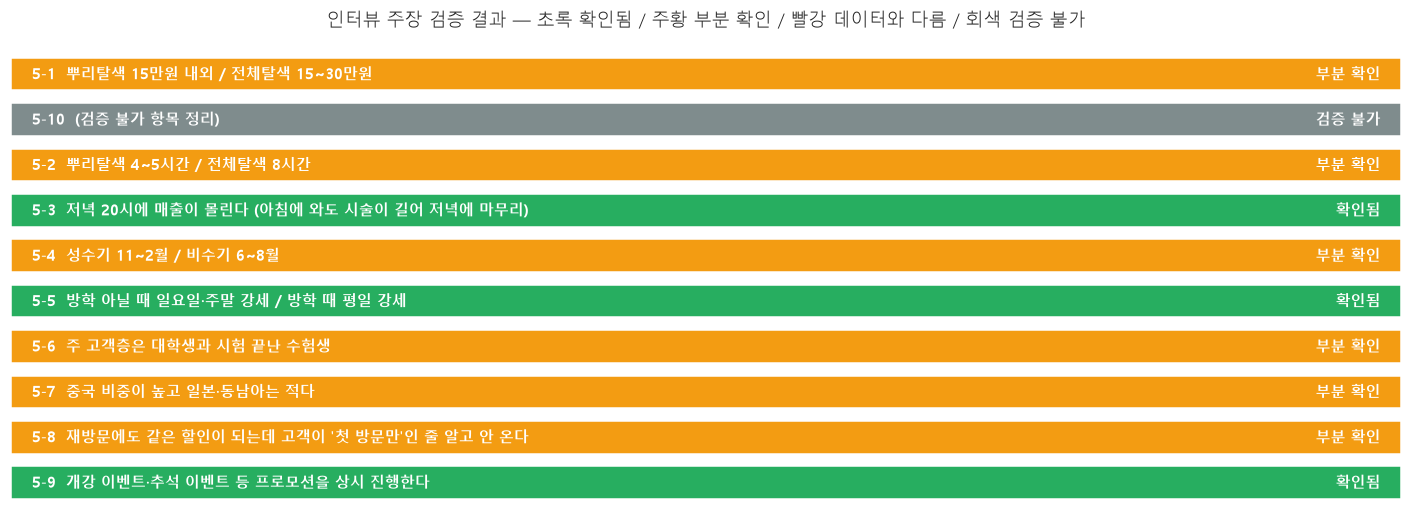

In [64]:
# ── 요약 (1) 그래프: 판정별 색 구분 요약 ─────────────────────────────────────
fig, ax = plt.subplots(figsize=(13, 5))
_vc = {"확인됨": "#27ae60", "부분 확인": "#f39c12", "데이터와 다름": "#c0392b", "검증 불가": "#7f8c8d"}
_y = np.arange(len(INTERVIEW))[::-1]
ax.barh(_y, [1]*len(INTERVIEW), color=[_vc.get(v, "#999") for v in INTERVIEW.판정], height=0.72)
for i, (_, r) in zip(_y, INTERVIEW.iterrows()):
    ax.text(0.015, i, f"{r['번호']}  {r['사장님 주장'][:46]}", va="center", ha="left",
            fontsize=9.5, color="white", fontweight="bold")
    ax.text(0.985, i, r["판정"], va="center", ha="right", fontsize=9.5, color="white", fontweight="bold")
ax.set_xlim(0, 1); ax.set_yticks([]); ax.set_xticks([])
ax.set_title("인터뷰 주장 검증 결과 — 초록 확인됨 / 주황 부분 확인 / 빨강 데이터와 다름 / 회색 검증 불가")
for s in ax.spines.values():
    s.set_visible(False)
ax.grid(False)
plt.tight_layout(); plt.show()

## ⑥ 관측 기준 재평가 — ③의 슬롯 설계를 다시 본다

③ 은 **가정 A(탈색 3.5h)** 와 평일·주말 공통 마감 20:00 으로 슬롯을 판정했고,
그 결과 "16시 탈색 슬롯"을 ★1순위로 올렸다. ⑤-2d 에서 관측 소요시간이 나왔으므로
같은 계산을 **관측 중앙값 + 실제 마감(평일 20:30 / 주말 20:00)** 으로 다시 한다.

**③ 의 셀은 하나도 고치지 않는다.** 두 기준을 나란히 두는 것이 목적이다.

In [65]:
# ── ⑥-1 관측 소요시간으로 '그 시각에 뭘 시작할 수 있나' 를 다시 판정 ─────────
# ③-3/③-5 는 가정 A(탈색 3.5h)와 평일·주말 공통 마감 20:00 을 썼다.
# 여기서는 관측 중앙값과 실제 마감(평일 20:30 / 주말 20:00)으로 다시 낸다.
# ⚠️ ③ 의 셀은 하나도 고치지 않는다. 두 기준을 나란히 두는 것이 목적이다.
CORE4 = ["탈색", "펌", "염색", "컷"]      # 클리닉은 관측 n=4 이고 대부분 무료 부가서비스라 제외
CLOSE_OF_DOW = {d: (CLOSE_WE if d in ("토", "일") else CLOSE_WD) for d in DOW_KO}

def _feasible_obs(h, dow):
    return [c for c in CORE4 if h + DUR_OBS[c] <= CLOSE_OF_DOW[dow] + 1e-9]

LASTSTART = pd.DataFrame(
    [{"시술": c, "관측 중앙값(h)": DUR_OBS[c], "가정 A(h)": DUR_H[c],
      "최종 시작 평일(관측)": CLOSE_WD - DUR_OBS[c],
      "최종 시작 주말(관측)": CLOSE_WE - DUR_OBS[c],
      "최종 시작 ③기준(가정A·20시)": CLOSE_H - DUR_H[c]} for c in CORE4]).set_index("시술")
tbl(LASTSTART.round(2), "⑥-1 마감 역산 — 그 시술을 늦어도 몇 시에 시작해야 하나")
print("읽는 법: 15.10 = 15시 06분. 정시 예약만 받으므로 실제 마지막 슬롯은 그 아래 정시다.")
print(f"→ 탈색은 평일에도 {int(np.floor(CLOSE_WD - DUR_OBS['탈색']))}시가 마지막이다. "
      f"③-5a 가 ★1순위로 올린 **16시 탈색 슬롯은 성립하지 않는다.**")
print(f"   (③ 은 탈색 3.5h·마감 20시로 봐서 {CLOSE_H - DUR_H['탈색']:.1f}시까지 가능하다고 판정했다.)")
print()

# ── ⑥-2 (요일 x 시) 빈 슬롯을 관측 기준으로 다시 채점 ──────────────────────
_s6 = _cell.copy()
_s6["시작가능(관측)"]     = [", ".join(_feasible_obs(h, d)) or "(없음)"
                             for h, d in zip(_s6.hour, _s6.dow_ko)]
_s6["탈색가능(관측)"]     = [("탈색" in _feasible_obs(h, d)) for h, d in zip(_s6.hour, _s6.dow_ko)]
_s6["탈색가능(가정A)"]    = _s6.hour.map(lambda h: _startable(h, DUR_H["탈색"]))

def _maxp_obs(h, d):
    fs = [c for c in _feasible_obs(h, d) if c in _catprice.index]
    return float(_catprice.loc[fs, "median"].max()) if fs else 0.0

_s6["최고 가능 단가(관측)"]  = [_maxp_obs(h, d) for h, d in zip(_s6.hour, _s6.dow_ko)]
_s6["최고 가능 단가(가정A)"] = _s6.hour.map(_max_price)
_s6["빈자리(일당)"]          = (_MEDCELL - _s6["일당 완료건수"]).clip(lower=0)
_s6["잠재 일당매출(관측)"]   = _s6["빈자리(일당)"] * _s6["최고 가능 단가(관측)"]
_s6["잠재 월매출(관측)"]     = _s6["잠재 일당매출(관측)"] * _s6["요일영업일수"] / _N_MONTHS
_s6["슬롯"] = _s6.dow_ko + "요일 " + _s6.hour.astype(str) + "시"

_s6lost = _s6[_s6["탈색가능(가정A)"] & ~_s6["탈색가능(관측)"]]
print(f"가정 A 로는 탈색을 받을 수 있다고 본 (요일x시) 칸 {int(_s6['탈색가능(가정A)'].sum())}개 중 "
      f"{len(_s6lost)}개가 관측 기준으로는 **불가**가 된다:")
for _h6, _g6 in _s6lost.groupby("hour"):
    print(f"   {_h6}시 — {', '.join(_g6.dow_ko)}요일 ({len(_g6)}칸)")
print(f"   15시가 주말만 걸리는 것은 마감이 평일 {CLOSE_WD}시 / 주말 {CLOSE_WE}시로 다르기 때문이다.")
print()

SLOT_OBS = (_s6[(_s6["시작가능(관측)"] != "(없음)") & (_s6["일당 완료건수"] < _MEDCELL)]
              .sort_values("잠재 월매출(관측)", ascending=False)
              [["슬롯", "완료건수", "일당 완료건수", "객단가중앙값", "탈색가능(가정A)", "탈색가능(관측)",
                "최고 가능 단가(가정A)", "최고 가능 단가(관측)", "잠재 월매출(관측)", "시작가능(관측)"]]
              .reset_index(drop=True))
SLOT_OBS.index = range(1, len(SLOT_OBS) + 1)
tbl(SLOT_OBS.head(15).round(2), "⑥-2 ★ 관측 기준 빈 슬롯 재채점 — 잠재 월매출 큰 순 (상위 15)")

_s6track = _s6[_s6.슬롯.isin(list(PROMO_HI["슬롯"]))][
    ["슬롯", "탈색가능(가정A)", "탈색가능(관측)", "최고 가능 단가(가정A)",
     "최고 가능 단가(관측)", "잠재 월매출(관측)", "시작가능(관측)"]]
tbl(_s6track.round(2), "⑥-2b ③-5a 의 ★1순위 슬롯 — 관측 기준으로 다시 보면")
print()

# ── ⑥-3 그러면 16~19시에 실제로 팔 수 있는 것은 무엇인가 ────────────────────
_s6byh = (_s6[_s6["일당 완료건수"] < _MEDCELL].groupby("hour")
            .agg(빈칸수=("슬롯", "size"), 빈자리합_일당=("빈자리(일당)", "sum"),
                 최고단가=("최고 가능 단가(관측)", "max"),
                 잠재_월매출=("잠재 월매출(관측)", "sum")))
_s6byh["시작가능(관측·평일)"] = [", ".join(_feasible_obs(h, "월")) or "(없음)" for h in _s6byh.index]
tbl(_s6byh.round(1), "⑥-3 시각별 빈 슬롯의 실질 가치 — 관측 기준")

_s6ev = _s6byh.loc[[h for h in (16, 17, 18, 19) if h in _s6byh.index]]
print(f"16~19시 빈칸 {int(_s6ev.빈칸수.sum())}개의 잠재 월매출 합계 {_s6ev.잠재_월매출.sum():,.0f}원.")
print(f"이 구간의 최고 가능 단가는 16시 {_s6ev.loc[16,'최고단가']:,.0f}원 → "
      f"19시 {_s6ev.loc[19,'최고단가']:,.0f}원으로 떨어진다.")
print("→ 저녁 슬롯은 **탈색 홍보로는 안 채워진다.** 16시는 펌, 17~18시는 염색, 19시는 컷이 상한이다.")
print()

# ⑥ 에서 만든 실행 후보 (요약(2) 에서 재사용)
SLOT_PLAN = pd.DataFrame([
    {"시간대": "16시", "무엇을 태우나": "펌 (탈색 불가)",
     "근거": f"관측 펌 {DUR_OBS['펌']:.2f}h → 평일 {CLOSE_WD-DUR_OBS['펌']:.2f}시까지 시작 가능",
     "빈칸수": int(_s6byh.loc[16, "빈칸수"]), "최고단가": _s6byh.loc[16, "최고단가"],
     "잠재 월매출": _s6byh.loc[16, "잠재_월매출"]},
    {"시간대": "17~18시", "무엇을 태우나": "염색 단품",
     "근거": f"관측 염색 {DUR_OBS['염색']:.2f}h → 평일 {CLOSE_WD-DUR_OBS['염색']:.2f}시까지",
     "빈칸수": int(_s6byh.loc[[17, 18], "빈칸수"].sum()),
     "최고단가": _s6byh.loc[[17, 18], "최고단가"].max(),
     "잠재 월매출": _s6byh.loc[[17, 18], "잠재_월매출"].sum()},
    {"시간대": "19시", "무엇을 태우나": "컷 단품",
     "근거": f"관측 컷 {DUR_OBS['컷']:.2f}h → 평일 {CLOSE_WD-DUR_OBS['컷']:.2f}시까지",
     "빈칸수": int(_s6byh.loc[19, "빈칸수"]), "최고단가": _s6byh.loc[19, "최고단가"],
     "잠재 월매출": _s6byh.loc[19, "잠재_월매출"]},
]).set_index("시간대").sort_values("잠재 월매출", ascending=False)
tbl(SLOT_PLAN.round(0), "⑥-3b ★ 저녁 슬롯 재설계 후보 — 매출 기여 순")

# ── ⑥-4 캐파 상한을 매출로 환산 — '자리가 있다'와 '팔린다'는 다르다 ──────────
# 아래 두 숫자는 03번 ③-E2d 의 패킹 결과다(관측 소요시간 + 요일별 마감 기준).
# 노트북 간 CSV 의존을 만들지 않으려고 값만 옮겨 적었다. 재현: 03번 ③-E2d 표.
CAP_FLAG_M, CAP_CUT_M = 12.15, 160.20        # 월 추가 가능 건수 (주력 탈색만 / 컷만)
_s6cut = len(DONE[DONE.rep_cat == "컷"]) / _N_MONTHS
_s6bl  = len(DONE[DONE.rep_cat == "탈색"]) / _N_MONTHS
_p_bl, _p_cut = float(_catprice.loc["탈색", "median"]), float(_catprice.loc["컷", "median"])
CAPREV = pd.DataFrame({
    "월 추가 가능(건)": [CAP_FLAG_M, CAP_CUT_M],
    "대표 단가(원)":     [_p_bl, _p_cut],
    "월 추가 매출(원)":  [CAP_FLAG_M * _p_bl, CAP_CUT_M * _p_cut],
    "현재 월 완료(건)":  [_s6bl, _s6cut],
}, index=["주력 탈색으로만 채움", "컷으로만 채움"])
CAPREV["현재 대비 배수"] = CAPREV["월 추가 가능(건)"] / CAPREV["현재 월 완료(건)"]
tbl(CAPREV.round(1), "⑥-4 빈자리를 무엇으로 채우느냐 (03번 ③-E2d 인용) — 건수와 매출이 정반대로 움직인다")
print(f"컷 {CAP_CUT_M:.1f}건/월은 현재 컷 완료 {_s6cut:.1f}건/월의 {CAP_CUT_M/_s6cut:.0f}배다.")
print("**산술적으로만 존재하는 상한**이고 수요 근거가 전혀 없다. 실행 계획의 분모로 쓰면 안 된다.")
print(f"매출로 환산하면 탈색 {CAP_FLAG_M*_p_bl:,.0f}원 vs 컷 {CAP_CUT_M*_p_cut:,.0f}원이지만, "
      f"뒤 숫자는 {CAP_CUT_M/_s6cut:.0f}배 성장을 전제한다.")
print()
print("=" * 92)
print("⑥ 결론 — ③의 슬롯 설계에서 바뀌는 것")
print("=" * 92)
print(f"  1) ★1순위 '16시 탈색 슬롯'은 **성립하지 않는다.** 탈색 최종 시작은 평일 "
      f"{CLOSE_WD - DUR_OBS['탈색']:.2f}시이고, 주력 뿌리탈색이벤트(관측 4.88h)로 봐도 15시대다.")
print(f"  2) 16시의 실질 상한은 펌 {_catprice.loc['펌','median']:,.0f}원, "
      f"17~18시는 염색 {_catprice.loc['염색','median']:,.0f}원, 19시는 컷 {_catprice.loc['컷','median']:,.0f}원.")
print(f"  3) 탈색까지 받을 수 있는 빈칸은 관측 기준 "
      f"{int(((_s6['탈색가능(관측)']) & (_s6['일당 완료건수'] < _MEDCELL)).sum())}칸으로 줄어든다 "
      f"(가정 A 기준 {len(PROMO_HI)}칸).")
print("  4) 저녁 슬롯 프로모션은 '후순위'가 아니라 **성격이 다른 별도 상품**으로 다뤄야 한다.")
print("     탈색 손님을 저녁으로 옮기는 것은 물리적으로 불가능하다.")
print("  ⚠️ 펌은 관측 n=20(참고 수준)이다. 16시 펌 슬롯은 근거 강도가 탈색·염색보다 약하다.")
print("=" * 92)


**⑥-1 마감 역산 — 그 시술을 늦어도 몇 시에 시작해야 하나**

,관측 중앙값(h),가정 A(h),최종 시작 평일(관측),최종 시작 주말(관측),최종 시작 ③기준(가정A·20시)
시술,,,,,
탈색,5.40,3.50,15.10,14.60,16.50
펌,3.76,2.50,16.74,16.24,17.50
염색,2.07,1.17,18.43,17.93,18.83
컷,1.05,0.67,19.45,18.95,19.33


읽는 법: 15.10 = 15시 06분. 정시 예약만 받으므로 실제 마지막 슬롯은 그 아래 정시다.
→ 탈색은 평일에도 15시가 마지막이다. ③-5a 가 ★1순위로 올린 **16시 탈색 슬롯은 성립하지 않는다.**
   (③ 은 탈색 3.5h·마감 20시로 봐서 16.5시까지 가능하다고 판정했다.)



가정 A 로는 탈색을 받을 수 있다고 본 (요일x시) 칸 49개 중 9개가 관측 기준으로는 **불가**가 된다:
   15시 — 토, 일요일 (2칸)
   16시 — 월, 화, 수, 목, 금, 토, 일요일 (7칸)
   15시가 주말만 걸리는 것은 마감이 평일 20.5시 / 주말 20.0시로 다르기 때문이다.



**⑥-2 ★ 관측 기준 빈 슬롯 재채점 — 잠재 월매출 큰 순 (상위 15)**

...

**⑥-3b ★ 저녁 슬롯 재설계 후보 — 매출 기여 순**

,무엇을 태우나,근거,빈칸수,최고단가,잠재 월매출
시간대,,,,,
16시,펌 (탈색 불가),관측 펌 3.76h → 평일 16.74시까지 시작 가능,7,120000.0,357704.0
17~18시,염색 단품,관측 염색 2.07h → 평일 18.43시까지,11,39000.0,229795.0
19시,컷 단품,관측 컷 1.05h → 평일 19.45시까지,7,29000.0,149189.0


**⑥-4 빈자리를 무엇으로 채우느냐 (03번 ③-E2d 인용) — 건수와 매출이 정반대로 움직인다**

,월 추가 가능(건),대표 단가(원),월 추가 매출(원),현재 월 완료(건),현재 대비 배수
주력 탈색으로만 채움,12.2,150000.0,1822500.0,80.4,0.2
컷으로만 채움,160.2,29000.0,4645800.0,11.2,14.3


컷 160.2건/월은 현재 컷 완료 11.2건/월의 14배다.
**산술적으로만 존재하는 상한**이고 수요 근거가 전혀 없다. 실행 계획의 분모로 쓰면 안 된다.
매출로 환산하면 탈색 1,822,500원 vs 컷 4,645,800원이지만, 뒤 숫자는 14배 성장을 전제한다.

⑥ 결론 — ③의 슬롯 설계에서 바뀌는 것
  1) ★1순위 '16시 탈색 슬롯'은 **성립하지 않는다.** 탈색 최종 시작은 평일 15.10시이고, 주력 뿌리탈색이벤트(관측 4.88h)로 봐도 15시대다.
  2) 16시의 실질 상한은 펌 120,000원, 17~18시는 염색 39,000원, 19시는 컷 29,000원.
  3) 탈색까지 받을 수 있는 빈칸은 관측 기준 6칸으로 줄어든다 (가정 A 기준 13칸).
  4) 저녁 슬롯 프로모션은 '후순위'가 아니라 **성격이 다른 별도 상품**으로 다뤄야 한다.
     탈색 손님을 저녁으로 옮기는 것은 물리적으로 불가능하다.
  ⚠️ 펌은 관측 n=20(참고 수준)이다. 16시 펌 슬롯은 근거 강도가 탈색·염색보다 약하다.


---
# 요약 (2) — 실행 후보표

①~④에서 나온 것 중 **원장님이 바로 할 수 있는 것**만 모았다.
**무엇을 / 근거 숫자 / 예상 대상 규모 / 비용**.

* ③의 (요일, 시간) 프로모션 슬롯과 ④의 "매출 크고 재방문 낮은" 시술을 반드시 포함했다.
* **비용은 정성 표기다.** 광고 집행액 데이터가 저장소에 없어 금액으로 환산할 수 없다(⑤-10 참조).
* 여기 적힌 것은 전부 **상관 관계**다. "A 때문에 B"가 아니라 "A와 B가 같이 움직인다"로 읽어야 한다.

In [66]:
# ── 요약 (2) 실행 후보표 ─────────────────────────────────────────────────────
ACTIONS = []
def act(what, basis, scale, cost, src, recheck=""):
    ACTIONS.append({"무엇을": what, "근거 숫자": basis, "예상 대상 규모": scale,
                    "비용": cost, "출처": src, "관측 기준 재평가": recheck})

# --- ③ 프로모션 슬롯 (요일 x 시간) — 고단가 먼저 ---
_hi = PROMO_HI.head(5)
_hi_txt = " · ".join(f"{r['슬롯']}({r['일당 완료건수']:.2f}건/일, 객단가중앙 {r['객단가중앙값']:,.0f}원)"
                     for _, r in _hi.iterrows())
act("★[1순위] 탈색까지 받을 수 있는데 비어 있는 (요일,시) 슬롯에 한정 프로모션",
    f"고단가 빈 슬롯 {len(PROMO_HI)}칸 중 잠재매출 상위 5칸: {_hi_txt}. "
    f"전체 (요일x시) 중앙값 {_MEDCELL:.2f}건/일 · 이 시각 최고 가능 단가 {_hi['최고 가능 단가'].max():,.0f}원",
    f"슬롯당 주 1회 x 5칸 = 월 약 20회분 빈자리 (잠재 일당매출 상한 합 "
    f"{_hi['잠재 일당매출 상한'].sum():,.0f}원/일)",
    "광고비 또는 슬롯 한정 할인", "③-5a")

_lo = PROMO_LO.head(5)
_lo_txt = " · ".join(f"{r['슬롯']}({r['일당 완료건수']:.2f}건/일)" for _, r in _lo.iterrows())
act("[후순위] 마감이 가까워 짧은 시술만 가능한 저녁 슬롯 — 컷·염색 단품으로만",
    f"가장 빈 5칸: {_lo_txt}. 이 시각은 탈색(3.5h)을 시작할 수 없어 "
    f"최고 가능 단가가 {_lo['최고 가능 단가'].max():,.0f}원에 그친다",
    f"5개 슬롯 · 완료 {int(_lo.완료건수.sum())}건",
    "광고비 (회수 기대치 낮음)", "③-5b")

_gap_h = _h[_h.유형 == "공백(수요)"]
if len(_gap_h):
    _gh = ", ".join(f"{h}시" for h in _gap_h.index)
    act("'공백(수요)' 시간대 집중 — 물리적으로 받을 수 있는데 비어 있는 시각",
        f"{_gh} — 완료 {int(_gap_h.완료건수.sum()):,}건, 영업일당 {_gap_h['영업일당 완료'].sum():.2f}건, "
        f"이 시각에 시작 가능: {_gap_h['시작가능 시술'].iloc[0]}",
        f"영업일 {N_BIZ}일 x 시간대 {len(_gap_h)}개",
        "광고비", "③-3")

_ineff = _h[_h.유형 == "저효율"]
if len(_ineff):
    act("'저효율' 시간대 상향 판매 — 사람은 오는데 단가가 낮은 시각",
        f"{', '.join(str(h)+'시' for h in _ineff.index)} — 객단가 중앙값 "
        f"{_ineff.객단가중앙값.min():,.0f}~{_ineff.객단가중앙값.max():,.0f}원 "
        f"(전체 중앙값 {MED_PRICE:,.0f}원)",
        f"완료 {int(_ineff.완료건수.sum()):,}건",
        "운영 변경(메뉴 제안)만", "③-3")

# --- ④ 매출 크고 재방문 낮은 시술 ---
for cat in _star.index:
    r = _star.loc[cat]
    cyc = _cyc.loc[cat] if cat in _cyc.index else None
    act(f"[{cat}] 재방문 개입 — 매출은 큰데 재방문이 낮다",
        f"매출 비중 {r['매출 비중(%)']:.2f}% (완료 {int(r['완료 건수']):,}건) · "
        f"첫 방문 {cat} 고객 재방문율 {r['재방문율(2회+,%)']:.2f}% (3회+ {r['3회이상(%)']:.2f}%) · "
        f"중앙값 대비 재방문 {r['재방문율(2회+,%)']-_y0:+.2f}%p",
        f"첫 방문이 {cat}인 고객 {int(r['인원']):,}명",
        "메시지 발송비", "④-d")

# --- ④-c 시술별 리텐션 안내 시점 ---
_ret = _cyc[_cyc.쌍수 >= 30]
if len(_ret):
    _txt = " · ".join(f"{c} +{_ret.loc[c,'안내 최적일(중앙값−3)']:.0f}일" for c in _ret.index)
    act("시술별 재방문 안내 시점 차등화 (일괄 발송 대신)",
        f"직전 시술별 재방문 간격 중앙값이 다르다 — {_txt} (전체 중앙값 {PAIRS.gap_days.median():.0f}일)",
        f"쌍 30개 이상 확보된 {len(_ret)}개 시술 · 완료 기준 고객 {len(CUST):,}명",
        "메시지 발송비", "④-c")

# --- ⑤-8 재방문 할인 고지 ---
act("재방문에도 할인이 적용된다는 사실을 2회차 예약 시점에 고지",
    f"할인 채널 첫 방문 고객 {len(_first50):,}명 중 2회차 발생 {len(_second):,}명, "
    f"그중 2회차에 이 채널을 다시 쓴 사람은 {_reuse.mean()*100:.1f}%뿐. "
    f"결제금액 중앙값 {_first50.첫방문paid.median():,.0f}원 → {_second.paid.median():,.0f}원으로 상승",
    f"할인 채널 첫 방문 고객 {len(_first50):,}명",
    "고지 문구 수정(무료) + 메시지 발송비", "⑤-8")

# --- ① 취소 대응 ---
act("방문 6시간 이내 취소에 한해 리마인드·확인 강화",
    f"진짜 손실 {len(_loss):,}건 · {_loss.paid.sum():,}원 (월 {len(_loss)/_N_MONTHS:.1f}건 · "
    f"{_loss.paid.sum()/_N_MONTHS:,.0f}원). 전체 취소 {len(CANC):,}건 중 {len(_loss)/len(CANC)*100:.1f}%",
    f"월 {len(_loss)/_N_MONTHS:.1f}건",
    "리마인드 발송비", "①-d")

_ld = R.groupby("lead_bin", observed=False).agg(n=("예약번호", "size"),
                                                c=("status", lambda s: int((s == "취소").sum())))
_ld["r"] = _ld.c / _ld.n * 100
act("리드타임 2주 이상 예약에 중간 확인 넣기",
    f"2주 이상 예약의 취소율 {_ld.loc['2주 이상','r']:.2f}% (6시간 미만 {_ld.loc['6시간 미만','r']:.2f}%의 "
    f"{_ld.loc['2주 이상','r']/_ld.loc['6시간 미만','r']:.1f}배). 해당 예약 {int(_ld.loc['2주 이상','n']):,}건",
    f"{int(_ld.loc['2주 이상','n']):,}건 ({_ld.loc['2주 이상','n']/len(R)*100:.1f}%)",
    "리마인드 발송비", "①-e3")

# --- ② 요일 ---
act(f"매출 하위 요일({_idle_m}) 대상 프로모션 / 상위 요일({_busy_m}) 슬롯 보호",
    f"요일 1일당 매출 — 최고 {_busy_m} {_rank.loc[_busy_m,'요일1회당 매출']:,.0f}원 vs "
    f"최저 {_idle_m} {_rank.loc[_idle_m,'요일1회당 매출']:,.0f}원 "
    f"({_rank.loc[_busy_m,'요일1회당 매출']/_rank.loc[_idle_m,'요일1회당 매출']:.2f}배)",
    f"{_idle_m}요일 영업일 {int(_dw.loc[_idle_m,'영업일수'])}일",
    "광고비 또는 요일 한정 할인", "②-4")

# --- ⑥ 관측 기준으로 새로 성립하는 슬롯 (③-5a 를 대체하는 것들) ---
for _sh, _sr in SLOT_PLAN.iterrows():
    act(f"[{_sh}] {_sr['무엇을 태우나']} — 관측 마감 역산으로 '실제 넣을 수 있는 것'만 태운다",
        f"{_sr['근거']}. 빈칸 {int(_sr['빈칸수'])}개 · 그 시각 최고 가능 단가 {_sr['최고단가']:,.0f}원",
        f"잠재 월매출 상한 {_sr['잠재 월매출']:,.0f}원 (빈자리 x 최고 단가)",
        "슬롯 한정 할인 또는 단품 상품화", "⑥-3b",
        "신규 — ③-5a 의 '16시 탈색 슬롯'을 대체한다")

ACTION = pd.DataFrame(ACTIONS)
ACTION.index = range(1, len(ACTION) + 1)

# --- 관측 기준 재평가 열 — 항목은 하나도 지우지 않고 열만 붙인다 -------------
def _recheck(r):
    if r["관측 기준 재평가"]:
        return r["관측 기준 재평가"]
    s, w = r["출처"], r["무엇을"]
    if s == "③-5a":
        return (f"**성립 불가** — 관측 탈색 {DUR_OBS['탈색']:.2f}h 이므로 평일 최종 시작 "
                f"{CLOSE_WD - DUR_OBS['탈색']:.2f}시. 16시에 탈색을 넣을 수 없다. 그 시각 실질 상한은 "
                f"펌 {_catprice.loc['펌','median']:,.0f}원 (⑥-1·⑥-2b)")
    if s == "③-5b":
        return ("**유효 — 다만 '후순위'가 아니라 별도 상품.** 관측 기준으로도 저녁은 짧은 시술만 "
                "가능하다. 탈색 손님을 저녁으로 옮기는 것은 물리적으로 불가능하므로 '채우면 좋은 자리'가 "
                "아니라 '다른 상품이 필요한 자리'다 (⑥-3)")
    if s == "③-3" and w.startswith("'공백(수요)'"):
        return (f"**16시는 '공백(수요)'가 아니다** — 관측 기준으로는 탈색을 시작할 수 없는 시각이다. "
                f"수요가 없는 게 아니라 긴 시술이 안 들어간다 (⑥-1)")
    if s == "③-3":
        return "변동 없음 — 단가 문제이지 소요시간 문제가 아니다"
    return "변동 없음 — 소요시간·마감과 무관"

ACTION["관측 기준 재평가"] = ACTION.apply(_recheck, axis=1)
with pd.option_context("display.max_colwidth", 190):
    display(ACTION)
print(f"\n실행 후보 {len(ACTION)}건 (③ 항목은 하나도 지우지 않고 '관측 기준 재평가' 열만 붙였다)")

# --- 매출 기여로 재정렬 — 금액이 산출되는 항목만 -----------------------------
_rk = [{"항목": f"[{_sh}] {_sr['무엇을 태우나']}", "월 매출기여(추정, 원)": float(_sr["잠재 월매출"]),
        "성격": "빈자리 x 그 시각 최고 가능 단가 (상한)", "근거": "⑥-3b"}
       for _sh, _sr in SLOT_PLAN.iterrows()]
_rk.append({"항목": "[③-5a] 16시 탈색 슬롯 (기존 ★1순위)", "월 매출기여(추정, 원)": 0.0,
            "성격": "관측 기준 성립 불가 — 탈색을 시작할 수 없다", "근거": "⑥-1"})
_rk.append({"항목": "[캐파 상한] 주력 탈색으로만 채움",
            "월 매출기여(추정, 원)": float(CAPREV.loc["주력 탈색으로만 채움", "월 추가 매출(원)"]),
            "성격": f"03번 ③-E2d 패킹 상한 (월 {CAP_FLAG_M:.1f}건)", "근거": "⑥-4"})
_rk.append({"항목": "[캐파 상한] 컷으로만 채움",
            "월 매출기여(추정, 원)": float(CAPREV.loc["컷으로만 채움", "월 추가 매출(원)"]),
            "성격": f"현재 컷 완료의 {CAPREV.loc['컷으로만 채움','현재 대비 배수']:.0f}배 — 산술 상한일 뿐",
            "근거": "⑥-4"})
ACTION_RANK = (pd.DataFrame(_rk).sort_values("월 매출기여(추정, 원)", ascending=False)
                 .reset_index(drop=True))
ACTION_RANK.index = range(1, len(ACTION_RANK) + 1)
with pd.option_context("display.max_colwidth", 120):
    display(ACTION_RANK.round(0))
print("⚠️ 전부 **공급 측 상한**이다. 그 시각에 손님이 온다는 근거는 어디에도 없다.")
print("   특히 '컷으로만 채움'은 현재의 수십 배 성장을 전제하므로 계획의 분모로 쓰면 안 된다.")
print("   나머지 실행 후보(재방문·취소·요일)는 소요시간과 무관해 금액 산출 대상이 아니다.")

,무엇을,근거 숫자,예상 대상 규모,비용,출처,관측 기준 재평가
1,"★[1순위] 탈색까지 받을 수 있는데 비어 있는 (요일,시) 슬롯에 한정 프로모션","고단가 빈 슬롯 13칸 중 잠재매출 상위 5칸: 화요일 16시(0.20건/일, 객단가중앙 125,000원) · 월요일 16시(0.32건/일, 객단가중앙 88,000원) · 수요일 16시(0.34건/일, 객단가중앙 100,000원) · 토요일 16시(0.35건/일, 객단가중앙 100,000원) · 목요일 16시(0.36건/일, 객단가중앙 100,000원). 전체 (요일x시) 중앙값 0.43건/일 · 이 시각 최고 가능 단가 150,000원","슬롯당 주 1회 x 5칸 = 월 약 20회분 빈자리 (잠재 일당매출 상한 합 89,484원/일)",광고비 또는 슬롯 한정 할인,③-5a,"**성립 불가** — 관측 탈색 5.40h 이므로 평일 최종 시작 15.10시. 16시에 탈색을 넣을 수 없다. 그 시각 실질 상한은 펌 120,000원 (⑥-1·⑥-2b)"
2,[후순위] 마감이 가까워 짧은 시술만 가능한 저녁 슬롯 — 컷·염색 단품으로만,"가장 빈 5칸: 토요일 19시(0.06건/일) · 일요일 19시(0.06건/일) · 목요일 19시(0.13건/일) · 수요일 19시(0.16건/일) · 화요일 19시(0.17건/일). 이 시각은 탈색(3.5h)을 시작할 수 없어 최고 가능 단가가 29,000원에 그친다",5개 슬롯 · 완료 48건,광고비 (회수 기대치 낮음),③-5b,**유효 — 다만 '후순위'가 아니라 별도 상품.** 관측 기준으로도 저녁은 짧은 시술만 가능하다. 탈색 손님을 저녁으로 옮기는 것은 물리적으로 불가능하므로 '채우면 좋은 자리'가 아니라 '다른 상품이 필요한 자리'다 (⑥-3)
3,'공백(수요)' 시간대 집중 — 물리적으로 받을 수 있는데 비어 있는 시각,"16시 — 완료 191건, 영업일당 0.33건, 이 시각에 시작 가능: 탈색, 펌, 염색, 컷",영업일 580일 x 시간대 1개,광고비,③-3,**16시는 '공백(수요)'가 아니다** — 관측 기준으로는 탈색을 시작할 수 없는 시각이다. 수요가 없는 게 아니라 긴 시술이 안 들어간다 (⑥-1)
4,[탈색] 재방문 개입 — 매출은 큰데 재방문이 낮다,"매출 비중 76.01% (완료 1,607건) · 첫 방문 탈색 고객 재방문율 22.77% (3회+ 7.65%) · 중앙값 대비 재방문 -4.43%p","첫 방문이 탈색인 고객 1,190명",메시지 발송비,④-d,변동 없음 — 소요시간·마감과 무관
5,시술별 재방문 안내 시점 차등화 (일괄 발송 대신),직전 시술별 재방문 간격 중앙값이 다르다 — 탈색 +47일 · 펌 +43일 · 염색 +32일 · 컷 +32일 (전체 중앙값 41일),"쌍 30개 이상 확보된 4개 시술 · 완료 기준 고객 1,557명",메시지 발송비,④-c,변동 없음 — 소요시간·마감과 무관
6,재방문에도 할인이 적용된다는 사실을 2회차 예약 시점에 고지,"할인 채널 첫 방문 고객 170명 중 2회차 발생 56명, 그중 2회차에 이 채널을 다시 쓴 사람은 19.6%뿐. 결제금액 중앙값 100,000원 → 150,000원으로 상승",할인 채널 첫 방문 고객 170명,고지 문구 수정(무료) + 메시지 발송비,⑤-8,변동 없음 — 소요시간·마감과 무관
7,방문 6시간 이내 취소에 한해 리마인드·확인 강화,"진짜 손실 151건 · 16,307,000원 (월 7.5건 · 815,350원). 전체 취소 1,542건 중 9.8%",월 7.5건,리마인드 발송비,①-d,변동 없음 — 소요시간·마감과 무관
8,리드타임 2주 이상 예약에 중간 확인 넣기,2주 이상 예약의 취소율 69.44% (6시간 미만 14.87%의 4.7배). 해당 예약 337건,337건 (7.9%),리마인드 발송비,①-e3,변동 없음 — 소요시간·마감과 무관
9,매출 하위 요일(일) 대상 프로모션 / 상위 요일(금) 슬롯 보호,"요일 1일당 매출 — 최고 금 719,970원 vs 최저 일 423,944원 (1.70배)",일요일 영업일 81일,광고비 또는 요일 한정 할인,②-4,변동 없음 — 소요시간·마감과 무관
10,[16시] 펌 (탈색 불가) — 관측 마감 역산으로 '실제 넣을 수 있는 것'만 태운다,"관측 펌 3.76h → 평일 16.74시까지 시작 가능. 빈칸 7개 · 그 시각 최고 가능 단가 120,000원","잠재 월매출 상한 357,704원 (빈자리 x 최고 단가)",슬롯 한정 할인 또는 단품 상품화,⑥-3b,신규 — ③-5a 의 '16시 탈색 슬롯'을 대체한다



실행 후보 12건 (③ 항목은 하나도 지우지 않고 '관측 기준 재평가' 열만 붙였다)


,항목,"월 매출기여(추정, 원)",성격,근거
1,[캐파 상한] 컷으로만 채움,4645800.0,현재 컷 완료의 14배 — 산술 상한일 뿐,⑥-4
2,[캐파 상한] 주력 탈색으로만 채움,1822500.0,03번 ③-E2d 패킹 상한 (월 12.2건),⑥-4
3,[16시] 펌 (탈색 불가),357704.0,빈자리 x 그 시각 최고 가능 단가 (상한),⑥-3b
4,[17~18시] 염색 단품,229795.0,빈자리 x 그 시각 최고 가능 단가 (상한),⑥-3b
5,[19시] 컷 단품,149189.0,빈자리 x 그 시각 최고 가능 단가 (상한),⑥-3b
6,[③-5a] 16시 탈색 슬롯 (기존 ★1순위),0.0,관측 기준 성립 불가 — 탈색을 시작할 수 없다,⑥-1


⚠️ 전부 **공급 측 상한**이다. 그 시각에 손님이 온다는 근거는 어디에도 없다.
   특히 '컷으로만 채움'은 현재의 수십 배 성장을 전제하므로 계획의 분모로 쓰면 안 된다.
   나머지 실행 후보(재방문·취소·요일)는 소요시간과 무관해 금액 산출 대상이 아니다.


In [67]:
# ── 최종 산출물 CSV 저장 ─────────────────────────────────────────────────────
INTERVIEW.to_csv("interview_verdicts.csv", encoding="utf-8-sig")
ACTION.to_csv("action_candidates.csv", encoding="utf-8-sig")
PROMO.to_csv("promo_slots.csv", encoding="utf-8-sig")
PROMO_HI.to_csv("promo_slots_high_value.csv", encoding="utf-8-sig")
print("저장:", Path("interview_verdicts.csv"))
print("저장:", Path("action_candidates.csv"))
print("저장:", Path("promo_slots.csv"))
print("저장:", Path("promo_slots_high_value.csv"))

저장: interview_verdicts.csv
저장: action_candidates.csv
저장: promo_slots.csv
저장: promo_slots_high_value.csv


---
## 이 노트북을 읽을 때의 한계

1. **관측이 20개월뿐이다.** 계절성(⑤-4)은 2025년 9~12월이 1회 관측이라 결론을 낼 수 없다.
2. **2026년 상반기는 중국 단체관광 무비자(2025-09~2026-06)와 겹친다.** 성장분을 계절·마케팅 효과와
   분리하려면 interrupted time series 가 필요하고, 이 노트북에서는 하지 않았다.
3. **시술 소요시간은 가정값이다.** ⑤-2의 가동률은 전적으로 이 가정에 달려 있어 민감도 표를 같이 봐야 한다.
4. **인과가 아니다.** 여기 나오는 모든 관계는 상관이다. 개입 효과를 알려면 A/B 또는 전후 비교가 필요하다.
5. **소표본이 많다.** `⚠소표본` 이 붙은 행(30건 미만)은 방향 참고용이며 비율로 말하면 안 된다.
6. **네이버 데이터는 2025-01부터다.** 살롱은 14.5년차라 2025년 초 "첫 방문"의 상당수는 실제로는 기존 단골이다.